# From Forecasts to Policies: Inventory Planning with Lead Times

In the first post, ["From Forecasts to Decisions: Inventory Planning with Probabilistic Programming"](https://juanitorduz.github.io/forecast_to_decision/), we sold one product and decided today how many units to order for each of the next $15$ days. We turned the posterior predictive draws of a demand model into demand scenarios and ran an inventory simulator on them. Then we chose the orders that minimize a loss with two unit costs: a holding cost per unit left over and a lost margin per unit of demand that we cannot serve.

That problem had two simplifications, and the first post lists both among its limitations. Every order arrived on the day we planned it for, and all $15$ orders were fixed on day one. In practice a delivery takes time, and we place an order every day, after we see what is left on the shelf. In the VN2 challenge described by [Szabłowski (2026)](https://arxiv.org/abs/2601.18919), which motivated the first post, a delivery takes two weeks.

In this notebook we remove both simplifications.

First, an order placed on day $t$ arrives at the start of day $t + L$, where $L$ is the *lead time*. Second, the order of each day is a function of what we have observed up to that day. We call such a function a *policy*, and we call a vector of orders fixed in advance a *plan*.

We compare four ways of placing the orders, the plan of the first post and three policies:

- **Fixed plan.** This is the expected cost plan of the first post, now with a lead time. It does not use anything that happens after day one.
- **Base-stock policy.** On every day it orders the difference between a target level and the stock that is on the shelf or on its way. It has one target level per day.
- **Neural policy.** A small neural network adds a correction to the target level of the base-stock policy. The correction depends on the stock, the orders on their way and the demand of the last week.
- **Rolling horizon.** On every day it updates the forecast with the demand of the day before, solves the fixed plan again for the remaining days and places only the first order. The first post names this procedure as the practical version of its problem.

The simulator of the first post is a `jax.lax.scan` over the days, and JAX differentiates through it. So we can train a policy in the same way we solved for the plan: we write the order of each day as `policy(params, observation)` inside the scan and run gradient descent on the parameters over the demand scenarios. [Alvo et al. (2023)](https://arxiv.org/abs/2306.11246) call this approach hindsight differentiable policy optimization and test it on a range of inventory problems.

We want to answer three questions, for lead times of zero to three days:

1. How much of the expected loss of the fixed plan do we remove when the order of each day depends on the stock that we observe?
2. Does the demand that we observe inside the horizon lower the loss further?
3. Does a daily update of the forecast, followed by a new solve, do better than a policy that we train once?

We keep the data, the forecasting model, the costs and the initial stock of the first post. A policy needs an objective to train on, and of the four decision rules of the first post the expected cost rule and the conditional value at risk (CVaR) rule provide one. We use the first one everywhere and the second one in the *Tail Risk* section.

We also make two assumptions that favor the policies, and we come back to them in the *Model Limitations* section. First, we observe the demand of a day even when the shelf was empty, while in practice we only see the sales. Second, every scenario starts from the same history and the same stock, so we train the policies for these $15$ days only.

We assume that you have read the first post. We recall its terms when we use them, and we do not repeat the derivation of the loss, the forecasting model or its diagnostics.

Here is the outline:

1. **Prepare Notebook.** Imports and plotting defaults.
2. **The Decision Problem.** The lead time, the days on which we count the cost, and the four ways of placing the orders.
3. **Demand Scenarios.** The data and the forecasting model of the first post, and the scenario sets for training, validation and testing.
4. **Inventory Simulator.** The simulator with a lead time, in which a policy places the order of each day.
5. **Policy Training.** The fixed plan, the base-stock policy and the neural policy, which we train by gradient descent through the simulator.
6. **Rolling Horizon.** A particle filter that updates the forecast every day, and the daily solve.
7. **Out of Sample Evaluation.** The expected loss by lead time, the paired differences, the demand history, the rolling horizon, the stock and the stockouts, the cost ratio and the tail risk.
8. **Conclusion.** What we learned.
9. **Next Steps.** Extensions.

## Prepare Notebook

In [1]:
from collections.abc import Callable
from enum import StrEnum
from typing import NamedTuple

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
import polars as pl
import preliz as pz
import seaborn as sns
import xarray as xr
from jax import random
from jax.scipy.special import logsumexp
from jaxtyping import Array, Float, Int, PRNGKeyArray, PyTree, ScalarLike, UInt32
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, PercentFormatter
from numpyro.distributions import Distribution
from numpyro.handlers import do
from numpyro.infer import MCMC, NUTS, Predictive
from numpyro.infer.reparam import LocScaleReparam
from numpyro_forecast import Horizon, forecast, innovations, predict, to_datatree
from numpyro_forecast.features import fourier_features
from numpyro_forecast.metrics import crps_empirical

numpyro.set_host_device_count(4)

seed: int = 42
rng_key: PRNGKeyArray = random.PRNGKey(seed)

CI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "eti"
az.rcParams["stats.ci_prob"] = CI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

## The Decision Problem

Let's start with the setting of the first post. Let $H = 15$ be the **number of days on which we order**, the planning horizon of the first post, and let $D_t$ be the **demand on day** $t$. We start with $I_0$ units on the shelf. Customers buy what is there and go elsewhere for the rest, so the demand that we cannot serve is lost.

Two unit costs define the loss. A unit that sits on the shelf at the end of a day costs the **holding cost** $h$, and a unit of demand that we cannot serve costs the **lost margin** $p$. As in the first post we take $h = 0.1$, $p = 2$ and $I_0 = 50$.

### Lead Time

Let $L \geq 0$ be the **lead time** in days and let $a_t \geq 0$ be the **order placed on day** $t$. The order arrives at the start of day $t + L$. The orders that we have placed and that have not arrived yet are the **pipeline**.

Note that in the first post the letter $L$ was the loss. Here $L$ is the lead time, as is usual in inventory theory, and we write $C$ for the loss and $J$ for the expected loss.

A day $t$ has five steps:

1. **Receive.** For $L \geq 1$ the order placed on day $t - L$ arrives.
2. **Observe.** We look at the stock, the pipeline and the demand of the last days.
3. **Order.** If $t \leq H$ we place the order $a_t$. For $L = 0$ it arrives at once.
4. **Sell.** The demand $D_t$ arrives and we sell what the shelf allows.
5. **Pay.** We pay the holding cost on the units left over and the lost margin on the demand that we could not serve.

Let $I_{t-1}$ be the **stock on hand** at the end of day $t - 1$. The **stock available** for sale on day $t$ is $y_t = I_{t-1} + a_{t-L}$, the stock on hand plus the order that arrives. With $L = 0$ this is $y_t = I_{t-1} + a_t$, the setting of the first post. The **lost sales** $U_t$ and the stock on hand at the end of the day are

$$
U_t = (D_t - y_t)^{+}, \qquad I_t = (y_t - D_t)^{+},
$$

where $(u)^{+} = \max(u, 0)$, and the cost of the day is $h \, I_t + p \, U_t$.

For $L \geq 1$ the orders $a_{1-L}, \dots, a_0$ were placed before day one. They are the **initial pipeline**. We fix each of them at the median forecast of the demand of the day on which it arrives, and we use the same initial pipeline for every policy.

The **inventory position** is the stock on hand plus the pipeline when we decide the order of day $t$, after the arrival of step $1$:

$$
\text{IP}_t = I_{t-1} + \sum_{s=t-L}^{t-1} a_s.
$$

With $L = 0$ the sum is empty and the inventory position is the stock on hand.

### Cost Window

An order placed on day $t$ cannot change anything before day $t + L$. This has two consequences.

- **First days.** The stock of days $1$ to $L$ depends only on the initial stock, the initial pipeline and the demand. No order can change it, so the cost of these days is the same for every policy.
- **Last orders.** The orders of the last $L$ ordering days arrive after day $H$. If we stopped counting on day $H$, these orders would cost nothing and serve nothing.

So we count the cost on the days $L + 1, \dots, H + L$, the **cost window**. It has $H$ days for every lead time, and every order arrives inside it. The **loss** $C$ of a demand path is the sum of the daily costs over the cost window,

$$
C = \sum_{t=L+1}^{H+L} \left[ h \, I_t + p \, U_t \right].
$$

As in the first post, we report the loss as a plain number, in the currency of $h$ and $p$.

We store the lengths and the lead times in the `Setup` tuple of the first post, which gets two new fields, and the costs and the initial stock in the `InventoryConfig` tuple.

In [2]:
class Setup(NamedTuple):
    """Lengths of the history and the horizon, promotion settings and lead times."""

    t_obs: int = 364  # one year of daily history
    horizon: int = 15  # days on which we place an order
    discount: float = 0.3  # price cut in a promotion week
    promo_prob: float = 0.1  # chance that a given week of the history is a promotion
    lead_times: tuple[int, ...] = (0, 1, 2, 3)  # days between an order and its arrival
    history_window: int = 7  # days of past demand that a policy observes

    @property
    def duration(self) -> int:
        return self.t_obs + self.horizon

    @property
    def max_days(self) -> int:
        """Days that we simulate for the longest lead time."""
        return self.horizon + max(self.lead_times)


class InventoryConfig(NamedTuple):
    """Costs and initial stock of the inventory problem."""

    holding_cost: float
    lost_sales_cost: float
    initial_inventory: float


setup = Setup()
config = InventoryConfig(holding_cost=0.1, lost_sales_cost=2.0, initial_inventory=50.0)

The next figure shows, for each lead time, the days on which we order and the days on which we count the cost.

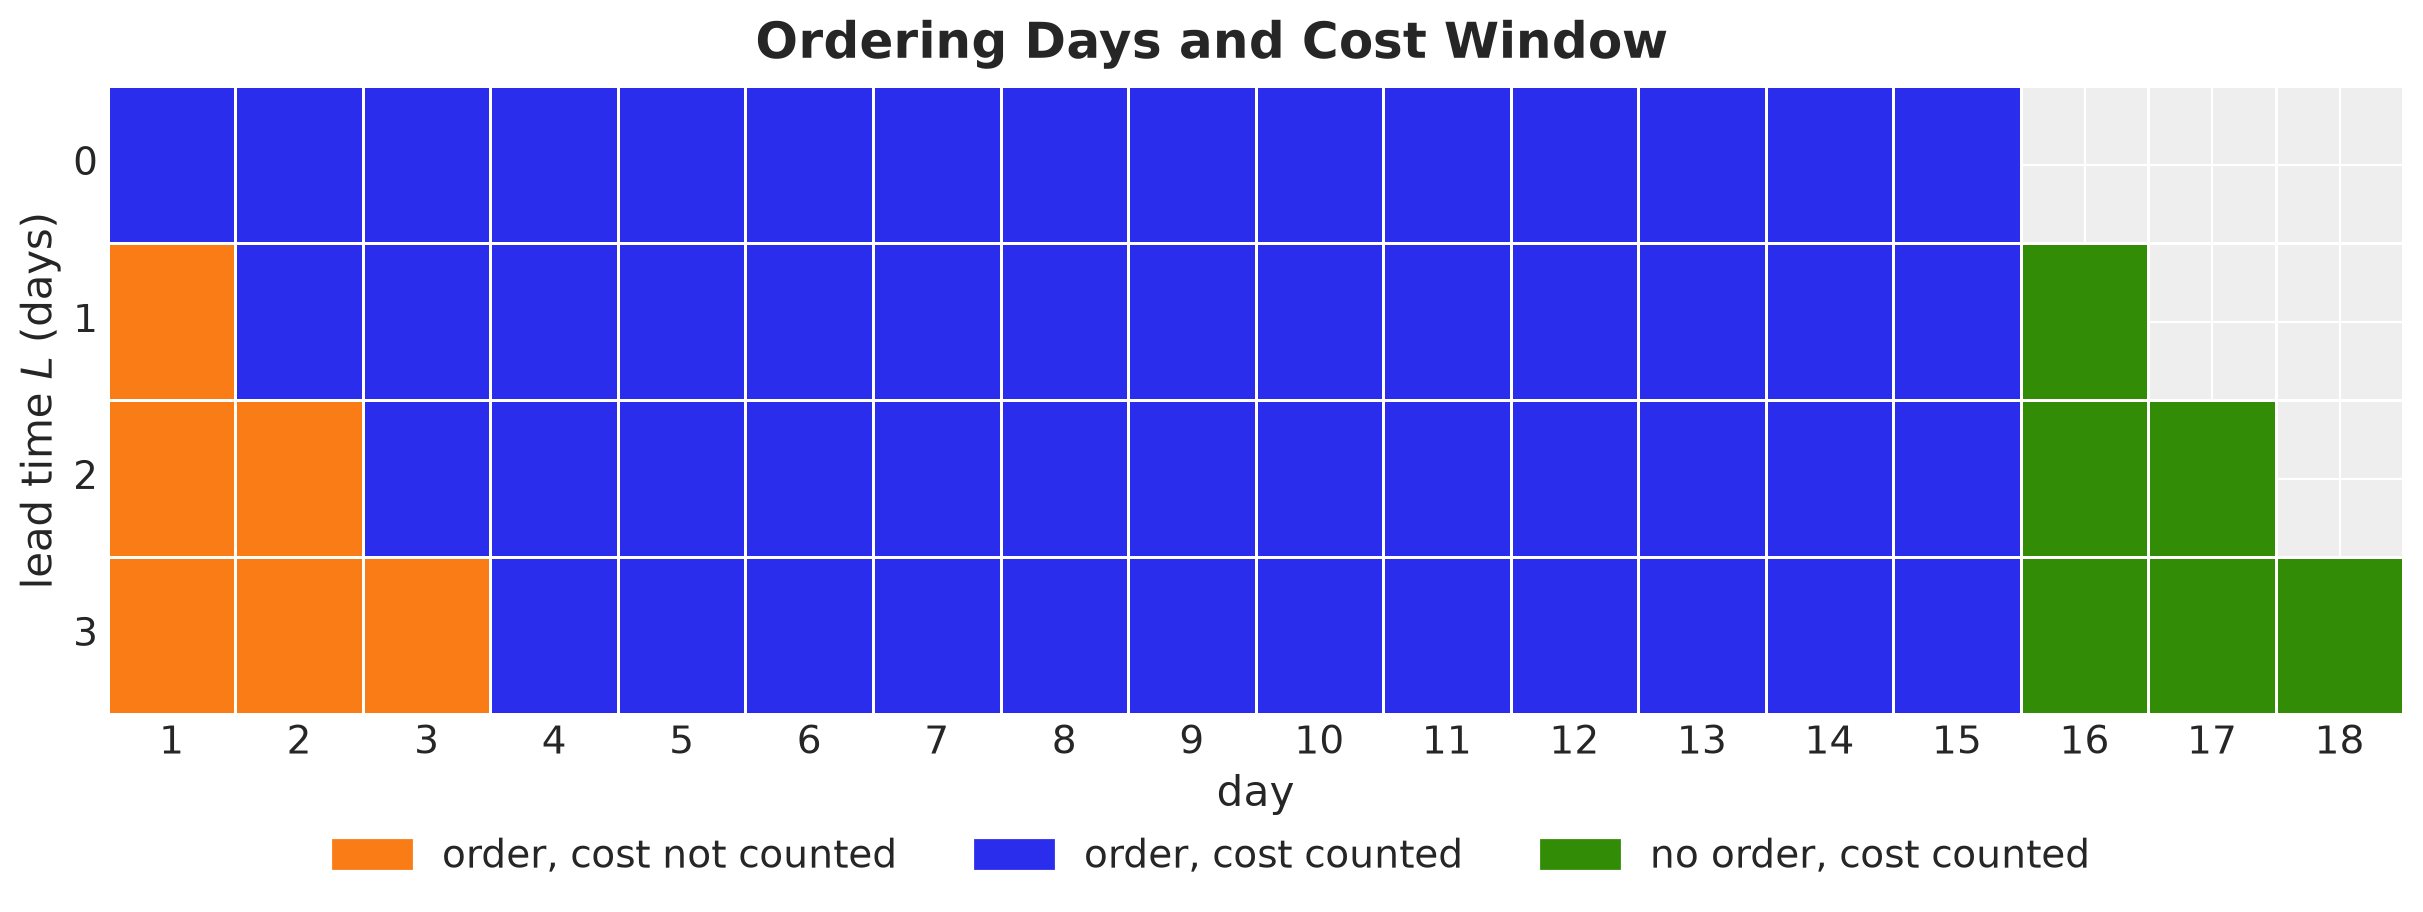

In [3]:
horizon_days = np.arange(1, setup.max_days + 1)
lead_times = np.asarray(setup.lead_times)[:, None]
is_ordering_day = np.broadcast_to(
    horizon_days <= setup.horizon, (len(lead_times), setup.max_days)
)
is_cost_day = (horizon_days > lead_times) & (horizon_days <= setup.horizon + lead_times)
DAY_KINDS = {
    "order, cost not counted": is_ordering_day & ~is_cost_day,
    "order, cost counted": is_ordering_day & is_cost_day,
    "no order, cost counted": ~is_ordering_day & is_cost_day,
}
# the days that we do not simulate for a lead time stay empty
day_kind = np.full(is_cost_day.shape, np.nan)

for code, mask in enumerate(DAY_KINDS.values()):
    day_kind[mask] = code

kind_colors = ["C1", "C0", "C2"]

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(
    day_kind,
    cmap=kind_colors,
    cbar=False,
    linewidths=1,
    linecolor="white",
    xticklabels=horizon_days,
    yticklabels=setup.lead_times,
    ax=ax,
)
ax.tick_params(axis="y", rotation=0)
ax.set(xlabel="day", ylabel="lead time $L$ (days)")
fig.legend(
    handles=[
        Patch(color=color, label=label)
        for color, label in zip(kind_colors, DAY_KINDS, strict=True)
    ],
    loc="outside lower center",
    ncol=3,
)
fig.suptitle("Ordering Days and Cost Window", fontsize=18, fontweight="bold");

Every row has $15$ ordering days and $15$ days in the cost window, and the cost window starts $L$ days after the first order. The empty cells are days that we do not simulate.

The cost window moves with the lead time, so it covers different days for different lead times. For this reason we compare the policies within a lead time, and we do not compare the loss of one policy across lead times.

### Policies

On day $t$ a policy sees the **observation** $o_t$: the day $t$, the stock on hand after the arrival of step $1$, each order in the pipeline, and the demand of the last $K = 7$ days. A **policy** is a function $\pi_\theta$ that maps the observation to the order of the day,

$$
a_t = \pi_\theta(o_t),
$$

where $\theta$ collects the parameters of the policy (not of the demand model). The observation contains only what we know when we order. In particular it does not contain the demand $D_t$ of the day or of any later day.

The loss now depends on the policy and on the demand path $D = (D_1, \dots, D_{H+L})$, so we write it as $C(\theta, D)$. As in the first post, we estimate its expected value with scenarios. Let $D^{(1)}, \dots, D^{(N)}$ be $N$ **scenarios**, joint draws of the demand path from the forecast. The **expected loss** of a policy is

$$
J(\theta) = \text{E}[C(\theta, D)] \approx \frac{1}{N} \sum_{n=1}^{N} C(\theta, D^{(n)}),
$$

and we look for the parameters $\theta$ that minimize it.

A fixed plan is a policy that ignores the observation. So from here on we call all four ways of placing the orders policies:

- **Fixed plan.** The order of day $t$ is one number, $\pi_\theta(o_t) = \theta_t$ with $\theta_t \geq 0$. For $L = 0$ this is the expected cost plan of the first post.
- **Base-stock policy.** We choose a **base-stock level** $q_t$ for every ordering day and order up to it from the inventory position, $\pi_\theta(o_t) = (q_t - \text{IP}_t)^{+}$. The parameters are the $H$ levels.
- **Neural policy.** A neural network $g_\theta$ adds a correction to the base-stock level, $\pi_\theta(o_t) = (q_t + \bar{d} \, g_\theta(o_t) - \text{IP}_t)^{+}$, where $\bar{d}$ is the mean daily demand of the history.
- **Rolling horizon.** It has no parameters to train. We describe it in the *Rolling Horizon* section.

The base-stock policy is the standard rule of inventory theory. With lost sales and a positive lead time it is not optimal in general. [Zipkin (2008)](https://doi.org/10.1287/opre.1070.0471) tests several rules on this problem and reports:

> We find that several perform reasonably well, although none is perfect. However, the standard base-stock policy (a direct analogue of the optimal policy for a backlog system) performs badly.

See also the review of [Bijvank and Vis (2011)](https://doi.org/10.1016/j.ejor.2011.02.004). On the other hand, [Huh et al. (2009)](https://doi.org/10.1287/mnsc.1080.0945) show that the best base-stock policy is close to optimal when the lost margin is large compared with the holding cost. Our ratio is $p / h = 20$.

The neural policy tells us how much a more flexible rule gains over the base-stock policy in our problem. From $L = 2$ on, one or more orders are still in the pipeline when we decide. The inventory position adds them to the stock on hand, while the neural policy sees each of them.

[Gijsbrechts et al. (2022)](https://doi.org/10.1287/msom.2021.1064) train neural policies for this lost-sales problem with deep reinforcement learning. We train ours through the simulator, which is possible because we know the inventory dynamics and we have the scenarios.

Now that we have the four policies, let's build the demand scenarios that all of them use.

## Demand Scenarios

### Forecasting Model

We generate the same data and fit the same forecasting model as in the first post, with the same random keys, so the posterior is the same. The demand has a level that drifts as a random walk on the log scale, a weekly pattern, a price promotion with an elasticity, and negative binomial noise. A promotion cuts the price by $30\%$ for a week, and the second week of the horizon, days $8$ to $14$, is a promotion week. The first post explains the generator, the prior elicitation with PreliZ and the diagnostics in its sections *Generate Data* to *Model Fitting*.

First, we simulate the history from the generator with the true parameters fixed by the `do` handler.

In [4]:
# Fourier features to generate weekly seasonality
fourier = fourier_features(setup.duration, period=7.0, num_terms=3)
# the retailer's plan for the horizon: a promotion in its second week
promo_future = jnp.zeros(setup.horizon).at[7:14].set(1.0)


def demand_generator(
    fourier: Float[Array, "duration features"],
    promo_future: Float[Array, " horizon"],
    setup: Setup,
) -> None:
    """Daily demand with a drifting level, a weekly pattern and price promotions."""
    duration, num_features = fourier.shape
    intercept = numpyro.sample("intercept", dist.Normal(4.0, 1.0))
    beta = numpyro.sample(
        "beta", dist.Normal(0.0, 0.3).expand([num_features]).to_event(1)
    )
    elasticity = numpyro.sample("elasticity", dist.Normal(0.0, 1.0))
    drift_scale = numpyro.sample("drift_scale", dist.HalfNormal(0.05))
    concentration = numpyro.sample("concentration", dist.Gamma(20.0, 1.0))

    # one Bernoulli per week of history, repeated over its seven days
    with numpyro.plate("week", setup.t_obs // 7):
        promo_week = numpyro.sample("promo_week", dist.Bernoulli(setup.promo_prob))

    promo = jnp.concatenate([jnp.repeat(promo_week, 7), promo_future])
    log_price = numpyro.deterministic(
        "log_price", promo * jnp.log(1.0 - setup.discount)
    )

    with numpyro.plate("time", duration):
        drift = numpyro.sample("drift", dist.Normal(0.0, drift_scale))
        level = jnp.cumsum(drift)
        log_rate = intercept + level + fourier @ beta + elasticity * log_price
        numpyro.sample("y", dist.NegativeBinomial2(jnp.exp(log_rate), concentration))


true_params: dict[str, Array] = {
    "intercept": jnp.log(60.0),
    "beta": jnp.array([0.15, 0.05, -0.08, 0.10, 0.03, -0.02]),
    "elasticity": jnp.array(-1.5),
    "drift_scale": jnp.array(0.01),
    "concentration": jnp.array(30.0),
}

rng_key, key_data = random.split(rng_key)
generator = Predictive(do(demand_generator, data=true_params), num_samples=1)
draw = generator(key_data, fourier, promo_future, setup)

log_price = draw["log_price"][0]
covariates = jnp.concatenate([fourier, log_price[:, None]], axis=1)
# time at axis -2, one observation dim at -1
data = draw["y"][0, : setup.t_obs, None]

Next, we define the priors and the forecasting model. The model has the structure of the generator: the `intercept`, the Fourier coefficients `beta`, the price `elasticity`, the `drift_scale` of the level and the `concentration` of the negative binomial.

In [5]:
ELICITATION_MASS = 0.94

intercept_prior = pz.maxent(
    pz.Normal(),
    float(np.log(10)),
    float(np.log(300)),
    mass=ELICITATION_MASS,
    plot=False,
)
drift_prior = pz.maxent(
    pz.LogNormal(),
    float(np.log(1.04) / np.sqrt(setup.t_obs)),
    float(np.log(2) / np.sqrt(setup.t_obs)),
    mass=ELICITATION_MASS,
    plot=False,
)
concentration_prior = pz.maxent(
    pz.Gamma(), 4.0, 100.0, mass=ELICITATION_MASS, plot=False
)


def demand_model(
    covariates: Float[Array, "duration features"],
    data: Int[Array, "t_obs 1"] | None = None,
) -> None:
    """Local level plus weekly seasonality plus price, negative binomial likelihood."""
    horizon = Horizon.from_data(covariates, data)
    fourier, log_price = covariates[..., :-1], covariates[..., -1]
    num_features = fourier.shape[-1]
    intercept = numpyro.sample(
        "intercept", dist.Normal(intercept_prior.mu, intercept_prior.sigma)
    )
    beta = numpyro.sample(
        "beta", dist.Normal(0.0, 0.3).expand([num_features]).to_event(1)
    )
    elasticity = numpyro.sample("elasticity", dist.Normal(-1.0, 1.0))
    drift_scale = numpyro.sample(
        "drift_scale", dist.LogNormal(drift_prior.mu, drift_prior.sigma)
    )
    concentration = numpyro.sample(
        "concentration",
        dist.Gamma(concentration_prior.alpha, concentration_prior.beta),
    )
    # non-centered increments: the sampler sees standardized drifts
    drift = innovations(
        horizon, "drift", dist.Normal(0.0, drift_scale), reparam=LocScaleReparam(0)
    )
    level = jnp.cumsum(drift, axis=-2)
    regression = (fourier @ beta + elasticity * log_price)[..., None]
    log_rate = intercept + level + regression

    def likelihood(eta: Float[Array, "..."]) -> Distribution:
        return dist.NegativeBinomial2(jnp.exp(eta), concentration)

    predict(horizon, likelihood, log_rate)

Now we fit the model with NUTS. We check the two diagnostics of the first post with assertions: no divergent transitions and $\hat{R}$ values of at most $1.01$.

In [6]:
%%time

# the first post draws its prior predictive check from this key
rng_key, _ = random.split(rng_key)
rng_key, key_fit = random.split(rng_key)
mcmc = MCMC(
    NUTS(demand_model, target_accept_prob=0.9),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
)
mcmc.run(key_fit, covariates[: setup.t_obs], data)

posterior = mcmc.get_samples()
rng_key, key_tree = random.split(rng_key)
idata = to_datatree(key_tree, demand_model, posterior, data, covariates, num_chains=4)

global_params = ["intercept", "beta", "elasticity", "drift_scale", "concentration"]
assert int(mcmc.get_extra_fields()["diverging"].sum()) == 0
assert float(az.summary(idata, var_names=global_params)["r_hat"].max()) <= 1.01

CPU times: user 1min 8s, sys: 1min 22s, total: 2min 31s
Wall time: 19 s


Both checks pass, which is good! Let's move to the scenarios.

### Scenario Sets

In the first post a scenario was a posterior predictive draw of the $15$ days. We shuffled the $4{,}000$ draws and used $1{,}000$ of them to build the plans, the **optimization set**, and the other $3{,}000$ to score them, the **evaluation set**. Here we need three changes.

- **Longer paths.** The longest lead time needs $15 + 3 = 18$ days of demand. The three extra days have no promotion.
- **A validation set.** The neural policy has many parameters, so we choose its parameters on scenarios that it does not train on.
- **A split by posterior draw.** Every scenario comes from one posterior draw of the parameters and the level. We keep the split of the first post at the level of the draws: the training set, the validation set and the rolling horizon use the $1{,}000$ draws of the optimization set, and the test scenarios come from the other $3{,}000$ draws. So no policy sees the parameters behind a test scenario.

To simulate demand paths from a posterior draw we need its parameters and the level of the demand on the last day of the history. We call such a pair a **particle**. The name comes from the particle filter of the *Rolling Horizon* section, which updates these pairs with the demand that we observe.

The function `simulate_demand` continues the random walk of the level from a particle and draws the demand, with the same formulas as `demand_model`. We write it by hand because the rolling horizon calls it on every ordering day, from a level that is not the one at the end of the history. At the end of the cell we check it against the forecast of [`numpyro_forecast`](https://juanitorduz.github.io/numpyro_forecast/).

In [7]:
# the scenario matrix of the first post and the permutation that splits its rows
scenarios_first_post = jnp.asarray(
    idata["predictions"]["obs"].values.reshape(-1, setup.horizon), dtype=jnp.float32
)
rng_key, key_split = random.split(rng_key)
draw_order = random.permutation(key_split, scenarios_first_post.shape[0])
NUM_DRAWS_OPT = 1_000
draws_opt, draws_test = draw_order[:NUM_DRAWS_OPT], draw_order[NUM_DRAWS_OPT:]

# covariates of the days after the history. The rolling horizon simulates
# `horizon + lead_time` days from every ordering day, so it reads up to `2 * max_days`
num_future = 2 * setup.max_days
fourier_future = fourier_features(setup.t_obs + num_future, period=7.0, num_terms=3)[
    setup.t_obs :
]
promo_days = jnp.zeros(num_future).at[: setup.horizon].set(promo_future)
covariates_future = jnp.concatenate(
    [fourier_future, (promo_days * jnp.log(1.0 - setup.discount))[:, None]], axis=1
)


class Particles(NamedTuple):
    """Parameter draws with the level of the demand on the last observed day."""

    draw: Int[Array, " particles"]  # index of the posterior draw
    intercept: Float[Array, " particles"]
    beta: Float[Array, "particles features"]
    elasticity: Float[Array, " particles"]
    drift_scale: Float[Array, " particles"]
    concentration: Float[Array, " particles"]
    level: Float[Array, " particles"]


def take(particles: Particles, index: Int[Array, " num"]) -> Particles:
    """Select particles by position."""
    return jax.tree.map(lambda leaf: leaf[index], particles)


def simulate_demand(
    key: PRNGKeyArray,
    particles: Particles,
    first_day: Int[Array, ""] | int,
    num_days: int,
) -> Float[Array, "particles num_days"]:
    """One demand path per particle for `num_days` days from `first_day` on."""
    key_level, key_demand = random.split(key)
    num_particles = particles.level.shape[0]
    increments = random.normal(key_level, (num_particles, num_days))
    levels = particles.level[:, None] + particles.drift_scale[:, None] * jnp.cumsum(
        increments, axis=1
    )
    x = jax.lax.dynamic_slice(
        covariates_future, (first_day, 0), (num_days, covariates_future.shape[1])
    )
    log_rate = (
        particles.intercept[:, None]
        + levels
        + particles.beta @ x[:, :-1].T
        + particles.elasticity[:, None] * x[:, -1]
    )
    demand = dist.NegativeBinomial2(
        jnp.exp(log_rate), particles.concentration[:, None]
    ).sample(key_demand)
    return demand.astype(jnp.float32)


particles_all = Particles(
    draw=jnp.arange(posterior["intercept"].shape[0]),
    intercept=posterior["intercept"],
    beta=posterior["beta"],
    elasticity=posterior["elasticity"],
    drift_scale=posterior["drift_scale"],
    concentration=posterior["concentration"],
    # the level on the last day of the history is the sum of its increments
    level=posterior["drift"].sum(axis=(1, 2)),
)

# check against `numpyro_forecast`: the daily means and the 97% quantiles of the two
# simulators agree on the 15 days of the first post up to Monte Carlo error
rng_key, key_check = random.split(rng_key)
demand_check = simulate_demand(key_check, particles_all, 0, setup.horizon)
assert jnp.allclose(
    demand_check.mean(axis=0), scenarios_first_post.mean(axis=0), rtol=0.02
)
assert jnp.allclose(
    jnp.quantile(demand_check, 0.97, axis=0),
    jnp.quantile(scenarios_first_post, 0.97, axis=0),
    rtol=0.04,
)

The two simulators agree on the $15$ days of the first post: the daily means are within $2\%$ of each other and the daily $97\%$ quantiles within $4\%$.

Now we build the scenario sets.

- **Training set.** We take $800$ of the optimization draws and simulate $5$ paths from each, which gives $4{,}000$ scenarios.
- **Validation set.** We take the other $200$ optimization draws with $5$ paths each, which gives $1{,}000$ scenarios. The split is by draw, so the validation set also has parameter values that the training set does not have.
- **Forecast test set.** For testing we simulate one path from each of the $3{,}000$ test draws. These are the posterior draws behind the evaluation set of the first post, with new paths of $18$ days.
- **True process test set.** Because the data are synthetic we can also draw $3{,}000$ paths from the true parameters and the true level at the end of the history. These scenarios tell us how a policy that was trained on the forecast does when the demand comes from the process that generated the data.

In [8]:
class ScenarioSet(StrEnum):
    """Names of the scenario sets on which we score the policies."""

    TRAINING = "training set"
    FORECAST = "forecast test set"
    TRUE_PROCESS = "true process test set"


NUM_DRAWS_TRAIN = 800
PATHS_PER_DRAW = 5

# the particles of the optimization draws: the only ones that the training set, the
# validation set and the rolling horizon use
particles_opt = take(particles_all, draws_opt)
particles_train = take(
    particles_opt, jnp.tile(jnp.arange(NUM_DRAWS_TRAIN), PATHS_PER_DRAW)
)
particles_val = take(
    particles_opt, jnp.tile(jnp.arange(NUM_DRAWS_TRAIN, NUM_DRAWS_OPT), PATHS_PER_DRAW)
)
particles_test = take(particles_all, draws_test)
# no posterior draw behind a test scenario is used to train a policy or in the filter
assert not jnp.isin(particles_opt.draw, particles_test.draw).any()

rng_key, key_train, key_val, key_test, key_true = random.split(rng_key, 5)
demand_train = simulate_demand(key_train, particles_train, 0, setup.max_days)
demand_val = simulate_demand(key_val, particles_val, 0, setup.max_days)
# the true parameters and the true level at the end of the history, one copy per path
true_particle = Particles(
    draw=jnp.asarray(-1),
    intercept=true_params["intercept"],
    beta=true_params["beta"],
    elasticity=true_params["elasticity"],
    drift_scale=true_params["drift_scale"],
    concentration=true_params["concentration"],
    level=draw["drift"][0, : setup.t_obs].sum(),
)
particles_true = jax.tree.map(
    lambda leaf: jnp.broadcast_to(leaf, (draws_test.shape[0], *leaf.shape)),
    true_particle,
)
demand_test = {
    ScenarioSet.FORECAST: simulate_demand(key_test, particles_test, 0, setup.max_days),
    ScenarioSet.TRUE_PROCESS: simulate_demand(
        key_true, particles_true, 0, setup.max_days
    ),
}

Let's look at the forecast test set over the $18$ days, next to the last four weeks of the history. We want to see whether the three extra days look reasonable and where the true process lies inside the forecast. The bands are the $50\%$ and $94\%$ equal-tailed intervals (ETI) of the forecast test set, that is, the ranges between two percentiles.

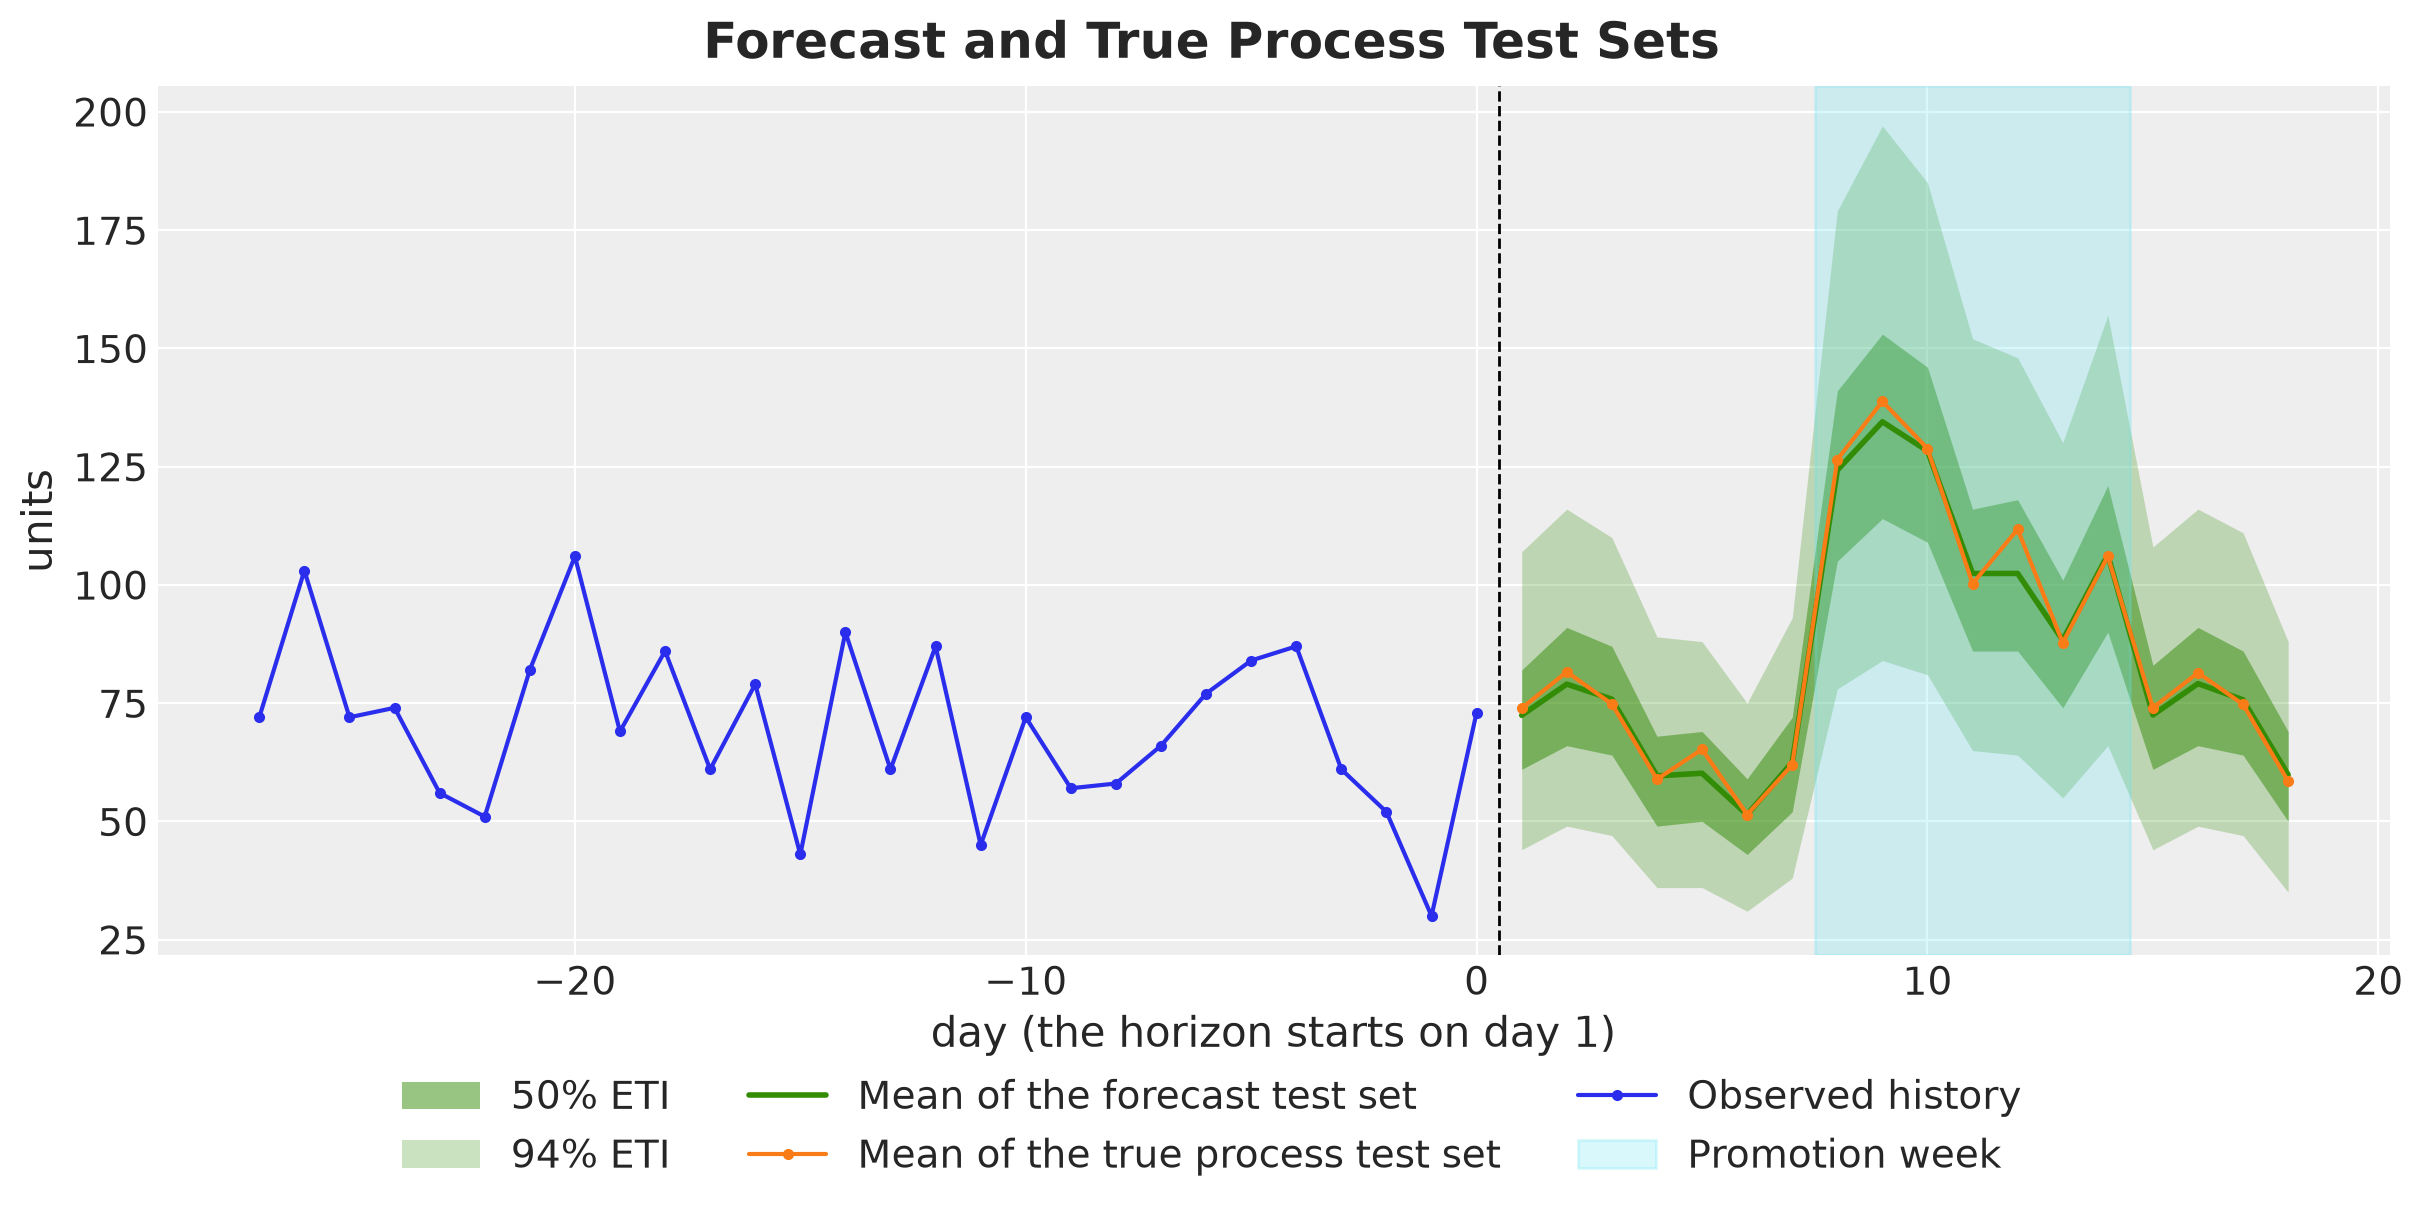

In [9]:
def lighten_bands(pc: az.PlotCollection, x: str) -> None:
    """Set the alpha of the 50% and 94% credible bands of a `plot_lm` collection."""
    bands = pc.viz["ci_band"][x]

    for prob, alpha in [(0.5, 0.5), (CI_PROB, 0.25)]:
        for band in bands.sel(prob=prob).values.flat:
            band.set_alpha(alpha)


def shade_promotion(ax: plt.Axes) -> None:
    """Shade the promotion week of the horizon."""
    promoted = np.flatnonzero(np.asarray(promo_days)) + 1
    ax.axvspan(
        promoted[0] - 0.5,
        promoted[-1] + 0.5,
        color="C5",
        alpha=0.25,
        label="Promotion week",
    )


forecast_tree = az.from_dict(
    {
        "posterior_predictive": {"demand": demand_test[ScenarioSet.FORECAST][None]},
        "observed_data": {"demand": demand_test[ScenarioSet.TRUE_PROCESS].mean(axis=0)},
        "constant_data": {"day": horizon_days},
    },
    coords={"time": horizon_days},
    dims={"demand": ["time"], "day": ["time"]},
)

pc = az.plot_lm(
    forecast_tree,
    x="day",
    y="demand",
    y_obs="demand",
    smooth=False,
    ci_prob=(0.5, CI_PROB),
    point_estimate="mean",
    visuals={
        "ci_band": {"color": "C2"},
        "pe_line": {"color": "C2", "alpha": 1.0, "linewidth": 2},
        "observed_scatter": False,
    },
    figure_kwargs={"figsize": (12, 6)},
)
lighten_bands(pc, "day")
ax = pc.viz["plot"]["day"].item()
pc.viz["ci_band"]["day"].sel(prob=CI_PROB).item().set_label(f"{CI_PROB:.0%} ETI")
pc.viz["ci_band"]["day"].sel(prob=0.5).item().set_label("50% ETI")
pc.viz["pe_line"]["day"].item().set_label(f"Mean of the {ScenarioSet.FORECAST}")
ax.plot(
    horizon_days,
    demand_test[ScenarioSet.TRUE_PROCESS].mean(axis=0),
    "o-",
    markersize=3,
    color="C1",
    label=f"Mean of the {ScenarioSet.TRUE_PROCESS}",
)
# the two means are within 10% of each other on every day
assert jnp.allclose(
    demand_test[ScenarioSet.TRUE_PROCESS].mean(axis=0),
    demand_test[ScenarioSet.FORECAST].mean(axis=0),
    rtol=0.1,
)
history_days = np.arange(-27, 1)
ax.plot(
    history_days,
    data[-len(history_days) :, 0],
    "o-",
    markersize=3,
    color="C0",
    label="Observed history",
)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
shade_promotion(ax)
ax.set(xlabel="day (the horizon starts on day $1$)", ylabel="units", title="")
fig = pc.viz["figure"].item()
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Forecast and True Process Test Sets", fontsize=18, fontweight="bold");

The forecast follows the weekly pattern and rises in the promotion week (the shaded days), as in the first post, and the three extra days look like the first days of the horizon. The mean of the true process test set is within $10\%$ of the mean of the forecast test set on every day, so the forecast is centered near the truth. Keep this in mind for the evaluation.

## Inventory Simulator

The simulator of the first post took a vector of orders and a demand path and returned the loss. The new simulator takes a policy and its parameters in place of the orders. It is again a `jax.lax.scan` over the days, and every iteration runs the five steps of a day from the *Lead Time* section. We start with one day.

- **State.** The scan carries the `InventoryState` from one day to the next: the stock on hand, the pipeline as a vector of length $L$, and the last $K$ demands.
- **Observation.** The function `observe` receives the order that arrives and builds the `Observation` from the state and the day. It does not take the demand as an argument, so no policy can see the demand of the day on which it orders.
- **Step.** The function `inventory_step` asks the policy for the order, appends it to the pipeline, sells, and charges the cost if the day is in the cost window.

In [10]:
class InventoryState(NamedTuple):
    """What the simulator carries from one day to the next."""

    inventory: Float[Array, ""]  # stock on hand at the end of the day
    pipeline: Float[Array, " lead_time"]  # orders on their way, the first arrives next
    demand_history: Float[Array, " window"]  # the last demands, most recent last


class Observation(NamedTuple):
    """What a policy sees on a day, before the demand of that day."""

    day: Int[Array, ""]
    inventory: Float[Array, ""]  # stock on hand after the arrival of the day
    pipeline: Float[Array, " in_transit"]  # orders that arrive on later days
    position: Float[Array, ""]  # stock on hand plus pipeline
    demand_history: Float[Array, " window"]


class Simulation(NamedTuple):
    """Daily cost, orders, stock and lost sales of a policy on demand paths."""

    daily_cost: Float[Array, "*scenarios days"]
    orders: Float[Array, "*scenarios days"]
    inventory: Float[Array, "*scenarios days"]
    lost_sales: Float[Array, "*scenarios days"]

    @property
    def loss(self) -> Float[Array, "*scenarios"]:
        """Sum of the daily costs, which are zero outside the cost window."""
        return self.daily_cost.sum(axis=-1)


type Policy = Callable[[PyTree, Observation], Float[Array, ""]]


def observe(state: InventoryState, day: Int[Array, ""], lead_time: int) -> Observation:
    """Receive the order that arrives today and collect what a policy may see."""
    if lead_time > 0:
        inventory = state.inventory + state.pipeline[0]
        in_transit = state.pipeline[1:]
    else:
        inventory, in_transit = state.inventory, state.pipeline

    return Observation(
        day=day,
        inventory=inventory,
        pipeline=in_transit,
        position=inventory + in_transit.sum(),
        demand_history=state.demand_history,
    )


def inventory_step(
    policy: Policy,
    params: PyTree,
    state: InventoryState,
    demand_t: Float[Array, ""],
    day: Int[Array, ""],
    config: InventoryConfig,
    lead_time: int,
) -> tuple[InventoryState, Simulation]:
    """One day of the inventory dynamics: receive, observe, order, sell, pay."""
    observation = observe(state, day, lead_time)
    # no orders after day H
    order = jnp.where(day < setup.horizon, policy(params, observation), 0.0)

    if lead_time > 0:
        inventory = observation.inventory
        pipeline = jnp.concatenate([observation.pipeline, order[None]])
    else:
        # without a lead time the order is on the shelf before the demand
        inventory = observation.inventory + order
        pipeline = observation.pipeline

    sales = jnp.minimum(inventory, demand_t)
    lost_sales = demand_t - sales
    inventory = inventory - sales
    in_cost_window = (day >= lead_time) & (day < setup.horizon + lead_time)
    daily_cost = jnp.where(
        in_cost_window,
        config.holding_cost * inventory + config.lost_sales_cost * lost_sales,
        0.0,
    )
    demand_history = jnp.concatenate([state.demand_history[1:], demand_t[None]])
    return (
        InventoryState(inventory, pipeline, demand_history),
        Simulation(daily_cost, order, inventory, lost_sales),
    )

Next, the function `simulate` scans `inventory_step` over a demand path, and `simulate_scenarios` vectorizes it over the scenarios with `jax.vmap`. The function `initial_state` returns the state before day one, and `trim_demand` keeps the days that we simulate for a lead time.

The lead time changes the shape of the pipeline, so it is a static argument and JAX compiles the simulator once per lead time. The costs are ordinary arguments, so we can change them later without a new compilation.

In [11]:
def simulate(
    policy: Policy,
    params: PyTree,
    demand: Float[Array, " days"],
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
    first_day: Int[Array, ""] | int = 0,
) -> Simulation:
    """Run a policy against one demand path that starts on `first_day`."""

    def step(
        state: InventoryState, inputs: tuple[Float[Array, ""], Int[Array, ""]]
    ) -> tuple[InventoryState, Simulation]:
        demand_t, day = inputs
        return inventory_step(policy, params, state, demand_t, day, config, lead_time)

    days = first_day + jnp.arange(demand.shape[0])
    _, simulation = jax.lax.scan(step, state, (demand, days))
    return simulation


def simulate_scenarios(
    policy: Policy,
    params: PyTree,
    demand: Float[Array, "scenarios days"],
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
    first_day: Int[Array, ""] | int = 0,
) -> Simulation:
    """Run a policy against a batch of demand paths from the same initial state."""
    return jax.vmap(
        lambda path: simulate(policy, params, path, state, config, lead_time, first_day)
    )(demand)


simulate_scenarios_jit = jax.jit(
    simulate_scenarios, static_argnames=("policy", "lead_time")
)


def initial_state(lead_time: int) -> InventoryState:
    """The state before day one, the same for every policy."""
    return InventoryState(
        inventory=jnp.asarray(config.initial_inventory),
        # each order in the pipeline is the median demand of the day on which it arrives
        pipeline=jnp.median(demand_train[:, :lead_time], axis=0),
        demand_history=data[-setup.history_window :, 0].astype(jnp.float32),
    )


def trim_demand(
    demand: Float[Array, "scenarios days"], lead_time: int
) -> Float[Array, "scenarios simulated"]:
    """The days that we simulate for a lead time: ordering days plus lead time."""
    return demand[:, : setup.horizon + lead_time]

## Policy Training

We train the fixed plan, the base-stock policy and the neural policy with one function. First, we need its objective. As in the first post, we summarize the loss of a policy over the scenarios with two quantities:

- **Expected loss.** The mean of the loss over the scenarios, the estimate of $J(\theta)$.
- **Conditional value at risk (CVaR).** The mean of the worst $\alpha = 5\%$ of the scenario losses, the tail average. With $N$ scenarios it is the mean of the $k = \alpha N$ largest losses.

The objective is the expected loss plus a **tail weight** $\lambda \geq 0$ times the CVaR,

$$
\min_\theta \; J(\theta) + \lambda \, \text{CVaR}_\alpha(C(\theta, D)).
$$

We train with $\lambda = 0$, the expected loss, everywhere except in the *Tail Risk* section.

In [12]:
ALPHA = 0.05  # tail probability of the CVaR


def tail_size(num_scenarios: int) -> int:
    """The integer k = ALPHA * N, static because top_k needs a Python integer."""
    return max(1, round(ALPHA * num_scenarios))


def cvar(losses: Float[Array, " scenarios"]) -> Float[Array, ""]:
    """Mean of the k largest losses."""
    worst, _ = jax.lax.top_k(losses, tail_size(losses.shape[0]))
    return worst.mean()


def objective(
    losses: Float[Array, " scenarios"], tail_weight: ScalarLike
) -> Float[Array, ""]:
    """Expected loss plus the tail weight times the CVaR of the loss."""
    return losses.mean() + tail_weight * cvar(losses)

The function `train` runs Adam from [Optax](https://optax.readthedocs.io/) on the objective, and the gradient with respect to the parameters of the policy comes from `jax.grad` through the simulator. Here are four remarks about this function:

- **Batches.** The fixed plan and the base-stock policy have $15$ parameters each, and we train them on the full training set with the learning rate and the number of steps of the first post. The neural policy trains on random batches of scenarios.
- **Validation.** Every $100$ steps we evaluate the objective on a second set of scenarios, and we return the parameters with the lowest value on that set. For the neural policy this is the validation set, and for the other two we pass the training set again. The initial parameters are the first candidate, so the training cannot return a policy that is worse on that set than its starting point.
- **Gradient clipping.** We clip the norm of the gradient at $10$, a guard that the solver of the first post did not have.
- **Projection.** The orders of the fixed plan cannot be negative, so after every step we clip them at zero. The other two policies clip the order inside the policy.

The function is pure, so we can vectorize it over random keys with `jax.vmap` to train from several seeds at once.

In [13]:
class TrainConfig(NamedTuple):
    """Settings of one training run."""

    num_steps: int
    batch_size: int  # a value at or above the number of scenarios means the full batch
    learning_rate: float
    eval_every: int = 100  # steps between two evaluations on the validation set


class TrainResult(NamedTuple):
    """Best parameters on the validation set and the validation objective."""

    params: PyTree
    validation: Float[Array, "*seeds evaluations"]  # the first value is at the start


def train(
    key: PRNGKeyArray,
    policy: Policy,
    params: PyTree,
    demand_train: Float[Array, "train days"],
    demand_val: Float[Array, "val days"],
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
    tail_weight: ScalarLike,
    train_config: TrainConfig,
    project: Callable[[PyTree], PyTree] | None = None,
) -> TrainResult:
    """Adam on the objective through the simulator, best parameters on validation."""
    schedule = optax.cosine_decay_schedule(
        train_config.learning_rate, train_config.num_steps
    )
    # the clip bounds the size of a step when a batch has a large gradient
    optimizer = optax.chain(optax.clip_by_global_norm(10.0), optax.adam(schedule))
    num_train = demand_train.shape[0]

    def loss(
        params: PyTree, demand: Float[Array, "scenarios days"]
    ) -> Float[Array, ""]:
        simulation = simulate_scenarios(
            policy, params, demand, state, config, lead_time
        )
        return objective(simulation.loss, tail_weight)

    def step(
        carry: tuple[PyTree, optax.OptState], key_step: PRNGKeyArray
    ) -> tuple[tuple[PyTree, optax.OptState], None]:
        params, opt_state = carry

        if train_config.batch_size < num_train:
            index = random.choice(
                key_step, num_train, (train_config.batch_size,), replace=False
            )
            batch = demand_train[index]
        else:
            batch = demand_train

        grads = jax.grad(loss)(params, batch)
        updates, opt_state = optimizer.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)

        if project is not None:
            params = project(params)

        return (params, opt_state), None

    def train_round(
        carry: tuple[PyTree, optax.OptState, PyTree, Float[Array, ""]],
        keys: UInt32[Array, "steps 2"],
    ) -> tuple[
        tuple[PyTree, optax.OptState, PyTree, Float[Array, ""]], Float[Array, ""]
    ]:
        params, opt_state, best_params, best_value = carry
        # `eval_every` steps, then one evaluation on the validation set
        (params, opt_state), _ = jax.lax.scan(step, (params, opt_state), keys)
        value = loss(params, demand_val)
        best_params = jax.tree.map(
            lambda new, old: jnp.where(value < best_value, new, old),
            params,
            best_params,
        )
        best_value = jnp.minimum(value, best_value)
        return (params, opt_state, best_params, best_value), value

    num_evaluations = train_config.num_steps // train_config.eval_every
    keys = random.split(key, (num_evaluations, train_config.eval_every))
    value_start = loss(params, demand_val)
    carry = (params, optimizer.init(params), params, value_start)
    (_, _, best_params, _), values = jax.lax.scan(train_round, carry, keys)
    return TrainResult(best_params, jnp.concatenate([value_start[None], values]))


train_jit = jax.jit(
    train, static_argnames=("policy", "lead_time", "train_config", "project")
)

### Fixed Plan

Before we train anything new, we check the simulator and the trainer against the first post. We train the fixed plan with $L = 0$ on its optimization set and score it on its evaluation set. The first post reports four scores for its expected cost plan:

- **Expected loss.** It is $142$.
- **CVaR.** It is $370$.
- **Stockout probability per day.** The fraction of scenario and day pairs with a lost sale is $10.4\%$.
- **Probability of a stockout in the horizon.** The fraction of scenarios with at least one lost sale is $47\%$.

As there, we count a stockout only when the lost sales exceed $10^{-3}$ units, since the orders of the solver are not whole numbers.

In [14]:
def fixed_plan(params: Float[Array, " horizon"], obs: Observation) -> Float[Array, ""]:
    """The order of a day is one number per ordering day."""
    return params[obs.day]


def clip_at_zero(params: Float[Array, " horizon"]) -> Float[Array, " horizon"]:
    """Projection of a plan onto the non-negative orders."""
    return jnp.maximum(params, 0.0)


FULL_BATCH = TrainConfig(
    num_steps=1_500, batch_size=demand_train.shape[0], learning_rate=1.0
)
STOCKOUT_TOL = 1e-3  # lost sales below this are rounding noise of the solver
NO_KEY = random.PRNGKey(0)  # a full batch uses no random numbers

demand_opt_first_post = scenarios_first_post[draw_order][:NUM_DRAWS_OPT]
demand_eval_first_post = scenarios_first_post[draw_order][NUM_DRAWS_OPT:]
plan_first_post = train_jit(
    NO_KEY,
    fixed_plan,
    demand_opt_first_post.mean(axis=0),
    demand_opt_first_post,
    demand_opt_first_post,
    initial_state(0),
    config,
    lead_time=0,
    tail_weight=0.0,
    train_config=FULL_BATCH,
    project=clip_at_zero,
).params
simulation_first_post = simulate_scenarios_jit(
    fixed_plan, plan_first_post, demand_eval_first_post, initial_state(0), config, 0
)
stockout_first_post = simulation_first_post.lost_sales > STOCKOUT_TOL
assert jnp.allclose(simulation_first_post.loss.mean(), 142.0, atol=0.5)
assert jnp.allclose(cvar(simulation_first_post.loss), 370.0, atol=0.5)
assert jnp.allclose(stockout_first_post.mean(), 0.104, atol=0.002)
assert jnp.allclose(stockout_first_post.any(axis=1).mean(), 0.47, atol=0.005)

The four scores of the first post come out again within the tolerances of the assertions, which is good! 🙌 So with $L = 0$ the new simulator and the trainer reproduce the expected cost plan.

Now we train the fixed plan for every lead time on the new training set. We start from the mean demand of the days on which the orders arrive. We keep the trained policies in a dictionary indexed by the lead time and the name of the policy. The `PolicyName` enumeration lists the names that we use in the figures, including the policies of the next sections.

In [15]:
class PolicyName(StrEnum):
    """Names of the ways of placing the orders."""

    FIXED_PLAN = "Fixed plan"
    NEWSVENDOR = "Base-stock (newsvendor levels)"
    BASE_STOCK = "Base-stock (trained levels)"
    NEURAL_STOCK = "Neural (stock only)"
    NEURAL = "Neural (stock and demand)"
    ROLLING_HORIZON = "Rolling horizon"


# one color per policy in every figure that follows
POLICY_COLORS = dict(zip(PolicyName, ["C2", "C4", "C1", "C8", "C3", "C0"], strict=True))


class TrainedPolicy(NamedTuple):
    """A policy with its parameters."""

    policy: Policy
    params: PyTree


def train_fixed_plan(
    lead_time: int, config: InventoryConfig, tail_weight: float = 0.0
) -> TrainedPolicy:
    """Train the fixed plan from the mean demand of the days on which orders arrive."""
    demand = trim_demand(demand_train, lead_time)
    result = train_jit(
        NO_KEY,
        fixed_plan,
        demand[:, lead_time:].mean(axis=0),
        demand,
        demand,  # 15 parameters: we keep the best iterate on the training set
        initial_state(lead_time),
        config,
        lead_time=lead_time,
        tail_weight=tail_weight,
        train_config=FULL_BATCH,
        project=clip_at_zero,
    )
    return TrainedPolicy(fixed_plan, result.params)


policies: dict[tuple[int, PolicyName], TrainedPolicy] = {
    (lead_time, PolicyName.FIXED_PLAN): train_fixed_plan(lead_time, config)
    for lead_time in setup.lead_times
}

### Base-Stock Policy

The base-stock policy orders up to the level $q_t$ from the inventory position. We start the levels from the single-day rule of the first post. For a single day the stock that minimizes the expected cost is the $p / (p + h)$ quantile of the demand. This is the **newsvendor problem**, and the ratio $p / (p + h)$ is its **critical fractile**, which is $0.952$ for our costs.

An order of day $t$ arrives on day $t + L$, and the next order arrives one day later. So the inventory position after the order of day $t$ has to cover the demand of the days $t, \dots, t + L$. We start from the **newsvendor levels**: for every ordering day, the $p / (p + h)$ quantile of the total demand of those $L + 1$ days over the training scenarios.

The newsvendor levels need no optimizer, so we keep them as a policy of their own, `Base-stock (newsvendor levels)`, next to the levels that we train from them, `Base-stock (trained levels)`. The assertion at the end of the cell checks that at the newsvendor levels every ordering day has a positive order in more than half of the training scenarios, so every level has a gradient when the training starts.

In [16]:
def base_stock(params: Float[Array, " horizon"], obs: Observation) -> Float[Array, ""]:
    """Order up to the level of the day from the inventory position."""
    return jax.nn.relu(params[obs.day] - obs.position)


def newsvendor_levels(
    lead_time: int, config: InventoryConfig
) -> Float[Array, " horizon"]:
    """Critical fractile of the total demand of the days t, ..., t + lead_time."""
    demand = trim_demand(demand_train, lead_time)
    cumulative = jnp.cumsum(jnp.pad(demand, ((0, 0), (1, 0))), axis=1)
    covered_demand = (
        cumulative[:, lead_time + 1 : lead_time + 1 + setup.horizon]
        - cumulative[:, : setup.horizon]
    )
    critical_fractile = config.lost_sales_cost / (
        config.lost_sales_cost + config.holding_cost
    )
    return jnp.quantile(covered_demand, critical_fractile, axis=0)


def train_base_stock(
    lead_time: int, config: InventoryConfig, tail_weight: float = 0.0
) -> TrainedPolicy:
    """Train the base-stock levels from the newsvendor levels."""
    demand = trim_demand(demand_train, lead_time)
    result = train_jit(
        NO_KEY,
        base_stock,
        newsvendor_levels(lead_time, config),
        demand,
        demand,  # 15 parameters: we keep the best iterate on the training set
        initial_state(lead_time),
        config,
        lead_time=lead_time,
        tail_weight=tail_weight,
        train_config=FULL_BATCH,
    )
    return TrainedPolicy(base_stock, result.params)


for lead_time in setup.lead_times:
    policies[lead_time, PolicyName.NEWSVENDOR] = TrainedPolicy(
        base_stock, newsvendor_levels(lead_time, config)
    )
    policies[lead_time, PolicyName.BASE_STOCK] = train_base_stock(lead_time, config)
    # at the newsvendor levels every ordering day has a positive order in more than
    # half of the training scenarios, so every level has a gradient at the start
    orders_start = simulate_scenarios_jit(
        *policies[lead_time, PolicyName.NEWSVENDOR],
        trim_demand(demand_train, lead_time),
        initial_state(lead_time),
        config,
        lead_time,
    ).orders[:, : setup.horizon]
    assert float((orders_start > 0).mean(axis=0).min()) > 0.5

Next, we check whether the training moves the levels. The figure shows the trained level minus the newsvendor level for every ordering day, with one line per lead time.

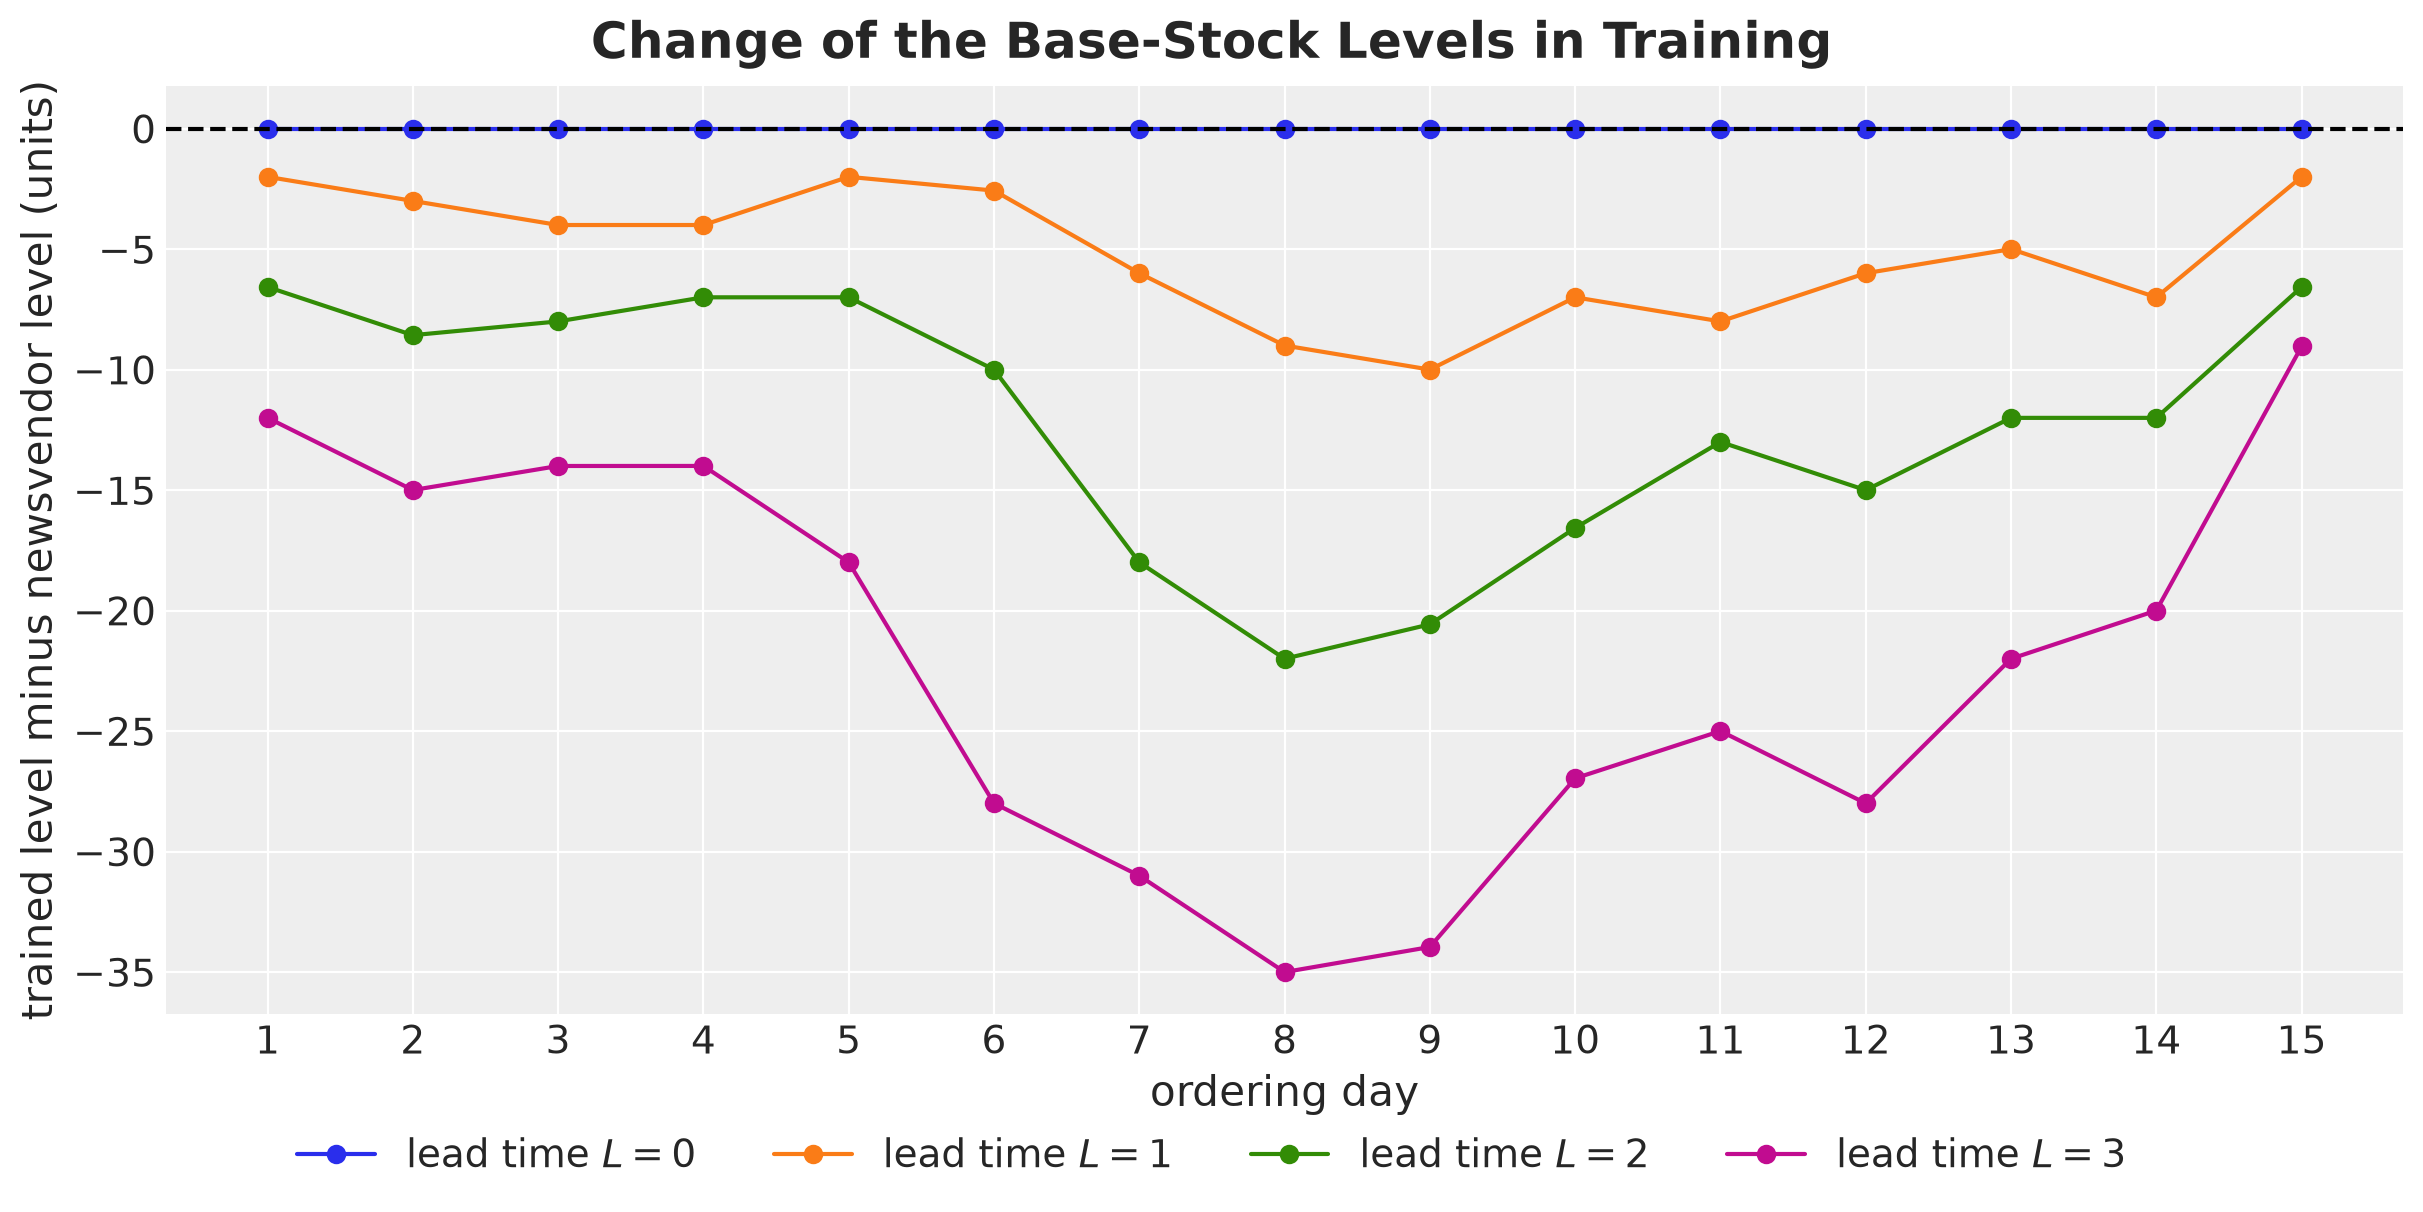

In [17]:
ordering_days = np.arange(1, setup.horizon + 1)

fig, ax = plt.subplots(figsize=(12, 6))

for lead_time in setup.lead_times:
    ax.plot(
        ordering_days,
        policies[lead_time, PolicyName.BASE_STOCK].params
        - policies[lead_time, PolicyName.NEWSVENDOR].params,
        "o-",
        color=f"C{lead_time}",
        label=f"lead time $L = {lead_time}$",
    )

ax.axhline(0.0, color="black", linestyle="--")
ax.set(
    xlabel="ordering day",
    ylabel="trained level minus newsvendor level (units)",
    xticks=ordering_days,
)
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle(
    "Change of the Base-Stock Levels in Training", fontsize=18, fontweight="bold"
);

Here is what we see.

- **No lead time.** For $L = 0$ the training does not move the levels. Without a lead time we can order up to the level of the day on every day. As long as the stock left over is below the level of the next day, the days are separate single-day problems, and the newsvendor levels already solve them.
- **Positive lead time.** For $L \geq 1$ the trained levels are below the newsvendor levels on every ordering day, and the gap grows with the lead time. The largest changes are $10$, $22$ and $35$ units for the three lead times. They occur on the ordering days $8$ and $9$, whose levels cover promotion days.

Recall that in the first post the myopic newsvendor *plan* cost $11\%$ more than the expected cost plan. A plan cannot react to the stock left over, and a policy can, which is why the same rule works here for $L = 0$.

The lower levels for $L \geq 1$ are consistent with the lost sales. The newsvendor level counts all the demand of the days $t, \dots, t + L$ against the inventory position. With lost sales the demand that we cannot serve on one of those days does not take stock away, so the level asks for more than we need.

### Neural Policy

The base-stock policy reacts to the stock, and it ignores the demand that we observe. The observed demand can help because, in the scenarios from the forecast, every path has its own parameters and its own level, and the days of a path share them. So a path that starts above the forecast mean tends to stay above it.

Let's check this on the scenarios. The next figure shows the total demand of the first week against the total demand of days $8$ to $15$, for the training set and for the true process test set.

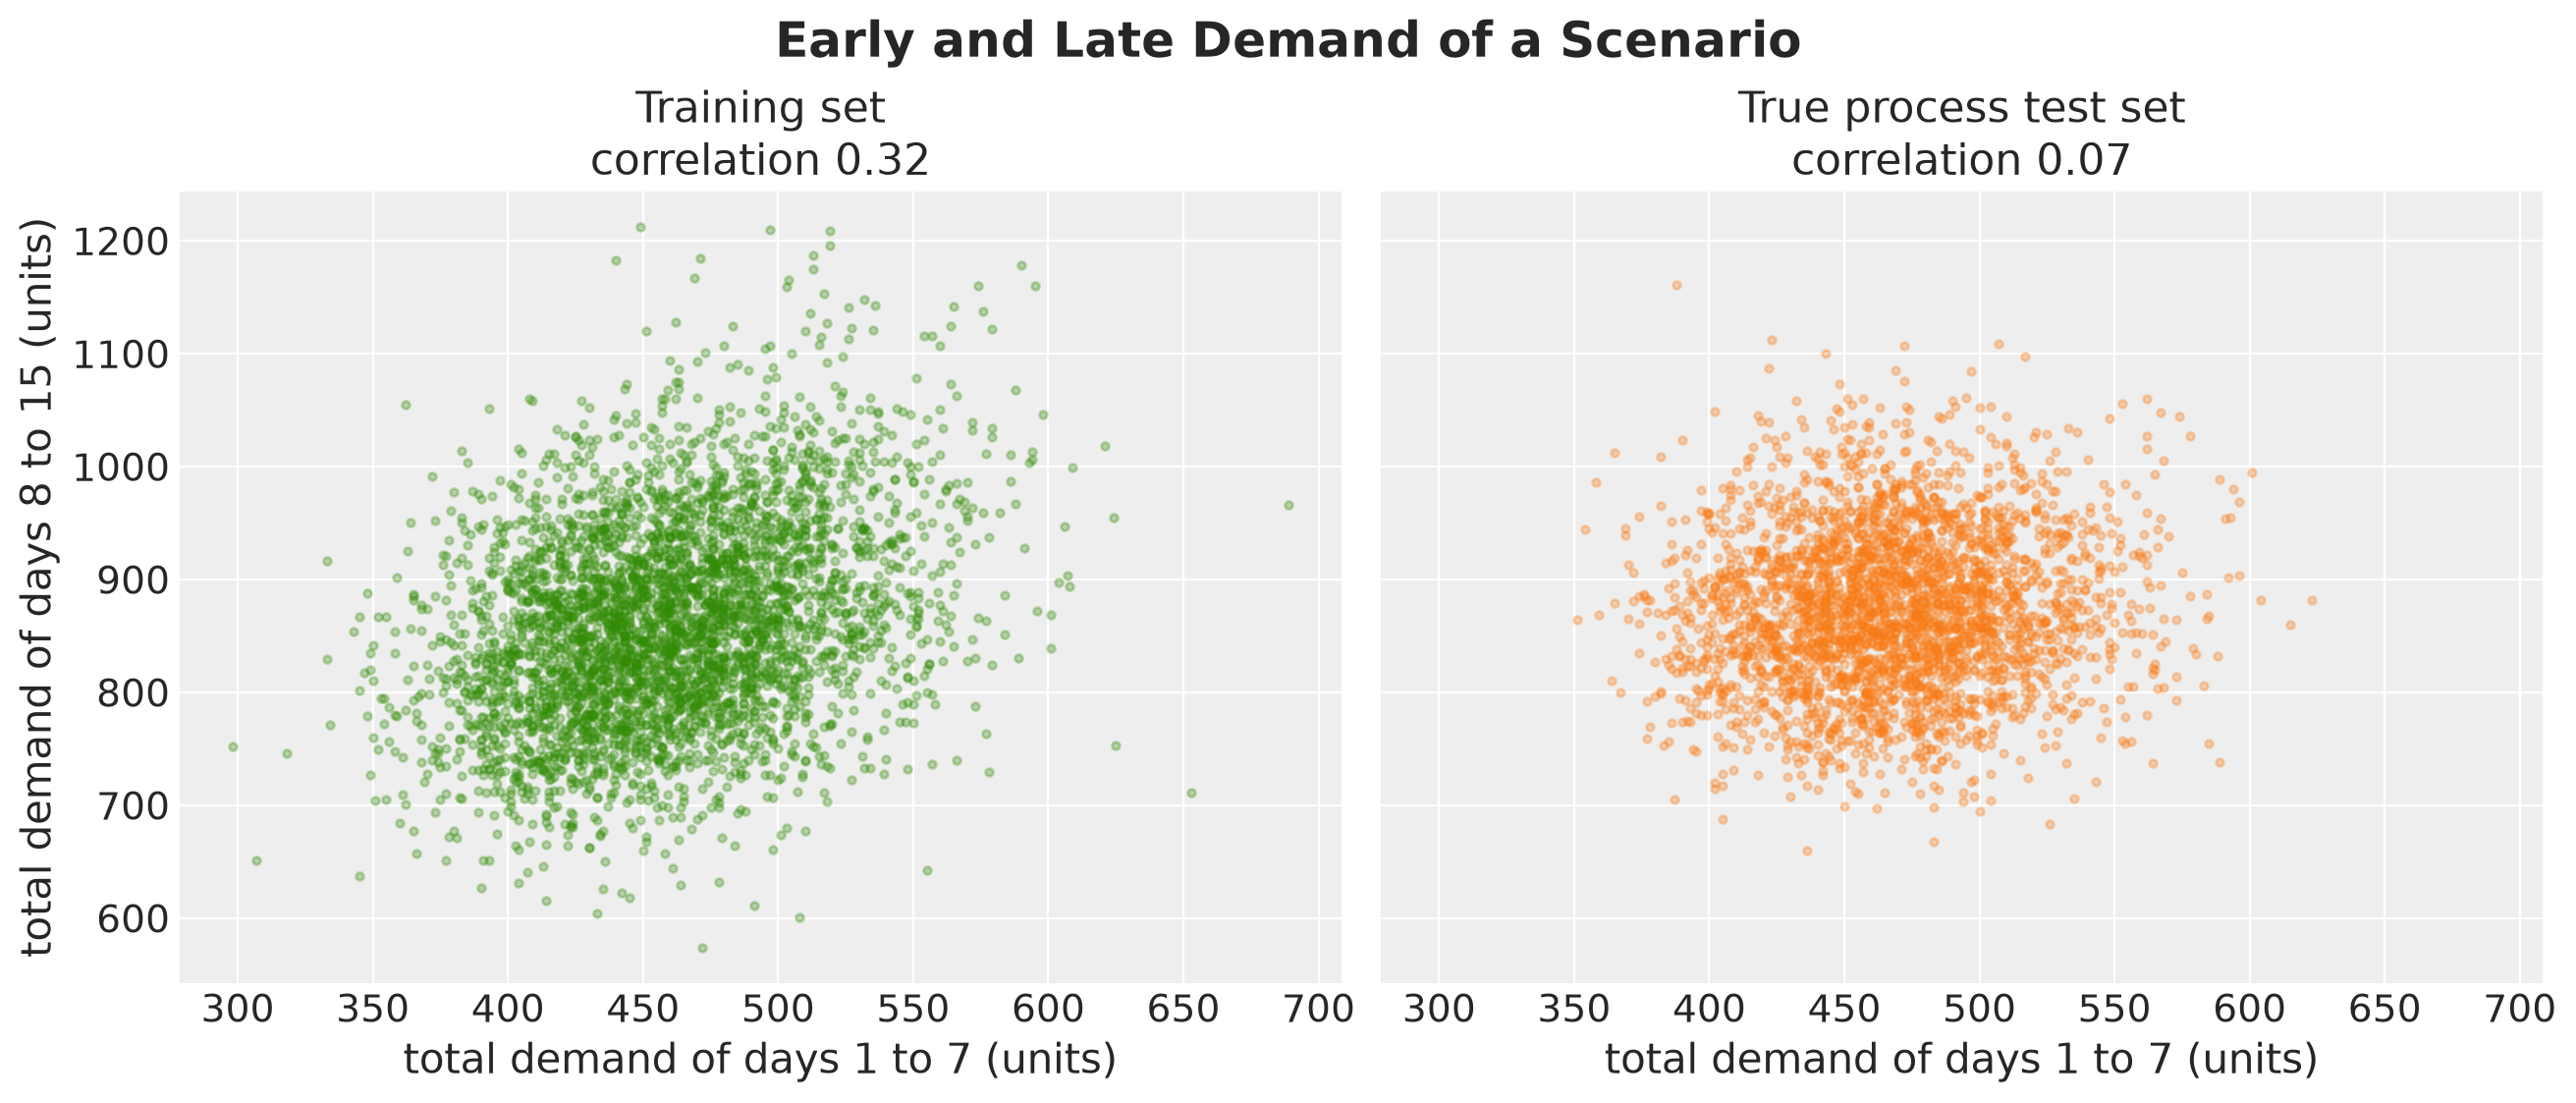

In [18]:
fig, axes = plt.subplots(
    ncols=2, figsize=(13, 5.5), sharex=True, sharey=True, layout="constrained"
)

for ax, (label, demand, color) in zip(
    axes,
    [
        (ScenarioSet.TRAINING, demand_train, "C2"),
        (ScenarioSet.TRUE_PROCESS, demand_test[ScenarioSet.TRUE_PROCESS], "C1"),
    ],
    strict=True,
):
    first_week = demand[:, :7].sum(axis=1)
    later_days = demand[:, 7 : setup.horizon].sum(axis=1)
    correlation = float(jnp.corrcoef(first_week, later_days)[0, 1])
    ax.scatter(first_week, later_days, s=8, alpha=0.3, color=color)
    ax.set(
        title=f"{label.capitalize()}\ncorrelation {correlation:.2f}",
        xlabel="total demand of days $1$ to $7$ (units)",
    )

axes[0].set(ylabel="total demand of days $8$ to $15$ (units)")
fig.suptitle("Early and Late Demand of a Scenario", fontsize=18, fontweight="bold");

In the training set the correlation is $0.32$, so a scenario with a high first week tends to have a high demand afterwards. In the true process test set it is $0.07$. All of its scenarios share the true parameters and the true level, and what is left is the small drift of the level inside the horizon.

The forecast does not know the parameters and the level exactly, and its scenarios differ in them. This is the uncertainty that the observed demand can reduce.

The neural policy adds a correction to the base-stock level. The correction is a multilayer perceptron with two hidden layers of $32$ units that reads the following features:

- **Stock.** The stock on hand and each order in the pipeline, divided by the mean daily demand $\bar{d}$ of the history.
- **Promotion.** The promotion flags of the days $t, \dots, t + L$.
- **Day.** The day $t$ divided by $H$.
- **Demand history.** The demand of the last $K = 7$ days, divided by $\bar{d}$.

We train two versions, one with all the features and one without the demand history, `Neural (stock only)`. Note that the second one is not blind to the demand. Under a base-stock rule the order of a day is the sales of the day before plus the change of the level, so the stock and the pipeline carry the demand of the last days.

The difference between the two versions is therefore a lower bound of what the observed demand gives.

The policy keeps its own copy of the base-stock levels, also in units of $\bar{d}$, and trains them together with the network. The last layer of the network starts at zero, so every training run starts at the trained base-stock policy. We check this with an assertion after the training.

In [19]:
DEMAND_SCALE = float(data.mean())  # mean daily demand of the history


def init_mlp(key: PRNGKeyArray, sizes: list[int]) -> list[dict[str, Array]]:
    """Layers of a multilayer perceptron. The last layer starts at zero."""
    keys = random.split(key, len(sizes) - 1)
    layers = []

    for i, (key_layer, num_in, num_out) in enumerate(
        zip(keys, sizes[:-1], sizes[1:], strict=True)
    ):
        is_last = i == len(sizes) - 2
        weights = (
            jnp.zeros((num_in, num_out))
            if is_last
            else random.normal(key_layer, (num_in, num_out)) * jnp.sqrt(2.0 / num_in)
        )
        layers.append({"weights": weights, "bias": jnp.zeros(num_out)})

    return layers


def mlp(
    layers: list[dict[str, Array]], x: Float[Array, " features"]
) -> Float[Array, " outputs"]:
    """Multilayer perceptron with GELU activations."""
    for layer in layers[:-1]:
        x = jax.nn.gelu(x @ layer["weights"] + layer["bias"])

    return x @ layers[-1]["weights"] + layers[-1]["bias"]


class NeuralPolicy(NamedTuple):
    """A neural base-stock policy for one lead time."""

    policy: Policy
    # what the network adds to the base-stock level of the day, in units
    correction: Callable[[PyTree, Observation], Float[Array, ""]]
    num_features: int


def make_neural_policy(lead_time: int, *, use_demand: bool = True) -> NeuralPolicy:
    """Base-stock levels plus a network that reads the observation of the day."""

    def features(obs: Observation) -> Float[Array, " features"]:
        parts = [
            obs.inventory[None] / DEMAND_SCALE,
            obs.pipeline / DEMAND_SCALE,
            # promotion flags of the days t, ..., t + lead_time
            jax.lax.dynamic_slice(promo_days, (obs.day,), (lead_time + 1,)),
            (obs.day / setup.horizon)[None],
        ]

        if use_demand:
            parts.append(obs.demand_history / DEMAND_SCALE)

        return jnp.concatenate(parts)

    def correction(params: PyTree, obs: Observation) -> Float[Array, ""]:
        return DEMAND_SCALE * mlp(params["net"], features(obs))[0]

    def policy(params: PyTree, obs: Observation) -> Float[Array, ""]:
        level = DEMAND_SCALE * params["levels"][obs.day] + correction(params, obs)
        return jax.nn.relu(level - obs.position)

    num_features = (
        1  # stock on hand
        + max(lead_time - 1, 0)  # orders in the pipeline when we decide
        + (lead_time + 1)  # promotion flags
        + 1  # day
        + (setup.history_window if use_demand else 0)
    )
    return NeuralPolicy(policy, correction, num_features)


MINIBATCH = TrainConfig(num_steps=3_000, batch_size=256, learning_rate=3e-3)
NUM_SEEDS = 3
HIDDEN_UNITS = 32


class NeuralTraining(NamedTuple):
    """The neural policy of the best seed and the validation loss of every seed."""

    trained: TrainedPolicy
    validation: Float[Array, "seeds evaluations"]


def train_neural(
    key: PRNGKeyArray,
    lead_time: int,
    config: InventoryConfig,
    levels: Float[Array, " horizon"],
    *,
    use_demand: bool = True,
) -> NeuralTraining:
    """Train the neural policy from several seeds and keep the best on validation.

    Every seed starts from the given base-stock levels and a network whose last
    layer is zero.
    """
    neural = make_neural_policy(lead_time, use_demand=use_demand)
    sizes = [neural.num_features, HIDDEN_UNITS, HIDDEN_UNITS, 1]
    demand = (
        trim_demand(demand_train, lead_time),
        trim_demand(demand_val, lead_time),
    )
    state = initial_state(lead_time)
    key_init, key_train = random.split(key)
    params = jax.vmap(
        lambda key_seed: {
            "levels": levels / DEMAND_SCALE,
            "net": init_mlp(key_seed, sizes),
        }
    )(random.split(key_init, NUM_SEEDS))
    train_seeds = jax.jit(
        jax.vmap(
            lambda key_seed, params_seed: train(
                key_seed,
                neural.policy,
                params_seed,
                *demand,
                state,
                config,
                lead_time,
                0.0,  # tail weight: we train the network for the expected loss
                MINIBATCH,
            )
        )
    )
    result = train_seeds(random.split(key_train, NUM_SEEDS), params)
    best_seed = int(result.validation.min(axis=1).argmin())
    best_params = jax.tree.map(lambda leaf: leaf[best_seed], result.params)
    return NeuralTraining(TrainedPolicy(neural.policy, best_params), result.validation)

We train both versions for every lead time from three seeds, with batches of $256$ scenarios and $3{,}000$ steps, and for each version we keep the seed with the lowest validation loss.

In [20]:
%%time

validation: dict[tuple[int, PolicyName], Float[Array, "seeds evaluations"]] = {}

for lead_time in setup.lead_times:
    levels = policies[lead_time, PolicyName.BASE_STOCK].params

    for name, use_demand in [
        (PolicyName.NEURAL_STOCK, False),
        (PolicyName.NEURAL, True),
    ]:
        rng_key, key_neural = random.split(rng_key)
        policies[lead_time, name], validation[lead_time, name] = train_neural(
            key_neural, lead_time, config, levels, use_demand=use_demand
        )

    # before the first step both neural policies are the trained base-stock policy
    loss_base_stock = simulate_scenarios_jit(
        *policies[lead_time, PolicyName.BASE_STOCK],
        trim_demand(demand_val, lead_time),
        initial_state(lead_time),
        config,
        lead_time,
    ).loss.mean()
    assert jnp.allclose(
        validation[lead_time, PolicyName.NEURAL][:, 0], loss_base_stock, atol=0.01
    )
    assert jnp.allclose(
        validation[lead_time, PolicyName.NEURAL_STOCK][:, 0], loss_base_stock, atol=0.01
    )

CPU times: user 11min 19s, sys: 5min 5s, total: 16min 24s
Wall time: 2min 25s


Let's look at the expected loss on the validation set during the training. Every line is one seed, and the dashed line is the validation loss of the trained base-stock policy, where every seed starts.

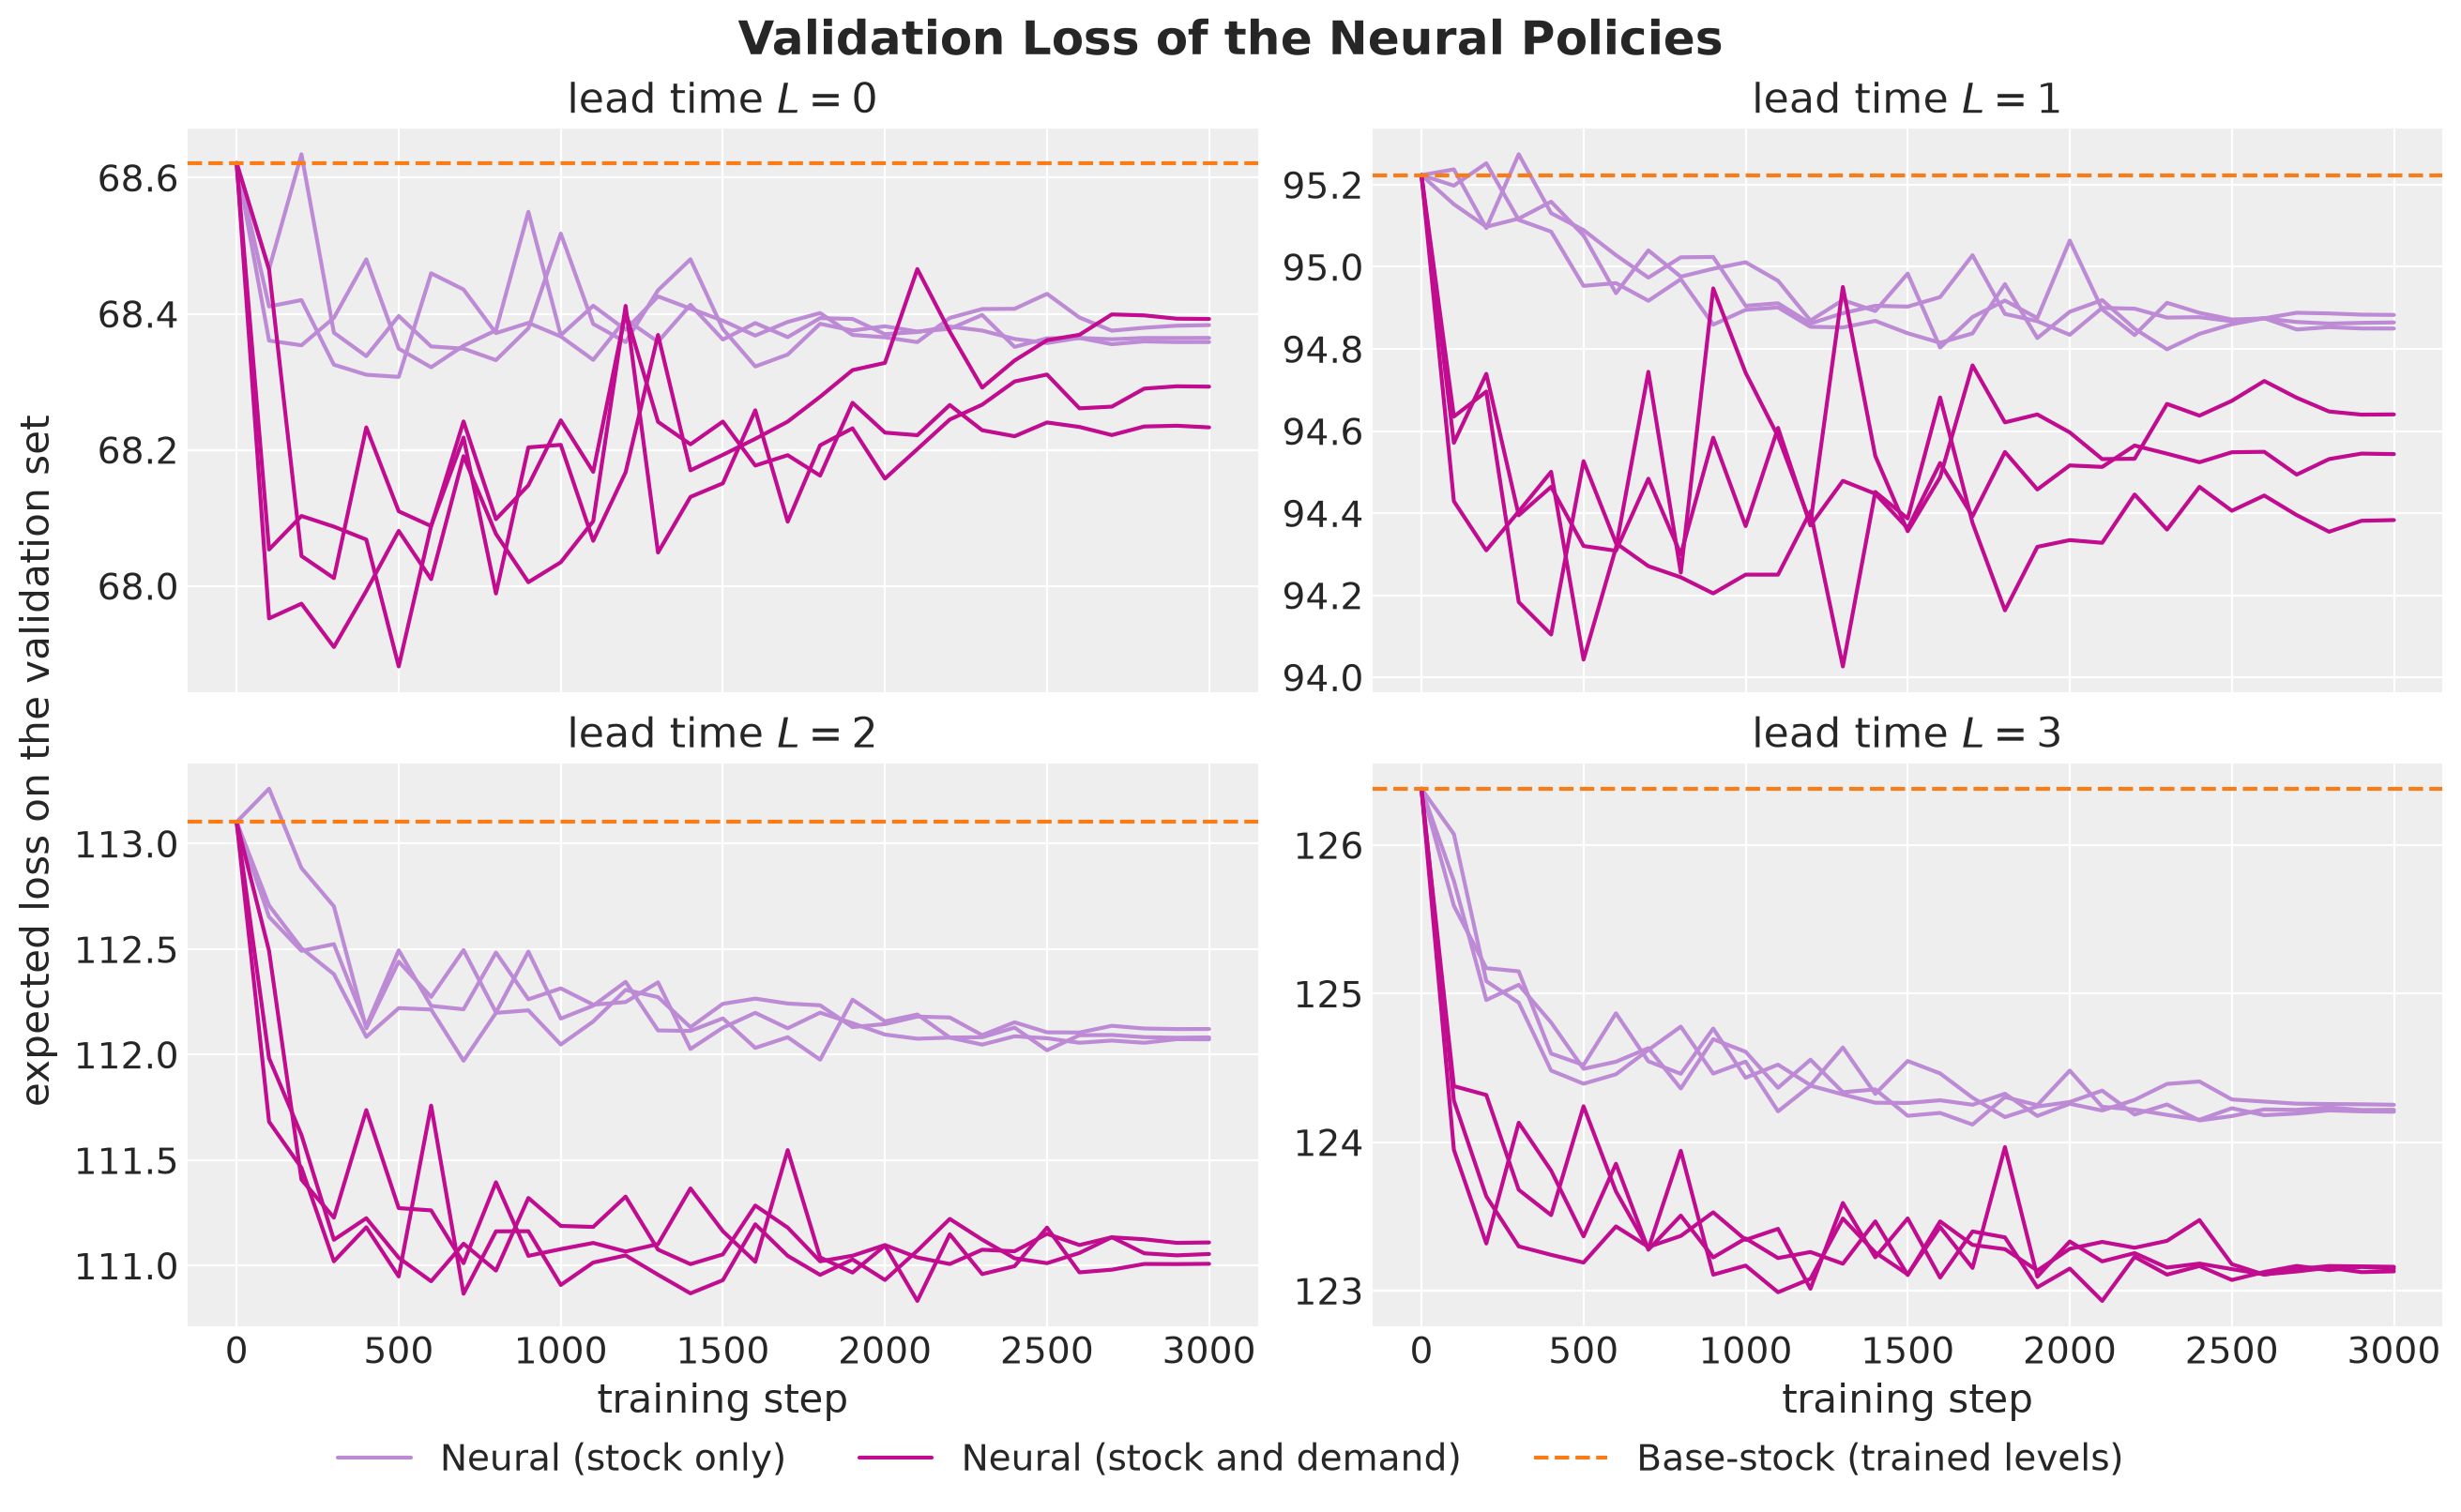

In [21]:
evaluation_steps = MINIBATCH.eval_every * np.arange(
    MINIBATCH.num_steps // MINIBATCH.eval_every + 1
)

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(13, 8), sharex=True, layout="constrained"
)

for ax, lead_time in zip(axes.flat, setup.lead_times, strict=True):
    for name in [PolicyName.NEURAL_STOCK, PolicyName.NEURAL]:
        lines = ax.plot(
            evaluation_steps, validation[lead_time, name].T, color=POLICY_COLORS[name]
        )
        lines[0].set_label(name)

    ax.axhline(
        float(validation[lead_time, PolicyName.NEURAL][0, 0]),
        color=POLICY_COLORS[PolicyName.BASE_STOCK],
        linestyle="--",
        label=PolicyName.BASE_STOCK,
    )
    ax.set(title=f"lead time $L = {lead_time}$")

for ax in axes[-1]:
    ax.set(xlabel="training step")

fig.supylabel(
    "expected loss on the validation set", fontsize=plt.rcParams["axes.labelsize"]
)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle("Validation Loss of the Neural Policies", fontsize=18, fontweight="bold");

Let's compare the two versions.

- **Stock only.** The validation loss falls by about $0.3$ for $L = 0$ and by about $2.2$ for $L = 3$, and the three seeds end within $0.1$ of each other.
- **Stock and demand.** At its best step the loss is lower again, by about $0.4$ for $L = 0$ and about $1.2$ for $L = 3$. For $L = 0$ and $L = 1$ the lowest value comes early and the loss rises a little afterwards. For this reason we keep the parameters of the best step.

These gains are small next to the losses themselves, which are between $68$ and $126$. We measure them on the test sets in the *Out of Sample Evaluation* section.

Before we move on, we check on a trained policy that it does not use the demand of the day on which it orders. If we change the demand of a scenario from some day on, the orders up to and including that day must not change. We check it for the neural policy with $L = 2$, the lead time that we look at in detail in the evaluation.

In [22]:
LEAD_TIME_DETAIL = 2
CHANGED_FROM = 7  # index of the first day whose demand we change

demand_changed = demand_val.at[:, CHANGED_FROM:].add(50.0)
orders_original, orders_changed = (
    simulate_scenarios_jit(
        *policies[LEAD_TIME_DETAIL, PolicyName.NEURAL],
        trim_demand(demand, LEAD_TIME_DETAIL),
        initial_state(LEAD_TIME_DETAIL),
        config,
        LEAD_TIME_DETAIL,
    ).orders
    for demand in (demand_val, demand_changed)
)
assert jnp.array_equal(
    orders_original[:, : CHANGED_FROM + 1], orders_changed[:, : CHANGED_FROM + 1]
)
assert not jnp.array_equal(
    orders_original[:, CHANGED_FROM + 1], orders_changed[:, CHANGED_FROM + 1]
)

The orders are the same up to the day of the change and differ on the day after it, as expected.

## Rolling Horizon

We compute the fixed plan and the two policies above once, before day one. The rolling horizon has no parameters to train. On every ordering day it repeats the workflow of the first post with what it knows on that day:

1. **Update.** It updates the forecast with the demand of the day before.
2. **Scenarios.** It draws scenarios for the remaining days from the updated forecast.
3. **Solve.** It solves the fixed plan for the remaining days from the current stock and pipeline.
4. **Order.** It places the first order of that plan.

### Particle Filter

For step $1$ we could fit the model again with NUTS every day, as the first post suggests. That is too slow to repeat on hundreds of test scenarios and $15$ days each. A **particle filter** approximates this update at a small fraction of the cost, see the tutorial of [Doucet and Johansen (2011)](https://www.stats.ox.ac.uk/~doucet/doucet_johansen_tutorialPF2011.pdf).

We start from the $1{,}000$ particles of the optimization draws, each with weight $1 / 1{,}000$. This weighted set is our **belief** about the parameters and the level. When we observe the demand of a day, the function `filter_step` updates the belief as follows:

- **Move.** The level of every particle takes one step of its random walk, so that it is the level of the observed day.
- **Weight.** We multiply the weight of every particle by the negative binomial likelihood of the observed demand under its parameters and its level.
- **Resample.** The **effective sample size** $1 / \sum_j w_j^2$ of the weights $w_j$ measures how many particles have a weight that matters. When it falls below half of the particles, we draw a new set of particles in proportion to the weights and reset the weights.

The parameters of a particle never change. The filter only changes how much each parameter draw counts, so a long run can leave few distinct draws. We check this below.

To forecast from a belief, the function `sample_scenarios` draws particles in proportion to their weights and continues each of them with `simulate_demand`. The function `expected_demand` is the mean of the likelihood of `demand_model` for one day.

In [23]:
class Belief(NamedTuple):
    """Weighted particles: what we know about the demand process on a day."""

    particles: Particles  # the level is the level of the last observed day
    log_weights: Float[Array, " particles"]


class FilterStep(NamedTuple):
    """Result of one update of the belief."""

    belief: Belief
    effective_sample_size: Float[Array, ""]  # before the resampling


def uniform_belief(particles: Particles) -> Belief:
    """The belief before any demand of the horizon is observed."""
    num_particles = particles.level.shape[0]
    return Belief(particles, jnp.full(num_particles, -jnp.log(num_particles)))


def systematic_resample(
    key: PRNGKeyArray, log_weights: Float[Array, " particles"], num: int
) -> Int[Array, " num"]:
    """Positions of `num` particles drawn in proportion to their weights."""
    weights = jax.nn.softmax(log_weights)
    points = (random.uniform(key) + jnp.arange(num)) / num
    index = jnp.searchsorted(jnp.cumsum(weights), points)
    return jnp.minimum(index, log_weights.shape[0] - 1)


def expected_demand(
    particles: Particles, level: Float[Array, " particles"], day: Int[Array, ""]
) -> Float[Array, " particles"]:
    """Expected demand of one day of the horizon, as in `demand_model`."""
    x = covariates_future[day]
    log_rate = (
        particles.intercept
        + level
        + particles.beta @ x[:-1]
        + particles.elasticity * x[-1]
    )
    return jnp.exp(log_rate)


def filter_step(
    key: PRNGKeyArray,
    belief: Belief,
    demand_obs: Float[Array, ""],
    day: Int[Array, ""],
) -> FilterStep:
    """Update the belief with the demand observed on `day`."""
    key_move, key_resample = random.split(key)
    particles, log_weights = belief
    num_particles = log_weights.shape[0]
    # move: the level of every particle takes one step of its random walk
    level = particles.level + particles.drift_scale * random.normal(
        key_move, (num_particles,)
    )
    # weight: the likelihood of the observed demand under every particle
    likelihood = dist.NegativeBinomial2(
        expected_demand(particles, level, day), particles.concentration
    )
    log_weights = log_weights + likelihood.log_prob(demand_obs)
    log_weights = log_weights - logsumexp(log_weights)
    effective_sample_size = 1.0 / jnp.exp(logsumexp(2.0 * log_weights))
    # resample when the weights concentrate on a few particles
    resample = effective_sample_size < num_particles / 2
    index = jnp.where(
        resample,
        systematic_resample(key_resample, log_weights, num_particles),
        jnp.arange(num_particles),
    )
    particles = take(particles._replace(level=level), index)
    log_weights = jnp.where(resample, -jnp.log(num_particles), log_weights)
    return FilterStep(Belief(particles, log_weights), effective_sample_size)


def sample_scenarios(
    key: PRNGKeyArray,
    belief: Belief,
    first_day: Int[Array, ""] | int,
    num_days: int,
    num_scenarios: int,
) -> Float[Array, "num_scenarios num_days"]:
    """Demand scenarios for `num_days` days from `first_day` on, from the belief."""
    key_index, key_demand = random.split(key)
    index = systematic_resample(key_index, belief.log_weights, num_scenarios)
    return simulate_demand(
        key_demand, take(belief.particles, index), first_day, num_days
    )

### Filter Check

Before we use the filter inside the rolling horizon, we compare it with the update that it replaces. We take the first $6$ scenarios of the forecast test set and suppose that we have observed their first $10$ days, three of which are promotion days. For each scenario we compute the forecast of the total demand of the remaining $8$ days in two ways:

- **Particle filter.** We update the belief day by day with the $10$ observed days.
- **NUTS refit.** We fit the forecasting model again on the history plus the $10$ observed days.

We write both forecasts as the forecast minus the realized total, so that zero is a perfect forecast.

In [24]:
def filter_days(
    key: PRNGKeyArray, demand: Float[Array, " observed"], particles: Particles
) -> Belief:
    """The belief after the demand of the first days of a path."""

    def step(
        belief: Belief,
        inputs: tuple[Float[Array, ""], Int[Array, ""], PRNGKeyArray],
    ) -> tuple[Belief, None]:
        demand_t, day, key_day = inputs
        return filter_step(key_day, belief, demand_t, day).belief, None

    num_observed = demand.shape[0]
    belief, _ = jax.lax.scan(
        step,
        uniform_belief(particles),
        (demand, jnp.arange(num_observed), random.split(key, num_observed)),
    )
    return belief


NUM_CHECK_SCENARIOS = 6
NUM_OBSERVED = 10  # days of the horizon that both methods see
num_remaining = setup.max_days - NUM_OBSERVED
num_forecast_draws = particles_all.level.shape[0]


@jax.jit
def forecast_with_filter(
    key: PRNGKeyArray, observed: Float[Array, " observed"]
) -> Float[Array, "draws remaining"]:
    """Update the belief with the observed days and simulate the remaining days."""
    key_filter, key_forecast = random.split(key)
    belief = filter_days(key_filter, observed, particles_opt)
    return sample_scenarios(
        key_forecast, belief, NUM_OBSERVED, num_remaining, num_forecast_draws
    )


covariates_long = jnp.concatenate([covariates[: setup.t_obs], covariates_future])
mcmc_refit = MCMC(
    NUTS(demand_model, target_accept_prob=0.9),
    num_warmup=1_000,
    num_samples=1_000,
    num_chains=4,
    progress_bar=False,
)
forecast_errors: dict[str, list[Float[Array, " draws"]]] = {
    "Particle filter": [],
    "NUTS refit": [],
}
num_divergent: list[int] = []
rng_key, key_check = random.split(rng_key)

for path, key_path in zip(
    demand_test[ScenarioSet.FORECAST][:NUM_CHECK_SCENARIOS],
    random.split(key_check, NUM_CHECK_SCENARIOS),
    strict=True,
):
    key_filter, key_fit, key_predict = random.split(key_path, 3)
    observed, realized = path[:NUM_OBSERVED], path[NUM_OBSERVED:].sum()
    forecast_filter = forecast_with_filter(key_filter, observed)
    # NUTS: fit the model again on the history plus the observed days
    data_long = jnp.concatenate([data, observed[:, None].astype(data.dtype)])
    mcmc_refit.run(key_fit, covariates_long[: setup.t_obs + NUM_OBSERVED], data_long)
    forecast_refit = forecast(
        key_predict,
        demand_model,
        mcmc_refit.get_samples(),
        data_long,
        covariates_long[: setup.t_obs + setup.max_days],
    )[..., 0]
    num_divergent.append(int(mcmc_refit.get_extra_fields()["diverging"].sum()))
    forecast_errors["Particle filter"].append(forecast_filter.sum(axis=1) - realized)
    forecast_errors["NUTS refit"].append(forecast_refit.sum(axis=1) - realized)

# the refits have at most a few divergent transitions among their 4,000 draws
assert max(num_divergent) <= 10

The next figure shows the two forecasts for every scenario. We also compute the continuous ranked probability score (CRPS) of both. The CRPS generalizes the absolute error to a predictive distribution. It is in the units of the data, and lower is better.

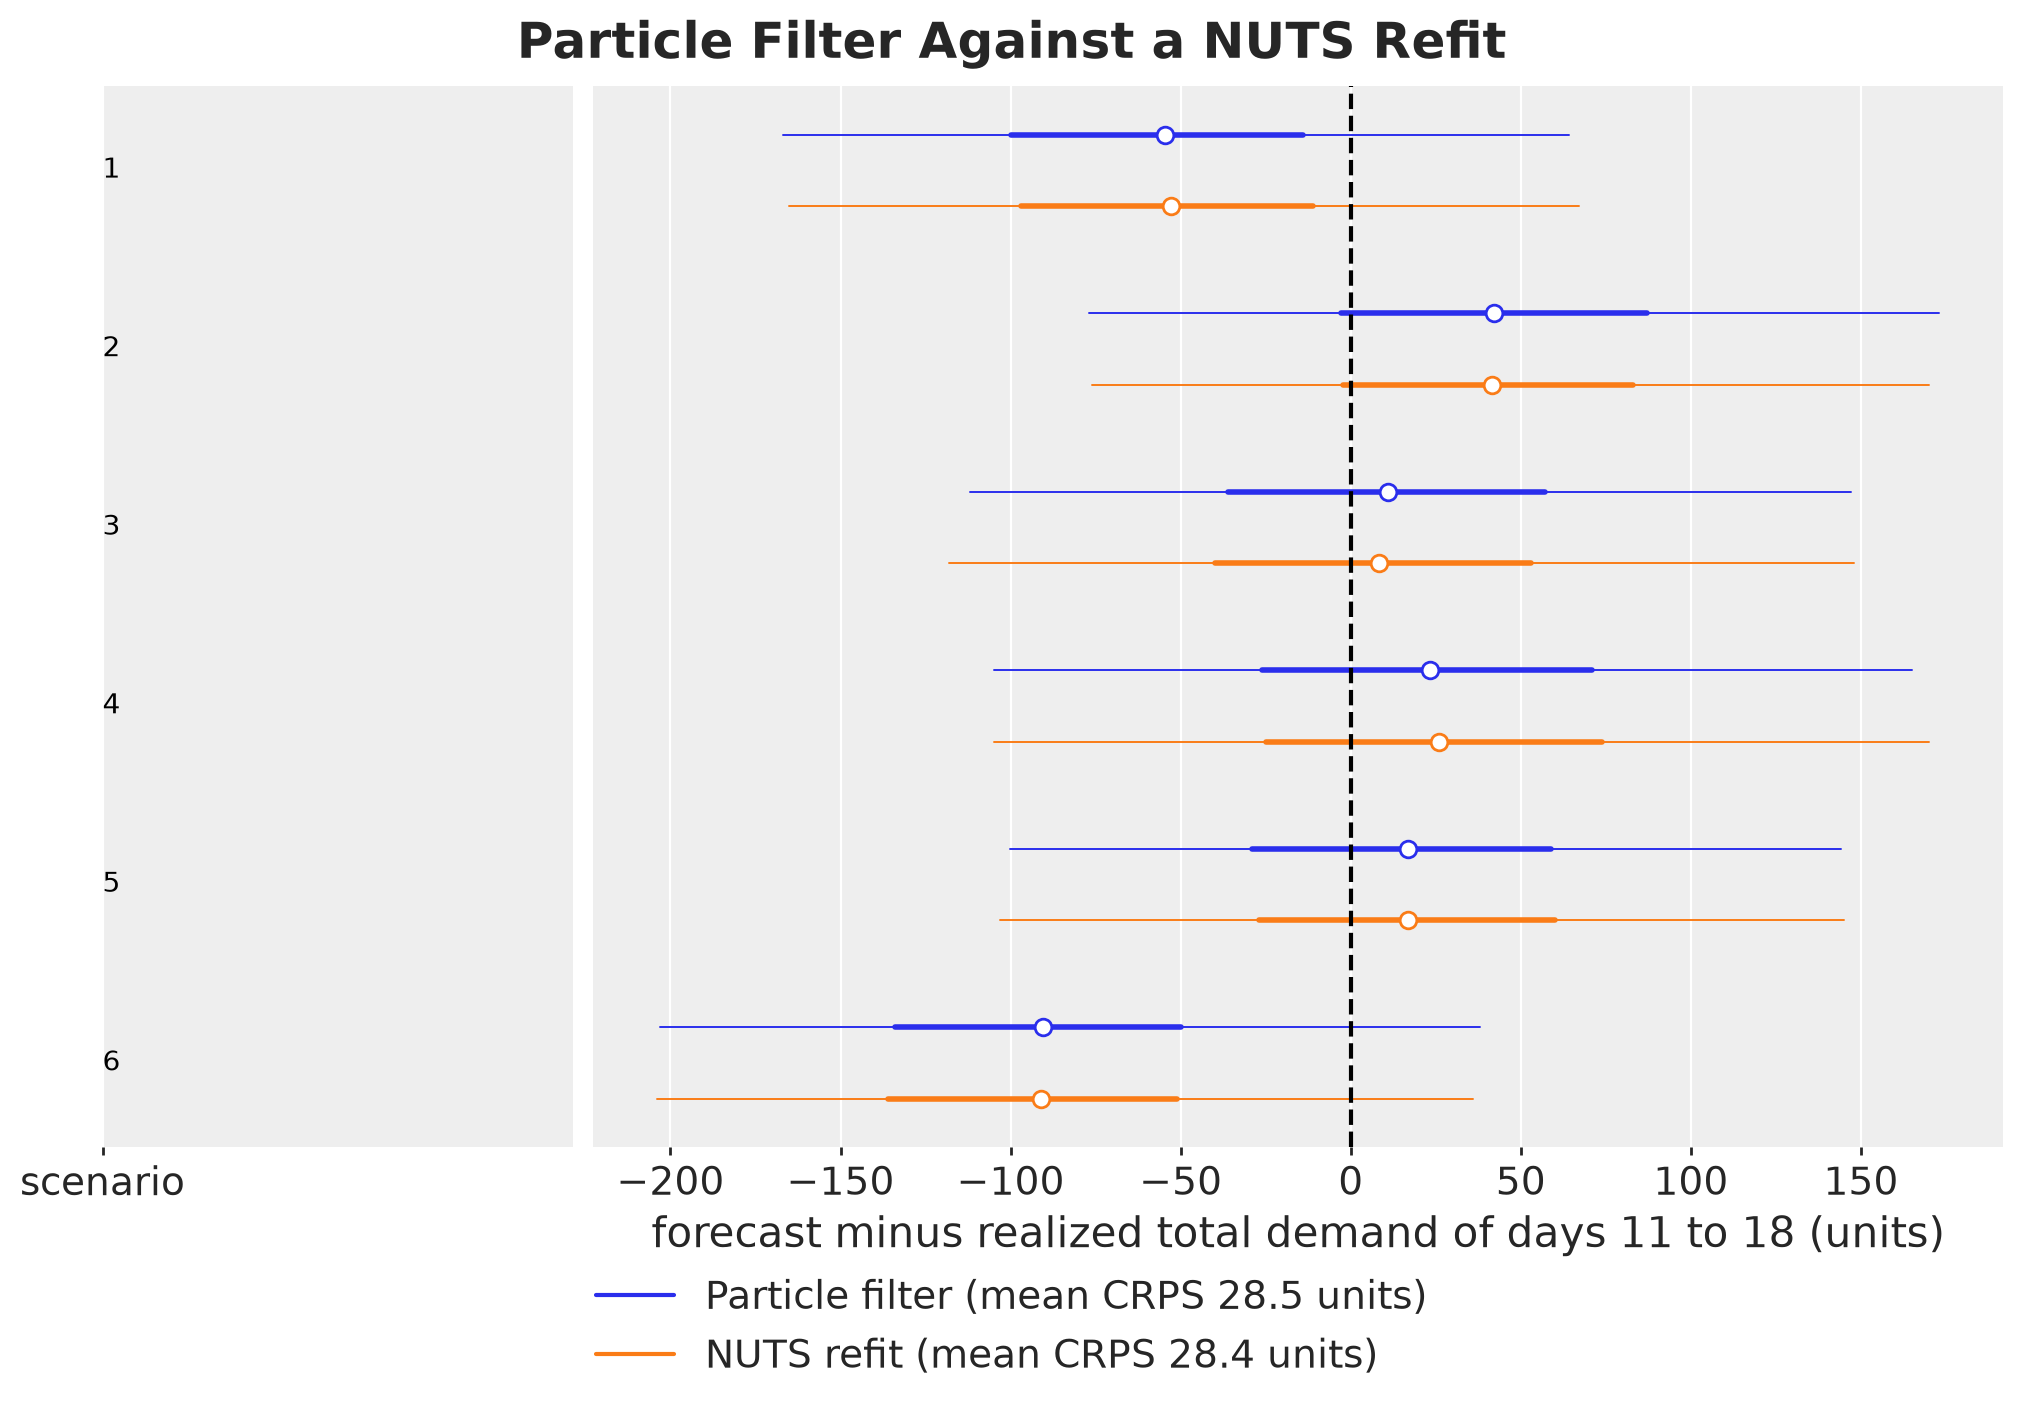

In [25]:
ERROR = "forecast minus realized demand"
error_draws = {
    name: xr.Dataset(
        {ERROR: (("sample", "scenario"), jnp.stack(draws, axis=1))},
        coords={"scenario": np.arange(1, NUM_CHECK_SCENARIOS + 1)},
    )
    for name, draws in forecast_errors.items()
}
# the CRPS of the forecast error against zero, averaged over the scenarios
crps = {
    name: float(
        crps_empirical(
            jnp.asarray(dataset[ERROR].values), jnp.zeros(NUM_CHECK_SCENARIOS)
        ).mean()
    )
    for name, dataset in error_draws.items()
}

pc = az.plot_forest(
    {
        f"{name} (mean CRPS {crps[name]:.1f} units)": dataset
        for name, dataset in error_draws.items()
    },
    sample_dims=["sample"],
    labels=["scenario"],
    color=["C0", "C1"],
    figure_kwargs={"figsize": (10, 7)},
)
ax = pc.viz["plot"].sel(column="forest").item()
ax.axvline(0.0, color="black", linestyle="--")
ax.set(
    xlabel=f"forecast minus realized total demand of days {NUM_OBSERVED + 1} "
    f"to {setup.max_days} (units)"
)
pc.add_legend("model", title="", loc="outside lower center", ncol=1)
pc.viz["figure"].item().suptitle(
    "Particle Filter Against a NUTS Refit", fontsize=18, fontweight="bold"
);

The dots are the means and the thick and thin bars the $50\%$ and $94\%$ intervals. The two forecasts are hard to tell apart in all six scenarios: the means are a few units apart, the intervals have the same width, and the mean CRPS is $28.5$ units for the particle filter and $28.4$ units for the NUTS refit.

The refits have at most $10$ divergent transitions among their $4{,}000$ draws. So on these scenarios the forecast of the filter is close to the forecast of a refit, and we use the filter inside the rolling horizon.

### Daily Solve

Now we put the pieces together. The function `rolling_horizon` runs one demand path, and on every ordering day it does three things:

- **Update.** It updates the belief with the demand of the day before and draws $1{,}000$ scenarios for the days from today on.
- **Solve.** It calls `solve_plan`, a short version of the solver of the fixed plan: projected Adam for $200$ steps, from the current state and from the plan of the day before.
- **Order.** It places the first order of the plan with `inventory_step`, and the day passes.

The rolling horizon needs a filter step and a solve for every scenario and every day, so we run it on the first $300$ scenarios of each test set. We use the same random keys for every lead time.

In [26]:
class RollingHorizonConfig(NamedTuple):
    """Size of the rolling horizon runs."""

    num_test: int = 300  # test scenarios on which we run it
    num_scenarios: int = 1_000  # scenarios of every daily solve
    num_steps: int = 200  # solver steps of every daily solve


class RollingHorizonRun(NamedTuple):
    """Simulation and filter diagnostics of the rolling horizon."""

    simulation: Simulation
    effective_sample_size: Float[Array, "*scenarios horizon"]
    num_distinct: Int[Array, "*scenarios horizon"]  # distinct posterior draws


def solve_plan(
    scenarios: Float[Array, "scenarios days"],
    state: InventoryState,
    first_day: Int[Array, ""],
    plan: Float[Array, " horizon"],
    config: InventoryConfig,
    lead_time: int,
    num_steps: int,
) -> Float[Array, " horizon"]:
    """Projected Adam on the expected loss of a fixed plan from the current state."""
    optimizer = optax.adam(optax.cosine_decay_schedule(1.0, num_steps))

    def loss(plan: Float[Array, " horizon"]) -> Float[Array, ""]:
        simulation = simulate_scenarios(
            fixed_plan, plan, scenarios, state, config, lead_time, first_day
        )
        return simulation.loss.mean()

    def step(
        carry: tuple[Float[Array, " horizon"], optax.OptState], _: None
    ) -> tuple[tuple[Float[Array, " horizon"], optax.OptState], None]:
        plan, opt_state = carry
        updates, opt_state = optimizer.update(jax.grad(loss)(plan), opt_state, plan)
        return (clip_at_zero(plan + updates), opt_state), None

    (plan, _), _ = jax.lax.scan(
        step, (plan, optimizer.init(plan)), None, length=num_steps
    )
    return plan


def rolling_horizon(
    key: PRNGKeyArray,
    demand: Float[Array, " days"],
    particles: Particles,
    plan: Float[Array, " horizon"],
    state: InventoryState,
    config: InventoryConfig,
    lead_time: int,
    rolling_config: RollingHorizonConfig,
) -> RollingHorizonRun:
    """Update the belief, solve the plan again and place one order, day by day."""
    num_days = setup.horizon + lead_time
    num_particles = particles.level.shape[0]

    def decide(
        carry: tuple[InventoryState, Belief, Float[Array, " horizon"]],
        inputs: tuple[Float[Array, ""], Int[Array, ""], PRNGKeyArray],
    ) -> tuple[
        tuple[InventoryState, Belief, Float[Array, " horizon"]],
        RollingHorizonRun,
    ]:
        state, belief, plan = carry
        demand_t, day, key_day = inputs
        key_filter, key_scenarios = random.split(key_day)
        # 1. update the belief with the demand of the day before (none on day one)
        updated, effective_sample_size = filter_step(
            key_filter, belief, state.demand_history[-1], day - 1
        )
        belief = jax.tree.map(
            lambda new, old: jnp.where(day > 0, new, old), updated, belief
        )
        effective_sample_size = jnp.where(
            day > 0, effective_sample_size, 1.0 * num_particles
        )
        num_distinct = (jnp.diff(jnp.sort(belief.particles.draw)) > 0).sum() + 1
        # 2. scenarios for the days from today on
        scenarios = sample_scenarios(
            key_scenarios, belief, day, num_days, rolling_config.num_scenarios
        )
        # 3. solve the fixed plan again from the current stock and pipeline
        plan = solve_plan(
            scenarios, state, day, plan, config, lead_time, rolling_config.num_steps
        )
        # 4. place the order of today and let the day pass
        state, simulation = inventory_step(
            fixed_plan, plan, state, demand_t, day, config, lead_time
        )
        return (state, belief, plan), RollingHorizonRun(
            simulation, effective_sample_size, num_distinct
        )

    (state, _, plan), run = jax.lax.scan(
        decide,
        (state, uniform_belief(particles), plan),
        (
            demand[: setup.horizon],
            jnp.arange(setup.horizon),
            random.split(key, setup.horizon),
        ),
    )
    # the days after the last order: the pipeline arrives and is sold
    last_days = simulate(
        fixed_plan,
        plan,
        demand[setup.horizon :],
        state,
        config,
        lead_time,
        setup.horizon,
    )
    simulation = jax.tree.map(
        lambda first, last: jnp.concatenate([first, last]), run.simulation, last_days
    )
    return run._replace(simulation=simulation)

We run the rolling horizon for every lead time on both test sets. The solve of day one starts from the trained fixed plan.

In [27]:
%%time

rolling_config = RollingHorizonConfig()
rng_key, key_rolling = random.split(rng_key)
# one key per test scenario, shared by the lead times and the test sets
keys_rolling = random.split(key_rolling, rolling_config.num_test)


def make_rolling_horizon(
    lead_time: int,
) -> Callable[
    [UInt32[Array, "scenarios 2"], Float[Array, "scenarios days"]], RollingHorizonRun
]:
    """The rolling horizon of one lead time, compiled for a batch of scenarios."""
    plan = policies[lead_time, PolicyName.FIXED_PLAN].params
    state = initial_state(lead_time)
    return jax.jit(
        jax.vmap(
            lambda key, path: rolling_horizon(
                key, path, particles_opt, plan, state, config, lead_time, rolling_config
            )
        )
    )


rolling_runs: dict[tuple[ScenarioSet, int], RollingHorizonRun] = {}

for lead_time in setup.lead_times:
    run_scenarios = make_rolling_horizon(lead_time)

    for test_set, demand in demand_test.items():
        rolling_runs[test_set, lead_time] = run_scenarios(
            keys_rolling, trim_demand(demand, lead_time)[: rolling_config.num_test]
        )

CPU times: user 30min 52s, sys: 1min, total: 31min 53s
Wall time: 2min 47s


We run two checks before we look at the results. First, on day one we have not observed any demand, so the rolling horizon solves the problem of the fixed plan on new scenarios, and its first order has to be close to the first order of the fixed plan. Second, the filter has to keep enough particles. We look at the effective sample size and at the number of distinct posterior draws among the particles, as averages over the test scenarios on the day where they are lowest.

In [28]:
for lead_time in setup.lead_times:
    first_orders = rolling_runs[ScenarioSet.FORECAST, lead_time].simulation.orders[:, 0]
    first_order_plan = policies[lead_time, PolicyName.FIXED_PLAN].params[0]
    assert float(jnp.abs(first_orders - first_order_plan).mean()) < 2.0

for test_set in demand_test:
    # the filter does not depend on the lead time
    run = rolling_runs[test_set, 0]
    assert float(run.effective_sample_size.mean(axis=0).min()) > 600
    assert float(run.num_distinct.mean(axis=0).min()) > 600

Both checks pass. For every lead time the first order of the rolling horizon is within $2$ units of the first order of the fixed plan on average. On every day the filter keeps an average effective sample size above $600$ of the $1{,}000$ particles and more than $600$ distinct posterior draws.

Note that the rolling horizon is the only one of the four policies that solves an optimization problem on every day of every scenario. The cell above makes $36{,}000$ decisions in about $3$ minutes, about $5$ milliseconds each when they run in batches. A trained policy is one function call per day.

## Out of Sample Evaluation

We score every policy on the two test sets. The trained policies are cheap to run, so we score them on all $3{,}000$ scenarios of each test set. The rolling horizon has $300$ scenarios, so every comparison with it uses those $300$ scenarios for both sides. We also simulate the trained policies on the training set, to see how much of a gain is left on new scenarios.

We record six scores. The stockout scores count only the days of the cost window.

- **Expected loss.** The mean of the loss over the scenarios.
- **CVaR of the loss.** The mean of the worst $5\%$ of the scenario losses. We look at it in the *Tail Risk* section.
- **Stockout probability per day.** The fraction of scenario and day pairs with a lost sale.
- **Probability of a stockout in the cost window.** The fraction of scenarios with at least one lost sale.
- **Units ordered.** The mean over the scenarios of the sum of the orders.
- **Stock at the end of the cost window.** The mean over the scenarios of the stock on hand on the last day.

In [29]:
class Metric(StrEnum):
    """Names of the scores."""

    EXPECTED_LOSS = "expected loss"
    CVAR = f"CVaR of loss (worst {ALPHA:.0%})"
    STOCKOUT = "stockout probability per day"
    WINDOW = "probability of a stockout in the cost window"
    ORDERED = "units ordered"
    ENDING_STOCK = "stock at the end of the cost window"


def summarize(simulation: Simulation, lead_time: int) -> dict[Metric, float]:
    """Scores of one policy over a set of scenarios."""
    # a day of the cost window with lost sales above the tolerance
    stockout = simulation.lost_sales[:, lead_time:] > STOCKOUT_TOL
    return {
        Metric.EXPECTED_LOSS: float(simulation.loss.mean()),
        Metric.CVAR: float(cvar(simulation.loss)),
        Metric.STOCKOUT: float(stockout.mean()),
        Metric.WINDOW: float(stockout.any(axis=1).mean()),
        Metric.ORDERED: float(simulation.orders.sum(axis=1).mean()),
        Metric.ENDING_STOCK: float(simulation.inventory[:, -1].mean()),
    }


simulations: dict[tuple[ScenarioSet, int, PolicyName], Simulation] = {}

for scenario_set, demand in {ScenarioSet.TRAINING: demand_train, **demand_test}.items():
    for (lead_time, name), (policy, params) in policies.items():
        simulations[scenario_set, lead_time, name] = simulate_scenarios_jit(
            policy,
            params,
            trim_demand(demand, lead_time),
            initial_state(lead_time),
            config,
            lead_time,
        )

for (test_set, lead_time), run in rolling_runs.items():
    simulations[test_set, lead_time, PolicyName.ROLLING_HORIZON] = run.simulation

results = pl.DataFrame(
    [
        {
            "scenario set": str(scenario_set),
            "lead time": lead_time,
            "policy": str(name),
            **summarize(simulation, lead_time),
        }
        for (scenario_set, lead_time, name), simulation in simulations.items()
    ]
)

### Expected Loss

Let's start with the first question: how much of the expected loss of the fixed plan do we remove when the order of each day depends on the stock? The next figure shows the expected loss of the fixed plan, the two base-stock policies and the neural policy on the $3{,}000$ scenarios of each test set, by lead time.

The rolling horizon is not in this figure because it runs on $300$ scenarios. We compare it in the *Rolling Horizon Comparison* section.

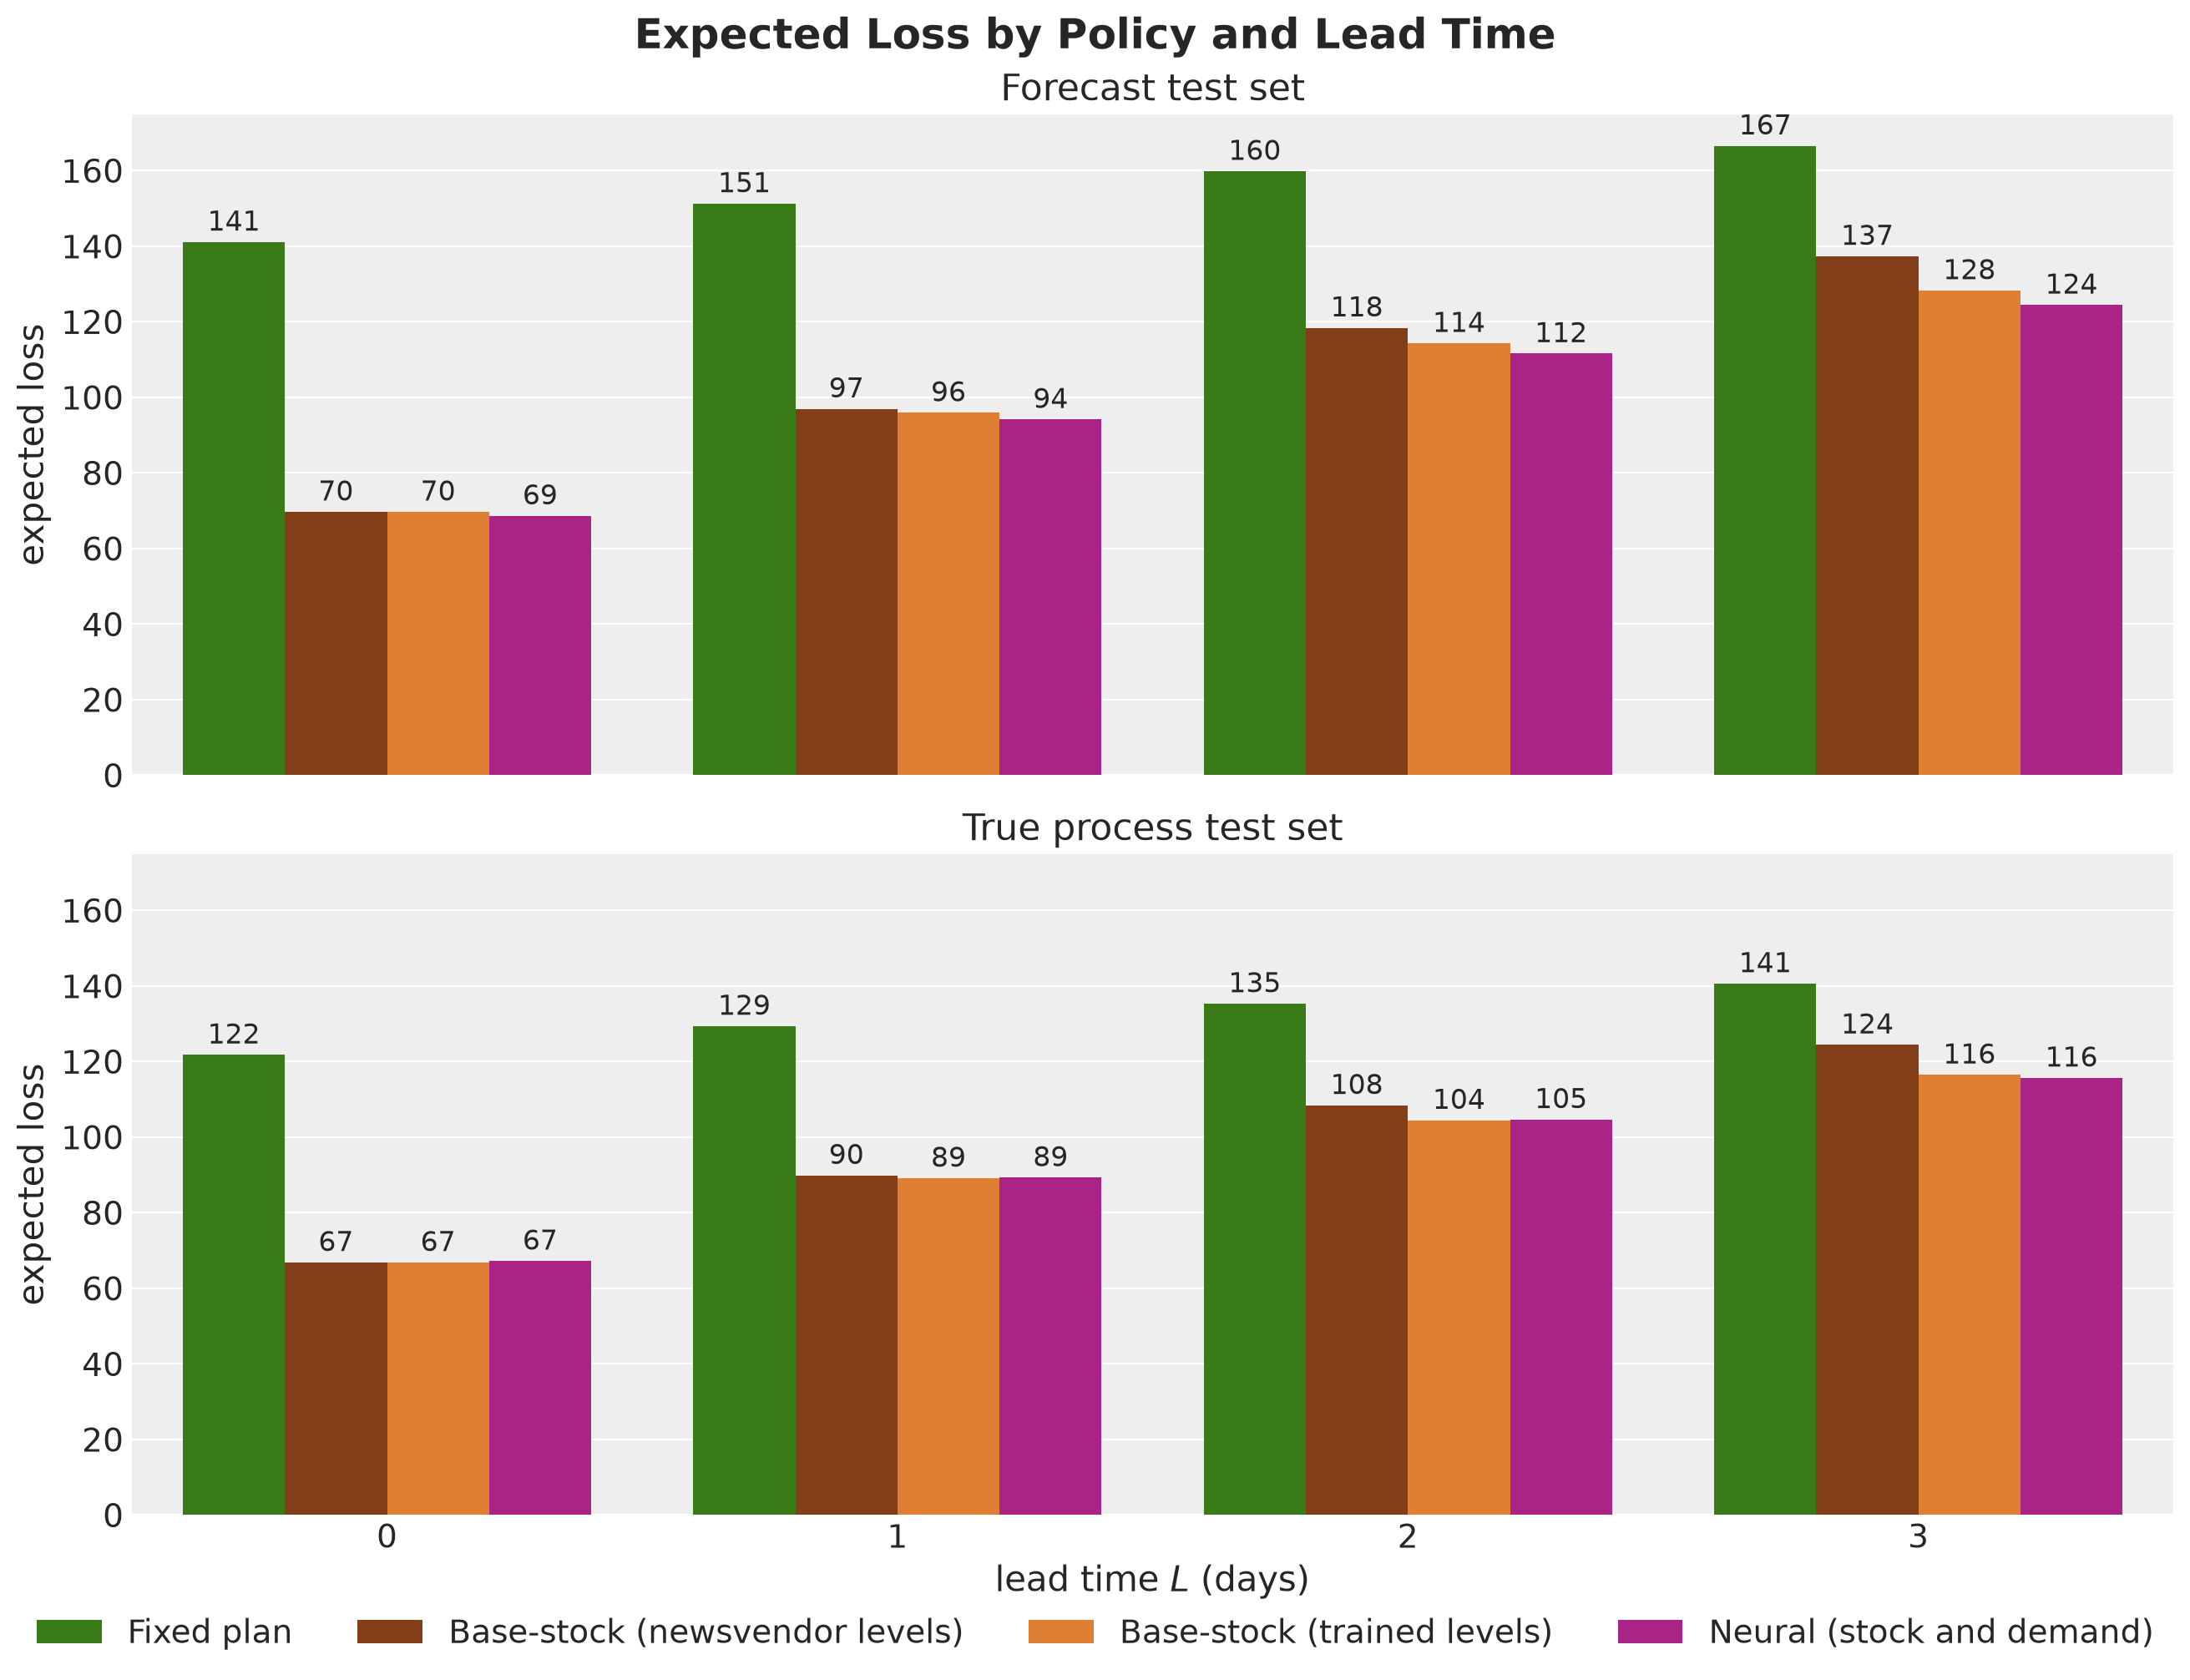

In [30]:
BAR_POLICIES = [
    PolicyName.FIXED_PLAN,
    PolicyName.NEWSVENDOR,
    PolicyName.BASE_STOCK,
    PolicyName.NEURAL,
]

fig, axes = plt.subplots(
    nrows=2, figsize=(13, 10), sharex=True, sharey=True, layout="constrained"
)

for ax, test_set in zip(axes, demand_test, strict=True):
    sns.barplot(
        data=results.filter(
            (pl.col("scenario set") == test_set) & pl.col("policy").is_in(BAR_POLICIES)
        ),
        x="lead time",
        y=Metric.EXPECTED_LOSS,
        hue="policy",
        hue_order=BAR_POLICIES,
        palette=POLICY_COLORS,
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="{:.0f}", fontsize=12, padding=2)

    ax.get_legend().remove()
    ax.set(title=test_set.capitalize(), xlabel="", ylabel=Metric.EXPECTED_LOSS)

axes[-1].set(xlabel="lead time $L$ (days)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=4)
fig.suptitle("Expected Loss by Policy and Lead Time", fontsize=18, fontweight="bold");

Let's read the upper panel, the forecast test set, first.

- **Fixed plan.** The expected loss is $141$ for $L = 0$ and $167$ for $L = 3$. For $L = 0$ this is the expected cost plan of the first post on a new sample of scenarios.
- **Base-stock (newsvendor levels).** With no lead time the expected loss is $70$, about half of the loss of the fixed plan, and we did not need an optimizer. For $L = 3$ it is $137$, about $18\%$ below the fixed plan.
- **Base-stock (trained levels).** Training the levels changes nothing for $L = 0$. It lowers the expected loss by $1$ for $L = 1$ and by $9$ for $L = 3$.
- **Neural (stock and demand).** The network lowers the expected loss by a further $1$ to $4$.

On the true process test set the first three policies compare in the same way, with a lower loss for every policy. The neural policy is the exception: on the true process it stays within $1$ of the trained base-stock policy, and the sign of the difference changes with the lead time.

So here is the answer to the first question. With no lead time a policy that looks only at the stock removes about half of the expected loss of the fixed plan on the forecast test set. The share is smaller for every extra day of lead time, and it is about a quarter for $L = 3$ with trained levels. On the true process test set the shares go from $45\%$ to $17\%$.

The lead time matters because an order answers to what we observe today and arrives $L$ days later. The longer the lead time, the more days of demand an order has to cover without seeing them, and the closer a policy is to a plan.

### Paired Differences

The policies other than the fixed plan have expected losses within a few percent of each other, and an average over $3{,}000$ scenarios has a Monte Carlo error of the same order. The policies run on the same scenarios, so for each pair of policies we take the difference of the two losses in every scenario. The mean of these differences has a much smaller Monte Carlo error than the difference of the two means, and we report it with two Monte Carlo standard errors.

Note that these error bars are about the mean. The spread of the difference across the scenarios is much wider, and we are interested in the expected loss. The training set has $5$ scenarios per posterior draw, which are not independent, so there we average the scenarios of a draw before we compute the standard error.

The next figure shows three such differences. Each panel shows the loss of one policy minus the loss of the policy that adds one ingredient to it, so a positive value means that the ingredient lowers the loss:

- **Trained levels.** The newsvendor levels against the trained levels.
- **Stock only.** The trained base-stock policy against the neural policy without the demand history.
- **Stock and demand.** The neural policy without the demand history against the one with it.

We show the differences on the training set and on the two test sets.

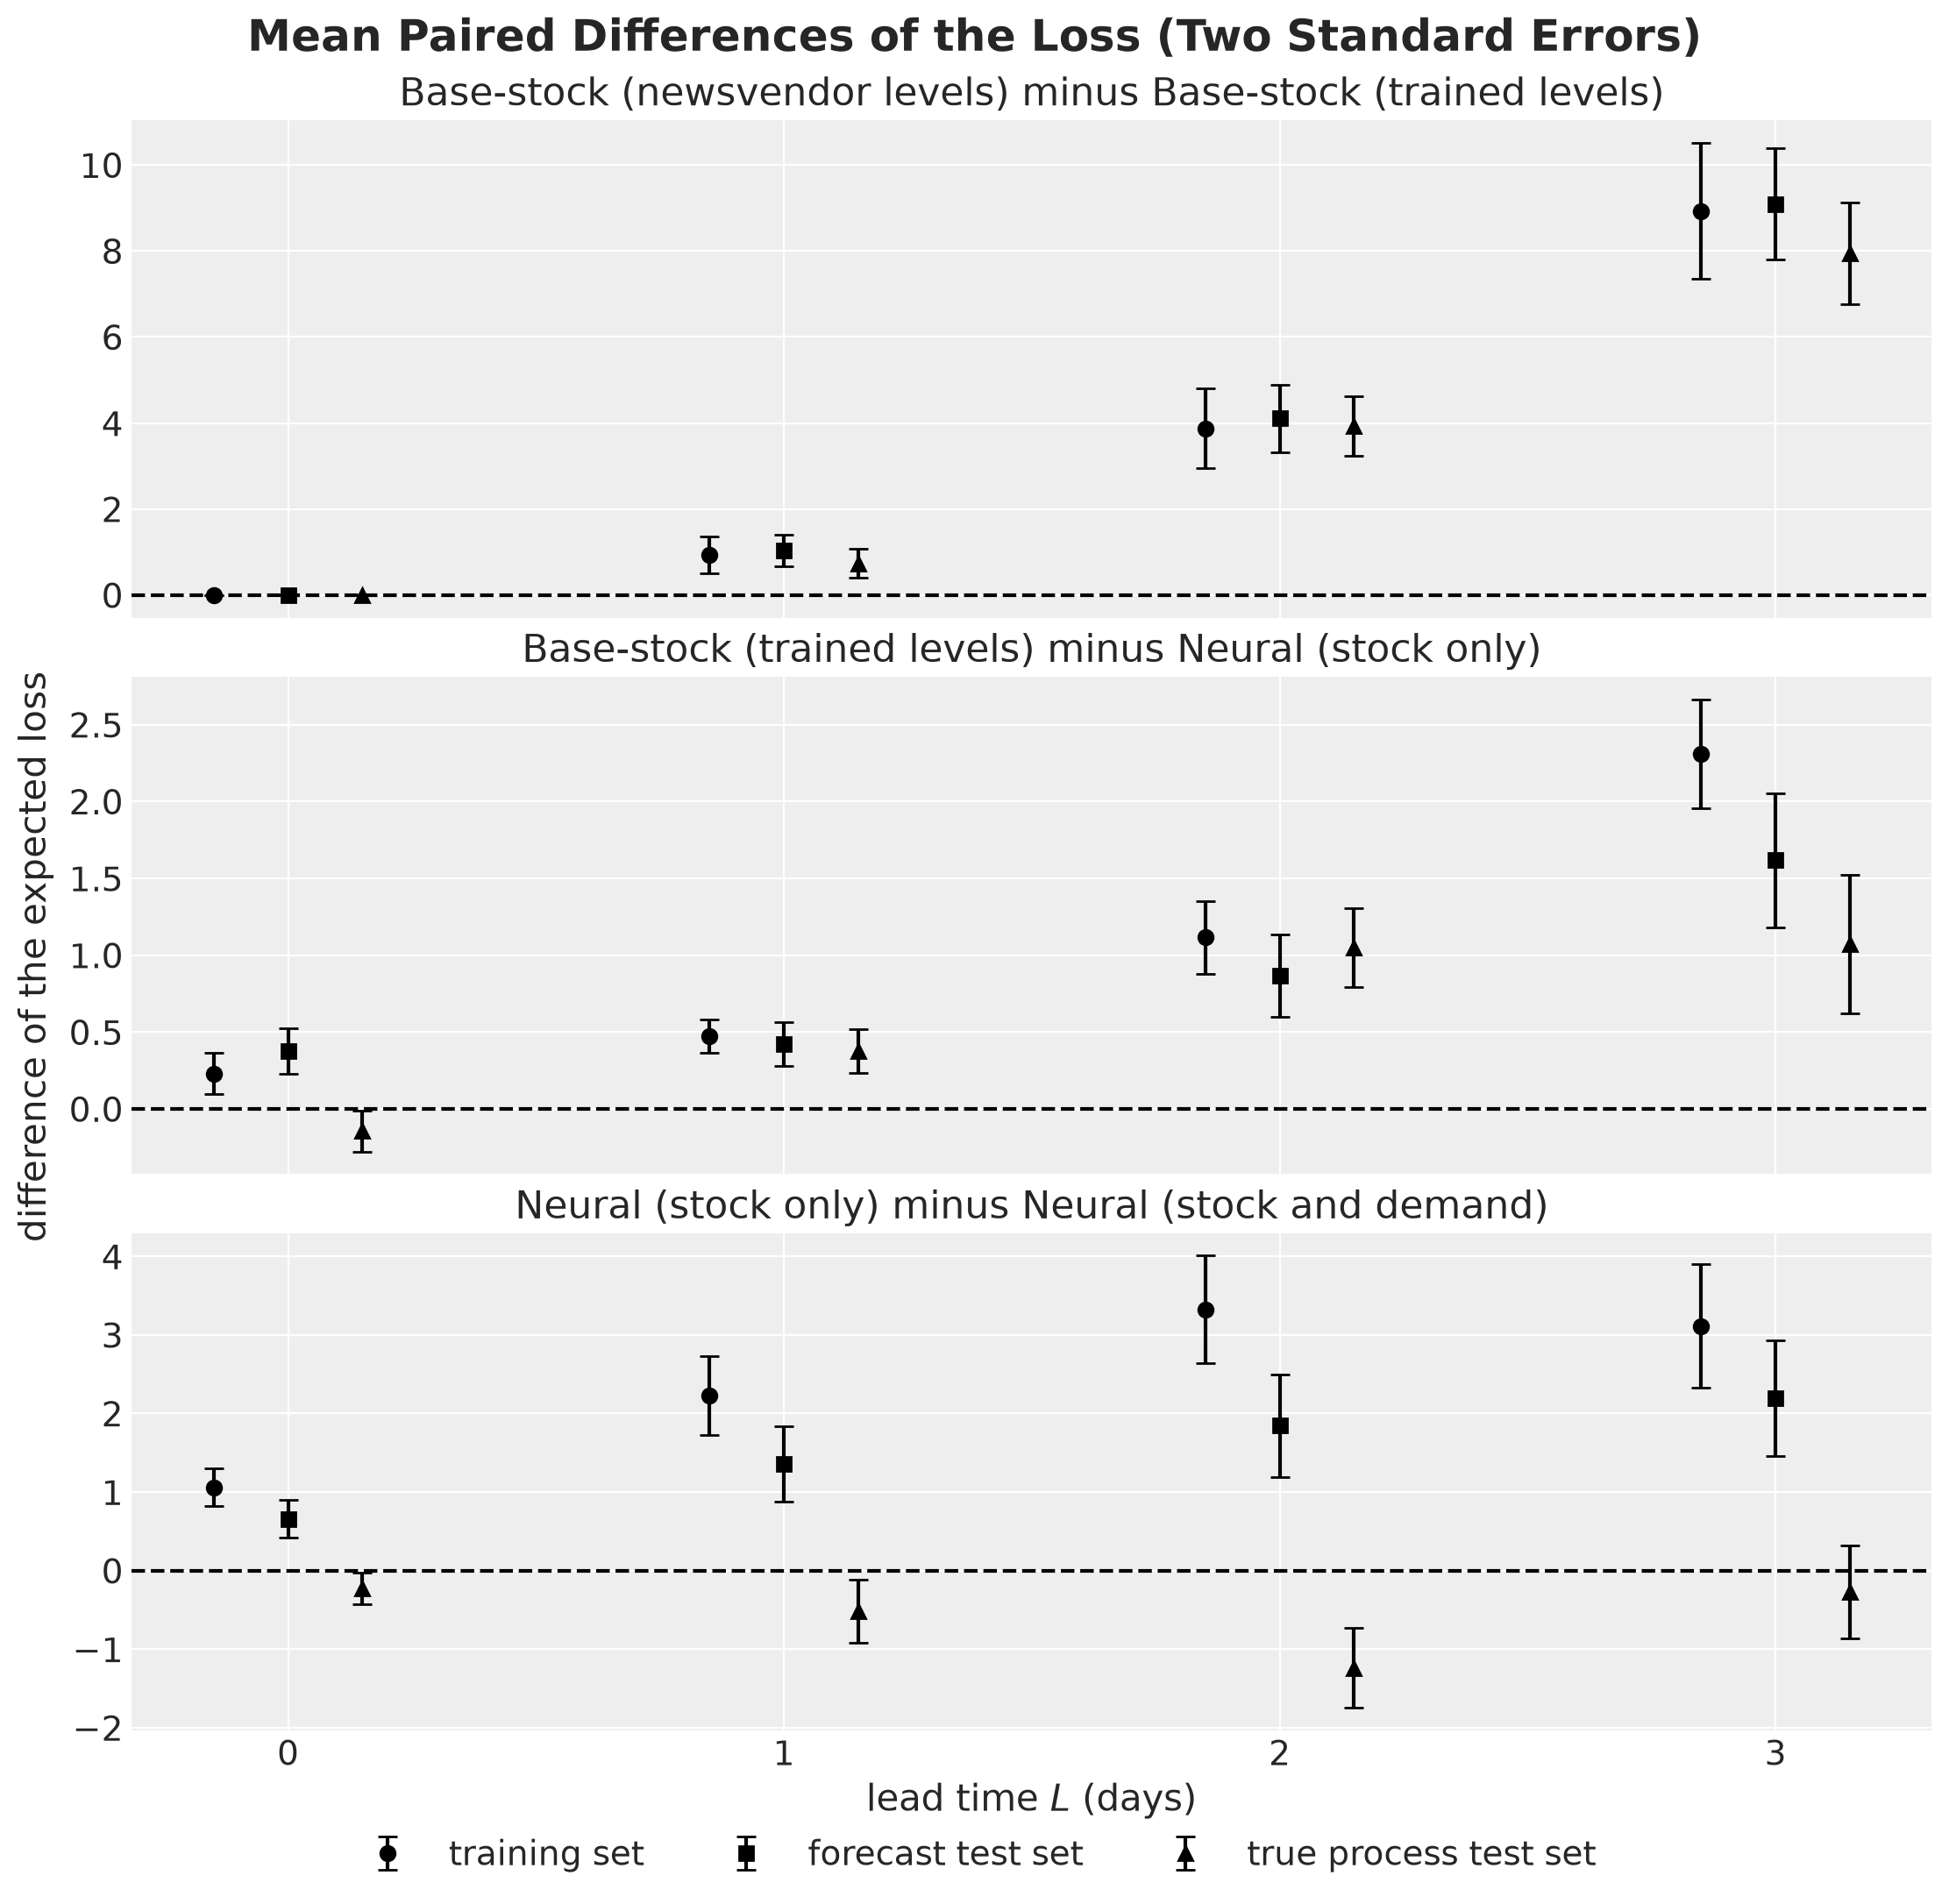

In [31]:
class Estimate(NamedTuple):
    """Mean of a paired difference with two Monte Carlo standard errors."""

    mean: float
    error: float


def mean_difference(
    difference: Float[Array, " scenarios"], num_paths: int = 1
) -> Estimate:
    """Mean and two standard errors of a difference over scenarios.

    With `num_paths` scenarios per posterior draw we average the scenarios of a
    draw first, since they are not independent.
    """
    by_draw = difference.reshape(num_paths, -1).mean(axis=0)
    return Estimate(
        float(by_draw.mean()), 2 * float(by_draw.std() / jnp.sqrt(by_draw.shape[0]))
    )


SET_MARKERS = {
    ScenarioSet.TRAINING: "o",
    ScenarioSet.FORECAST: "s",
    ScenarioSet.TRUE_PROCESS: "^",
}


def plot_differences(
    pairs: list[tuple[PolicyName, PolicyName]],
    scenario_sets: list[ScenarioSet],
    num_scenarios: int | None = None,
) -> plt.Figure:
    """Mean paired difference of the loss by lead time, with two standard errors.

    One panel per pair (loss of the first policy minus loss of the second) and one
    marker per scenario set. With `num_scenarios` we use the first scenarios of
    every set.
    """
    fig, axes = plt.subplots(
        nrows=len(pairs),
        figsize=(11, 3.6 * len(pairs)),
        sharex=True,
        layout="constrained",
    )
    offsets = np.linspace(-0.15, 0.15, len(scenario_sets))

    for ax, (first, second) in zip(axes, pairs, strict=True):
        for offset, scenario_set in zip(offsets, scenario_sets, strict=True):
            num_paths = PATHS_PER_DRAW if scenario_set == ScenarioSet.TRAINING else 1
            estimates = [
                mean_difference(
                    simulations[scenario_set, lead_time, first].loss[:num_scenarios]
                    - simulations[scenario_set, lead_time, second].loss[:num_scenarios],
                    num_paths,
                )
                for lead_time in setup.lead_times
            ]
            ax.errorbar(
                np.asarray(setup.lead_times) + offset,
                [estimate.mean for estimate in estimates],
                yerr=[estimate.error for estimate in estimates],
                fmt=SET_MARKERS[scenario_set],
                color="black",
                capsize=4,
                label=scenario_set,
            )

        ax.axhline(0.0, color="black", linestyle="--")
        ax.set(title=f"{first} minus {second}")

    axes[-1].set(xlabel="lead time $L$ (days)", xticks=setup.lead_times)
    fig.supylabel(
        "difference of the expected loss", fontsize=plt.rcParams["axes.labelsize"]
    )
    fig.legend(
        *axes[0].get_legend_handles_labels(),
        loc="outside lower center",
        ncol=len(scenario_sets),
    )
    return fig


fig = plot_differences(
    [
        (PolicyName.NEWSVENDOR, PolicyName.BASE_STOCK),
        (PolicyName.BASE_STOCK, PolicyName.NEURAL_STOCK),
        (PolicyName.NEURAL_STOCK, PolicyName.NEURAL),
    ],
    list(ScenarioSet),
)
fig.suptitle(
    "Mean Paired Differences of the Loss (Two Standard Errors)",
    fontsize=18,
    fontweight="bold",
);

Here is what we see, panel by panel.

- **Trained levels.** The gain of the training is about the same on the three sets. It is zero for $L = 0$ and grows from about $1$ for $L = 1$ to $8$ or $9$ for $L = 3$, so it carries over from the training set to both test sets.
- **Stock only.** On the forecast test set the network without the demand history lowers the expected loss at every lead time, by about $0.4$ for $L \leq 1$ and by $1.6$ for $L = 3$. For $L = 0$ this gain has to come from the demand that the stock carries: for a rule that ignores the demand the days are separate problems, and the gain is not there on the true process test set. From $L = 2$ on the network also sees each order in the pipeline, and the base-stock policy sees only their sum.
- **Stock and demand.** On the forecast test set the demand history lowers the expected loss further, by about $0.7$ for $L = 0$ and $2.2$ for $L = 3$. This is about $60\%$ of the gain on the training set. On the true process test set the demand history does not lower the loss at any lead time. It raises it by about $0.2$, $0.5$ and $1.2$ for $L = 0, 1, 2$, and for $L = 3$ the interval contains zero.

So the gain of the demand history depends on where the demand comes from. Let's look at this more closely.

### Demand History

Recall the correlations of the *Neural Policy* section: $0.32$ between the early and the late demand in the training set, and $0.07$ in the true process test set. So in the scenarios from the true process the demand of the last week says little about the demand to come.

To understand both results we look at what the network does with the demand history and in which scenarios it pays. We take the lead time $L = 2$, the first one with an order in the pipeline when we decide.

First, we look at the base-stock level of the neural policy on ordering day $11$, when the last $7$ days contain three promotion days. The next figure shows the level against the demand of those $7$ days, in every scenario of the forecast test set. We write the level as its distance from the trained base-stock level and the demand relative to its mean over the scenarios.

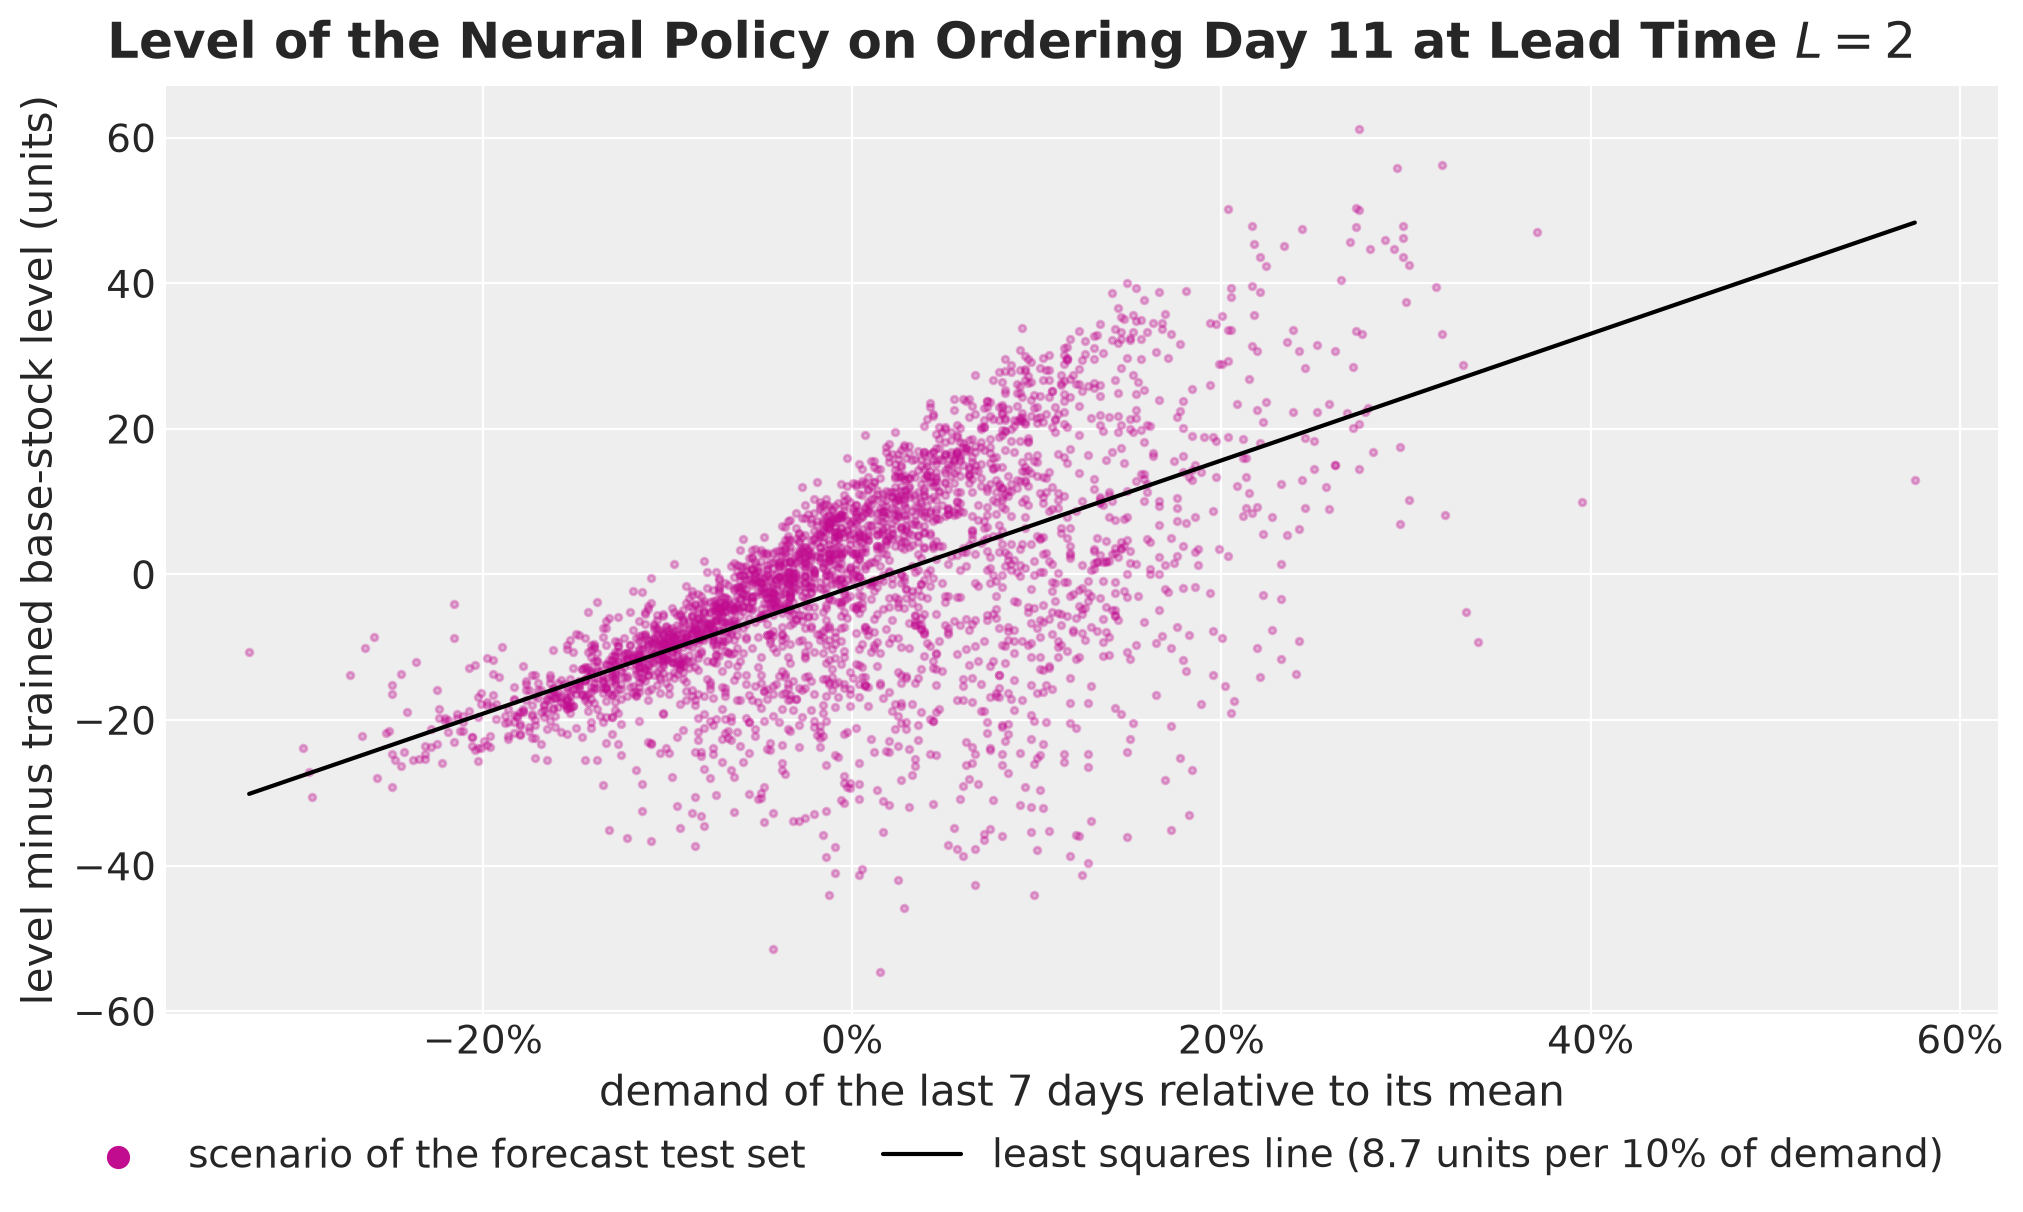

In [32]:
ORDERING_DAY = 11


def observe_day(day: int, name: PolicyName) -> Observation:
    """What a policy observes on a day in every scenario of the forecast test set."""
    policy, params = policies[LEAD_TIME_DETAIL, name]

    def observe_path(path: Float[Array, " days"]) -> Observation:
        def step(
            state: InventoryState, inputs: tuple[Float[Array, ""], Int[Array, ""]]
        ) -> tuple[InventoryState, None]:
            demand_t, day_t = inputs
            state, _ = inventory_step(
                policy, params, state, demand_t, day_t, config, LEAD_TIME_DETAIL
            )
            return state, None

        state, _ = jax.lax.scan(
            step, initial_state(LEAD_TIME_DETAIL), (path[:day], jnp.arange(day))
        )
        return observe(state, jnp.asarray(day), LEAD_TIME_DETAIL)

    return jax.vmap(observe_path)(demand_test[ScenarioSet.FORECAST])


neural_detail = make_neural_policy(LEAD_TIME_DETAIL)
params_neural = policies[LEAD_TIME_DETAIL, PolicyName.NEURAL].params
observation = observe_day(ORDERING_DAY - 1, PolicyName.NEURAL)
recent_demand = observation.demand_history.sum(axis=1)
relative_demand = np.asarray(recent_demand / recent_demand.mean() - 1)
level_neural = DEMAND_SCALE * params_neural["levels"][ORDERING_DAY - 1] + jax.vmap(
    neural_detail.correction, in_axes=(None, 0)
)(params_neural, observation)
level_distance = np.asarray(
    level_neural
    - policies[LEAD_TIME_DETAIL, PolicyName.BASE_STOCK].params[ORDERING_DAY - 1]
)
slope, intercept = np.polyfit(relative_demand, level_distance, deg=1)
demand_range = np.array([relative_demand.min(), relative_demand.max()])

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    relative_demand,
    level_distance,
    s=6,
    alpha=0.3,
    color=POLICY_COLORS[PolicyName.NEURAL],
    label=f"scenario of the {ScenarioSet.FORECAST}",
)
ax.plot(
    demand_range,
    intercept + slope * demand_range,
    color="black",
    label=f"least squares line ({slope / 10:.1f} units per $10\\%$ of demand)",
)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(
    xlabel="demand of the last $7$ days relative to its mean",
    ylabel="level minus trained base-stock level (units)",
)
legend = fig.legend(loc="outside lower center", ncol=2, markerscale=3)
legend.legend_handles[0].set_alpha(1.0)
fig.suptitle(
    f"Level of the Neural Policy on Ordering Day {ORDERING_DAY} "
    f"at Lead Time $L = {LEAD_TIME_DETAIL}$",
    fontsize=18,
    fontweight="bold",
);

The level of the neural policy grows with the recent demand. On average a week with $10\%$ more demand than the mean raises the level by about $9$ units. The level also depends on the stock, the pipeline and the order of the demands inside the week, so the points do not lie on one line.

Next, we look at where this reaction pays. We group the scenarios of the forecast test set by the **expected demand** behind them: the expected total demand of the ordering days under the parameters and the latent level of the scenario. We write it on the log scale and in standard deviations from its mean, so zero is the center of the forecast.

For each of eight groups of equal size the next figure shows the mean gain of the demand history, the loss of `Neural (stock only)` minus the loss of `Neural (stock and demand)`. The orange line is the expected demand of the true process.

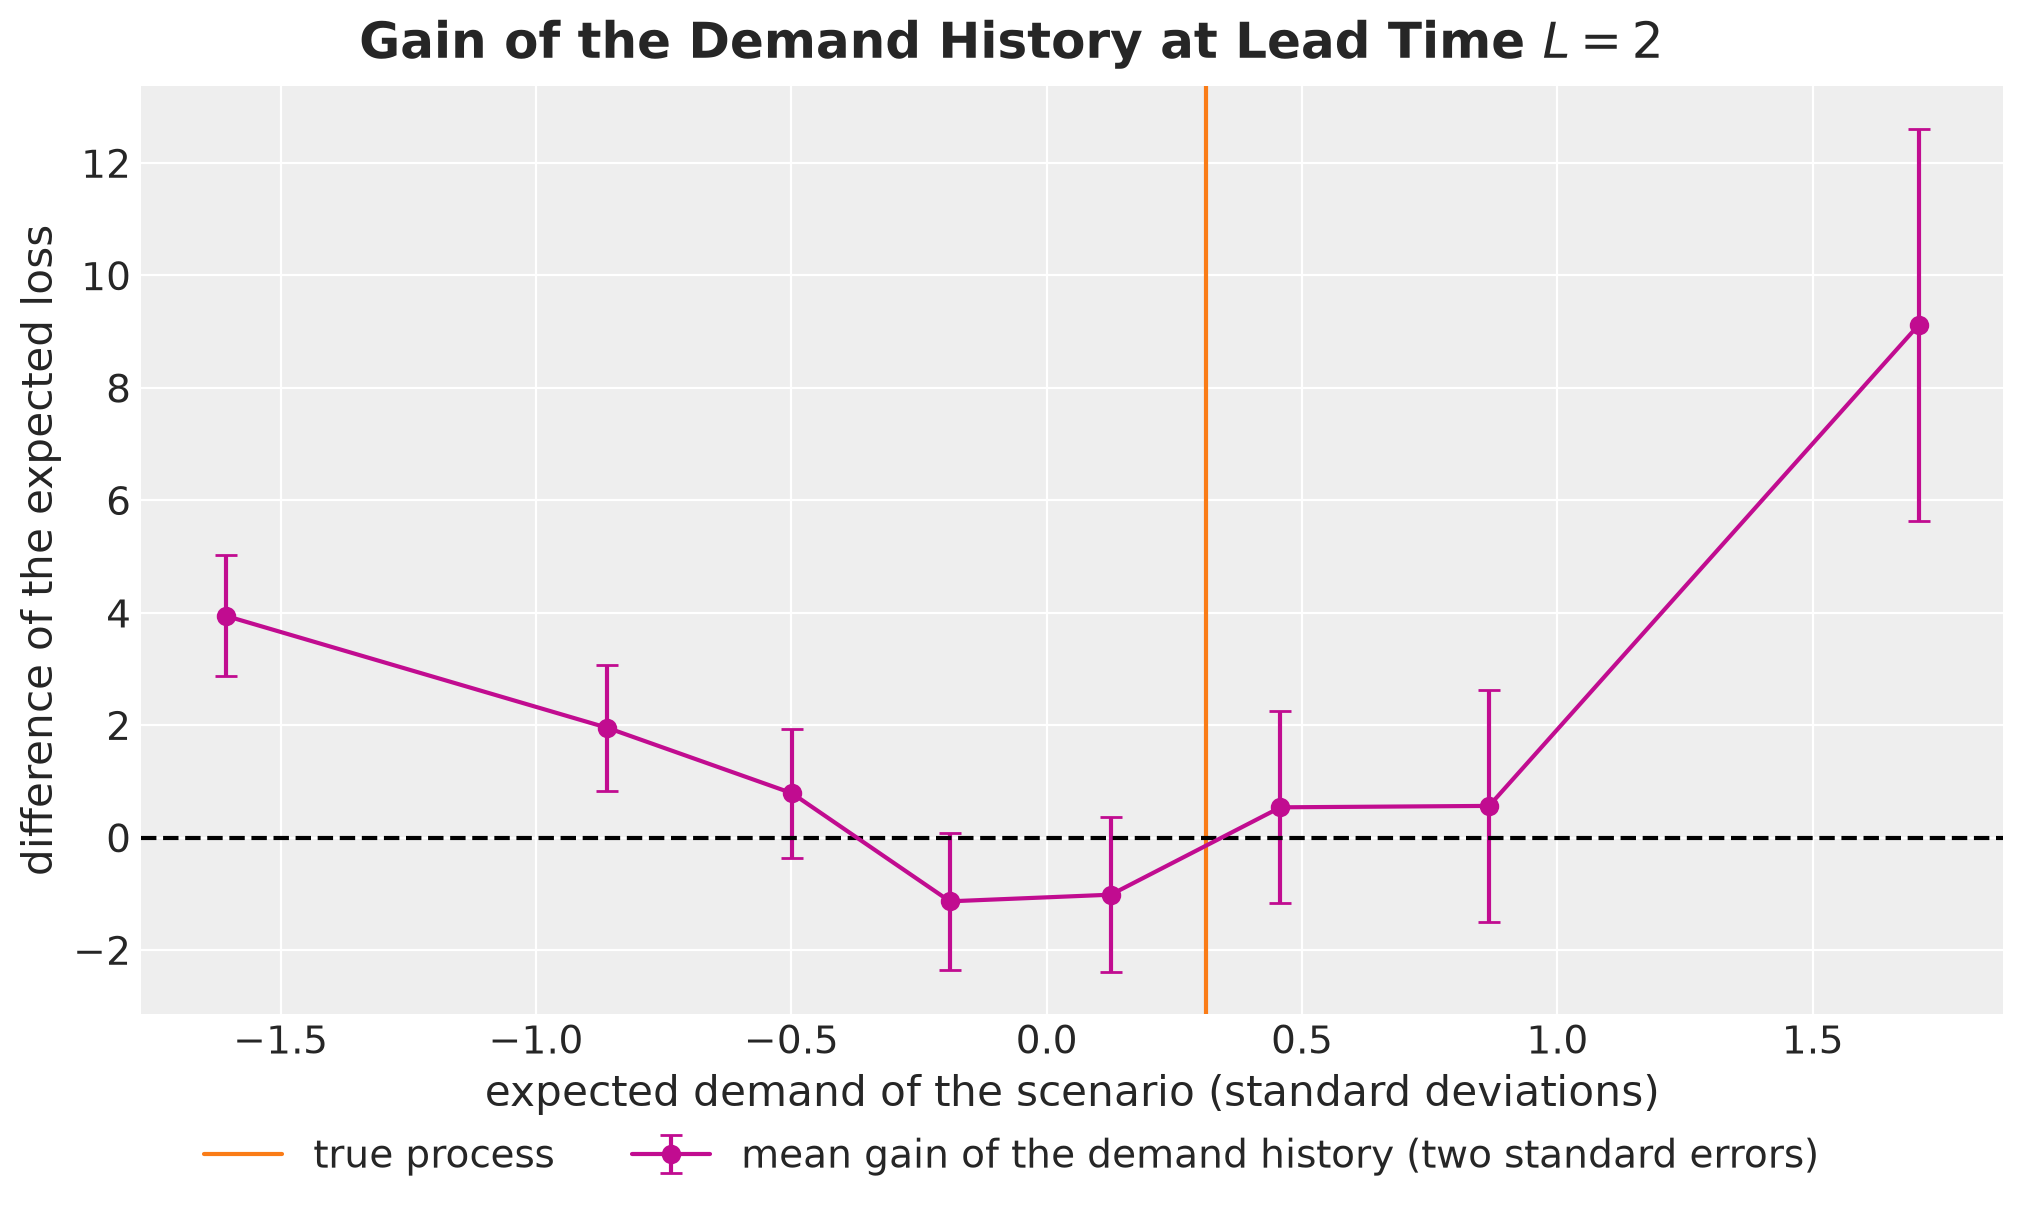

In [33]:
def expected_total_demand(particles: Particles) -> Float[Array, " particles"]:
    """Expected demand of the ordering days with the level of the last observed day."""
    return jax.vmap(lambda day: expected_demand(particles, particles.level, day))(
        jnp.arange(setup.horizon)
    ).sum(axis=0)


log_total = jnp.log(expected_total_demand(particles_test))


def standardize(particles: Particles) -> Float[Array, " particles"]:
    """Log expected demand in standard deviations from the center of the forecast."""
    return (
        jnp.log(expected_total_demand(particles)) - log_total.mean()
    ) / log_total.std()


expected_demand_test = standardize(particles_test)
expected_demand_true = float(
    standardize(jax.tree.map(lambda leaf: leaf[None], true_particle))[0]
)
gain = (
    simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, PolicyName.NEURAL_STOCK].loss
    - simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, PolicyName.NEURAL].loss
)
NUM_GROUPS = 8
# rank of every scenario by its expected demand, cut into groups of equal size
group = jnp.argsort(jnp.argsort(expected_demand_test)) * NUM_GROUPS // gain.shape[0]
estimates = [mean_difference(gain[group == g]) for g in range(NUM_GROUPS)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(
    [float(expected_demand_test[group == g].mean()) for g in range(NUM_GROUPS)],
    [estimate.mean for estimate in estimates],
    yerr=[estimate.error for estimate in estimates],
    fmt="o-",
    color=POLICY_COLORS[PolicyName.NEURAL],
    capsize=4,
    label="mean gain of the demand history (two standard errors)",
)
ax.axvline(expected_demand_true, color="C1", label="true process")
ax.axhline(0.0, color="black", linestyle="--")
ax.set(
    xlabel="expected demand of the scenario (standard deviations)",
    ylabel="difference of the expected loss",
)
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    f"Gain of the Demand History at Lead Time $L = {LEAD_TIME_DETAIL}$",
    fontsize=18,
    fontweight="bold",
);

The gain of the demand history is largest in the two outer groups, about $4$ in the group with the lowest expected demand and about $9$ in the group with the highest. In the two groups around the center the mean gain is about $-1$, and both intervals contain zero. The true process is $0.3$ standard deviations above the center, where the gain is about zero.

This is consistent with what we saw on the true process test set. Reacting to the recent demand pays when the parameters and the level behind a scenario are far from the center of the forecast. When they are close to it, a week of high demand is mostly noise, and reacting to it does not pay.

So here is the answer to the second question. On scenarios from the forecast the demand history lowers the expected loss by about $1$ to $2$. On scenarios from the true process of this data set it does not, and for $L \leq 2$ it costs up to about $1$.

Here the truth is close to the center of the forecast. For a truth further out the figure suggests a gain. We have one synthetic data set with one truth, so we cannot check this here.

### Rolling Horizon Comparison

Now let's turn to the third question: does a daily update of the forecast, followed by a new solve, do better than a policy that we train once? The next figure shows the loss of the rolling horizon minus the loss of the fixed plan, of the trained base-stock policy and of the neural policy, on the first $300$ scenarios of each test set. A positive value means that the rolling horizon costs more.

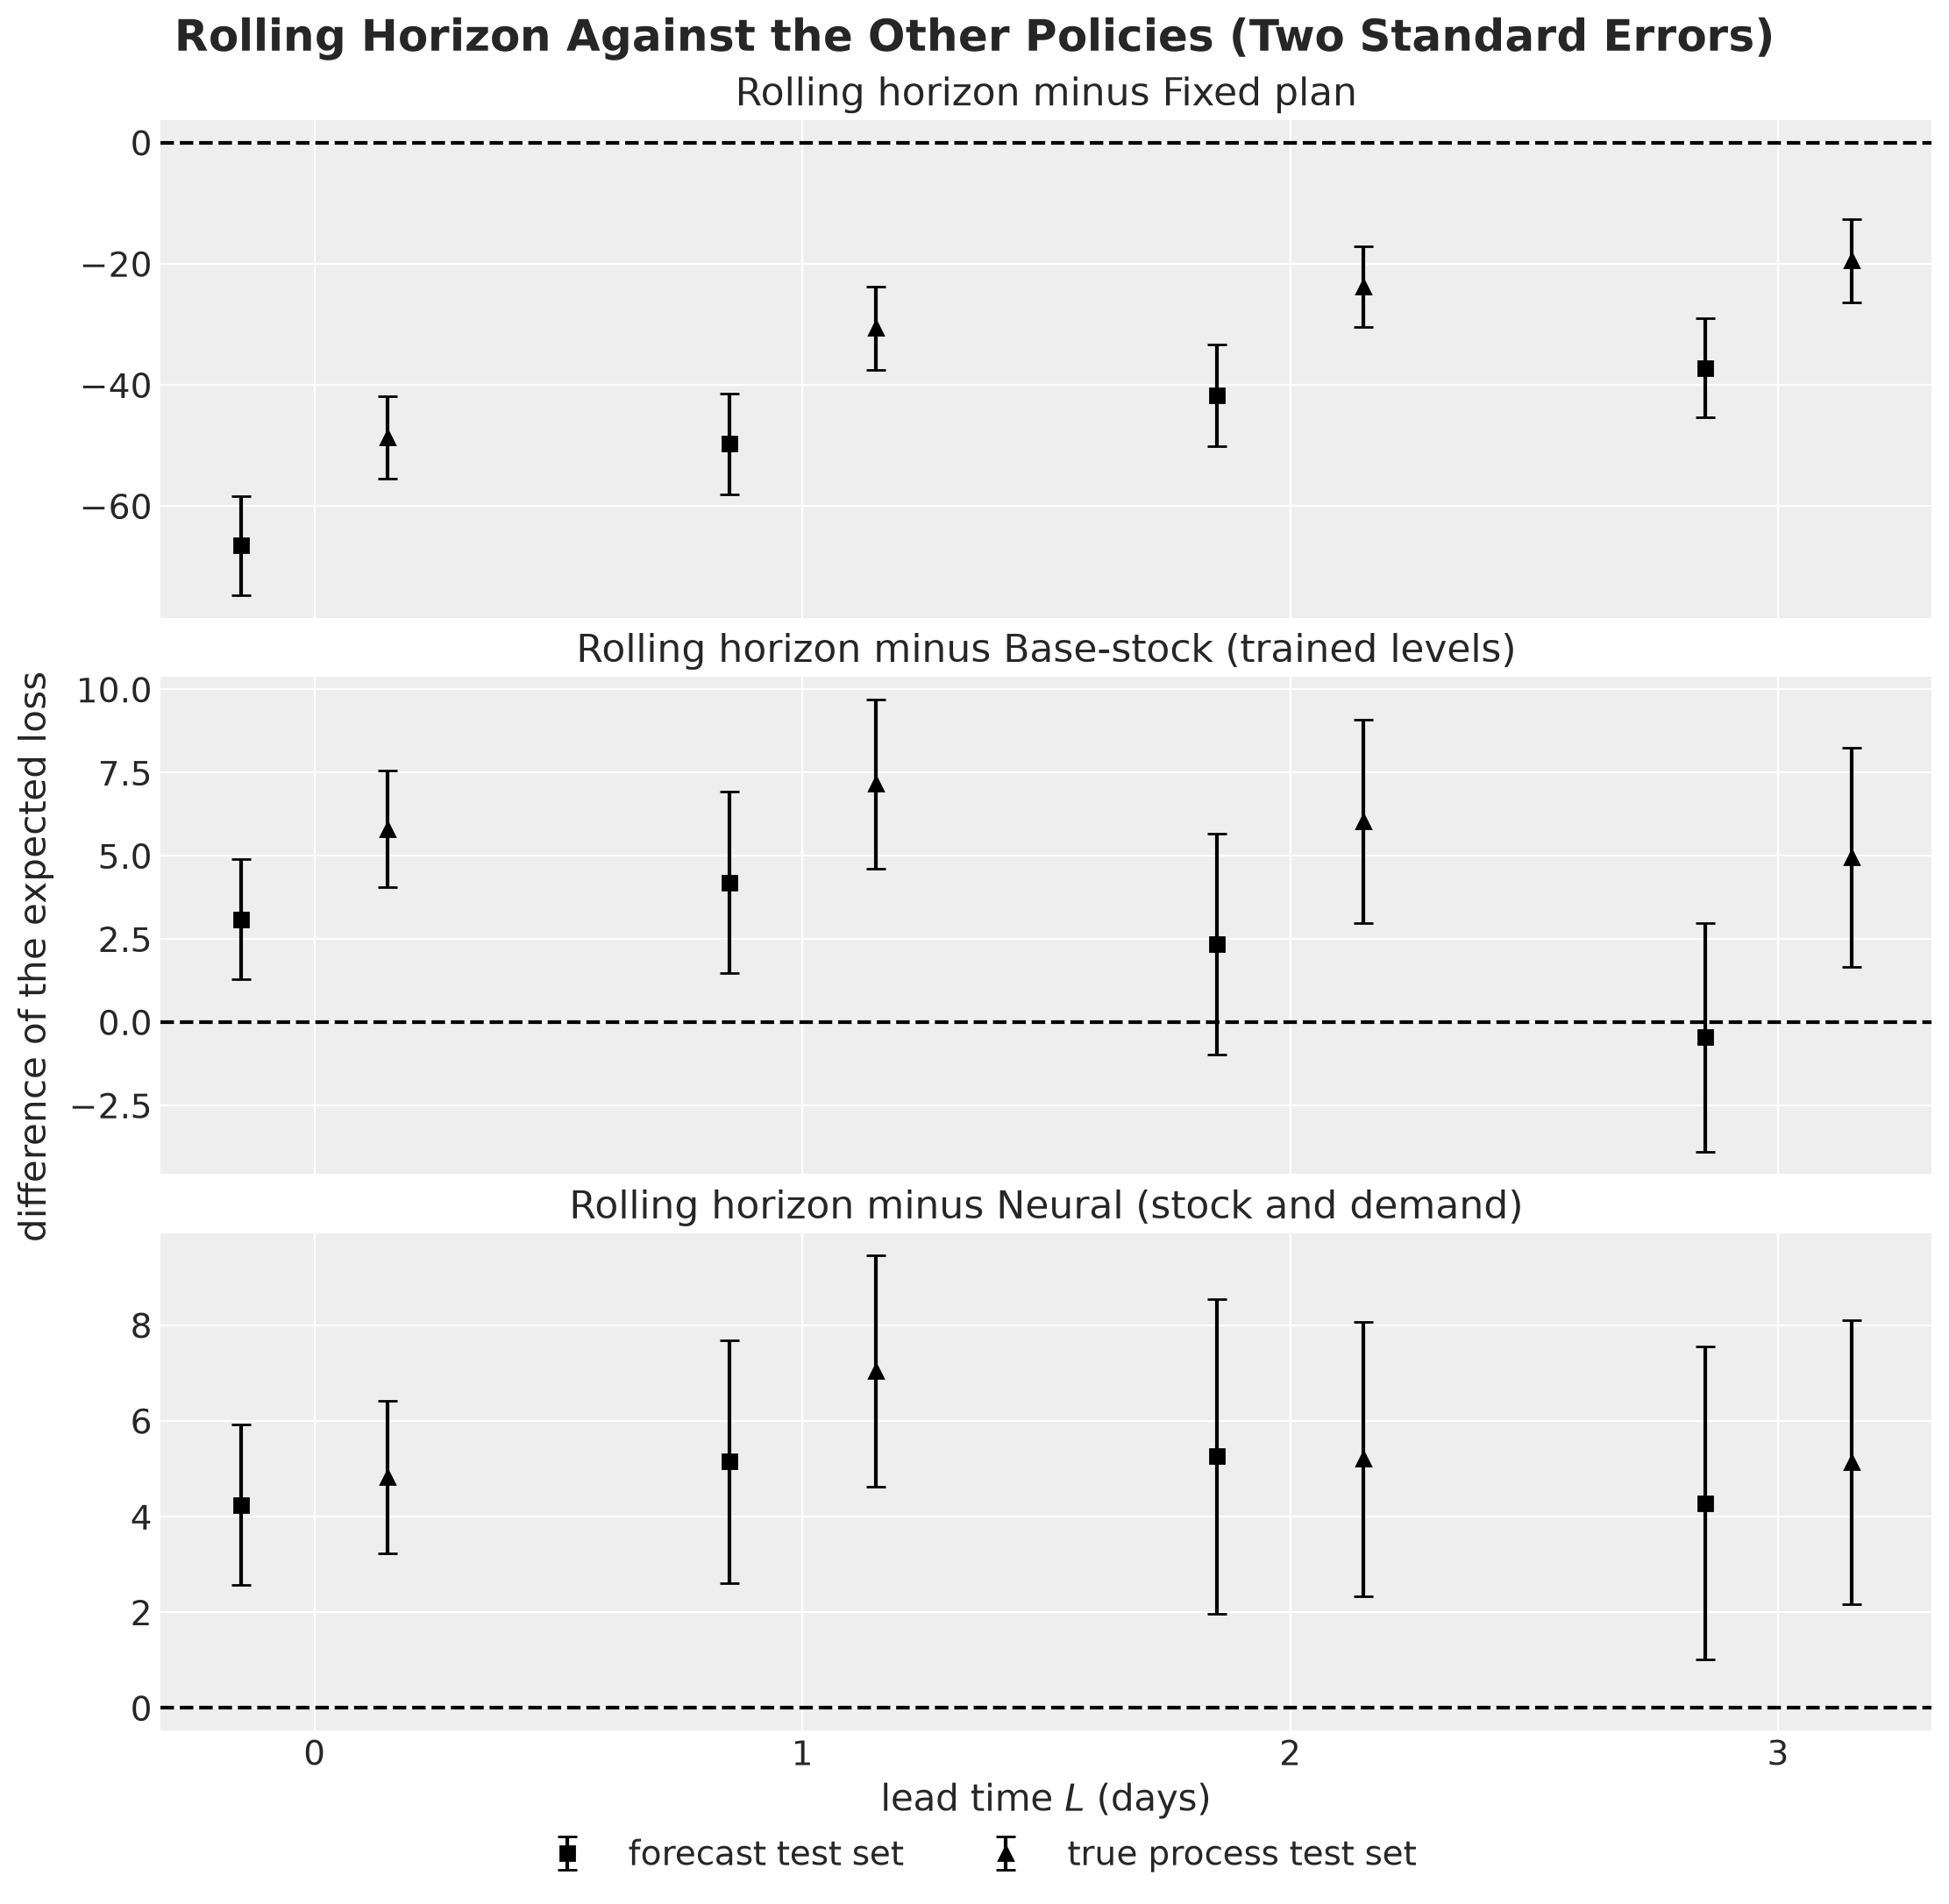

In [34]:
fig = plot_differences(
    [
        (PolicyName.ROLLING_HORIZON, PolicyName.FIXED_PLAN),
        (PolicyName.ROLLING_HORIZON, PolicyName.BASE_STOCK),
        (PolicyName.ROLLING_HORIZON, PolicyName.NEURAL),
    ],
    list(demand_test),
    num_scenarios=rolling_config.num_test,
)
fig.suptitle(
    "Rolling Horizon Against the Other Policies (Two Standard Errors)",
    fontsize=18,
    fontweight="bold",
);

Let's read the three panels from top to bottom.

- **Fixed plan.** The rolling horizon lowers the expected loss by $37$ to $67$ on the forecast test set. This is about nine tenths of what the neural policy removes on the same scenarios.
- **Base-stock (trained levels).** On the forecast test set the rolling horizon costs about $3$ and $4$ more for $L = 0$ and $L = 1$. For $L = 2$ and $L = 3$ the intervals contain zero, so we see no difference there. On the true process test set it costs $5$ to $7$ more at every lead time.
- **Neural (stock and demand).** The rolling horizon costs about $4$ to $5$ more on the forecast test set and $5$ to $7$ more on the true process test set, at every lead time.

So the answer to the third question is no, at least for this rolling horizon. It does not beat a trained policy in any of the $16$ comparisons of the two lower panels, and it costs more in $14$ of them.

### Stock and Stockouts

To see why the trained policies beat the fixed plan and the rolling horizon, we look at what each of them does with the stock. We stay with the lead time $L = 2$ and take the first $300$ scenarios of the forecast test set, so that the rolling horizon is on the same scenarios as the others. The next figure shows four of the scores.

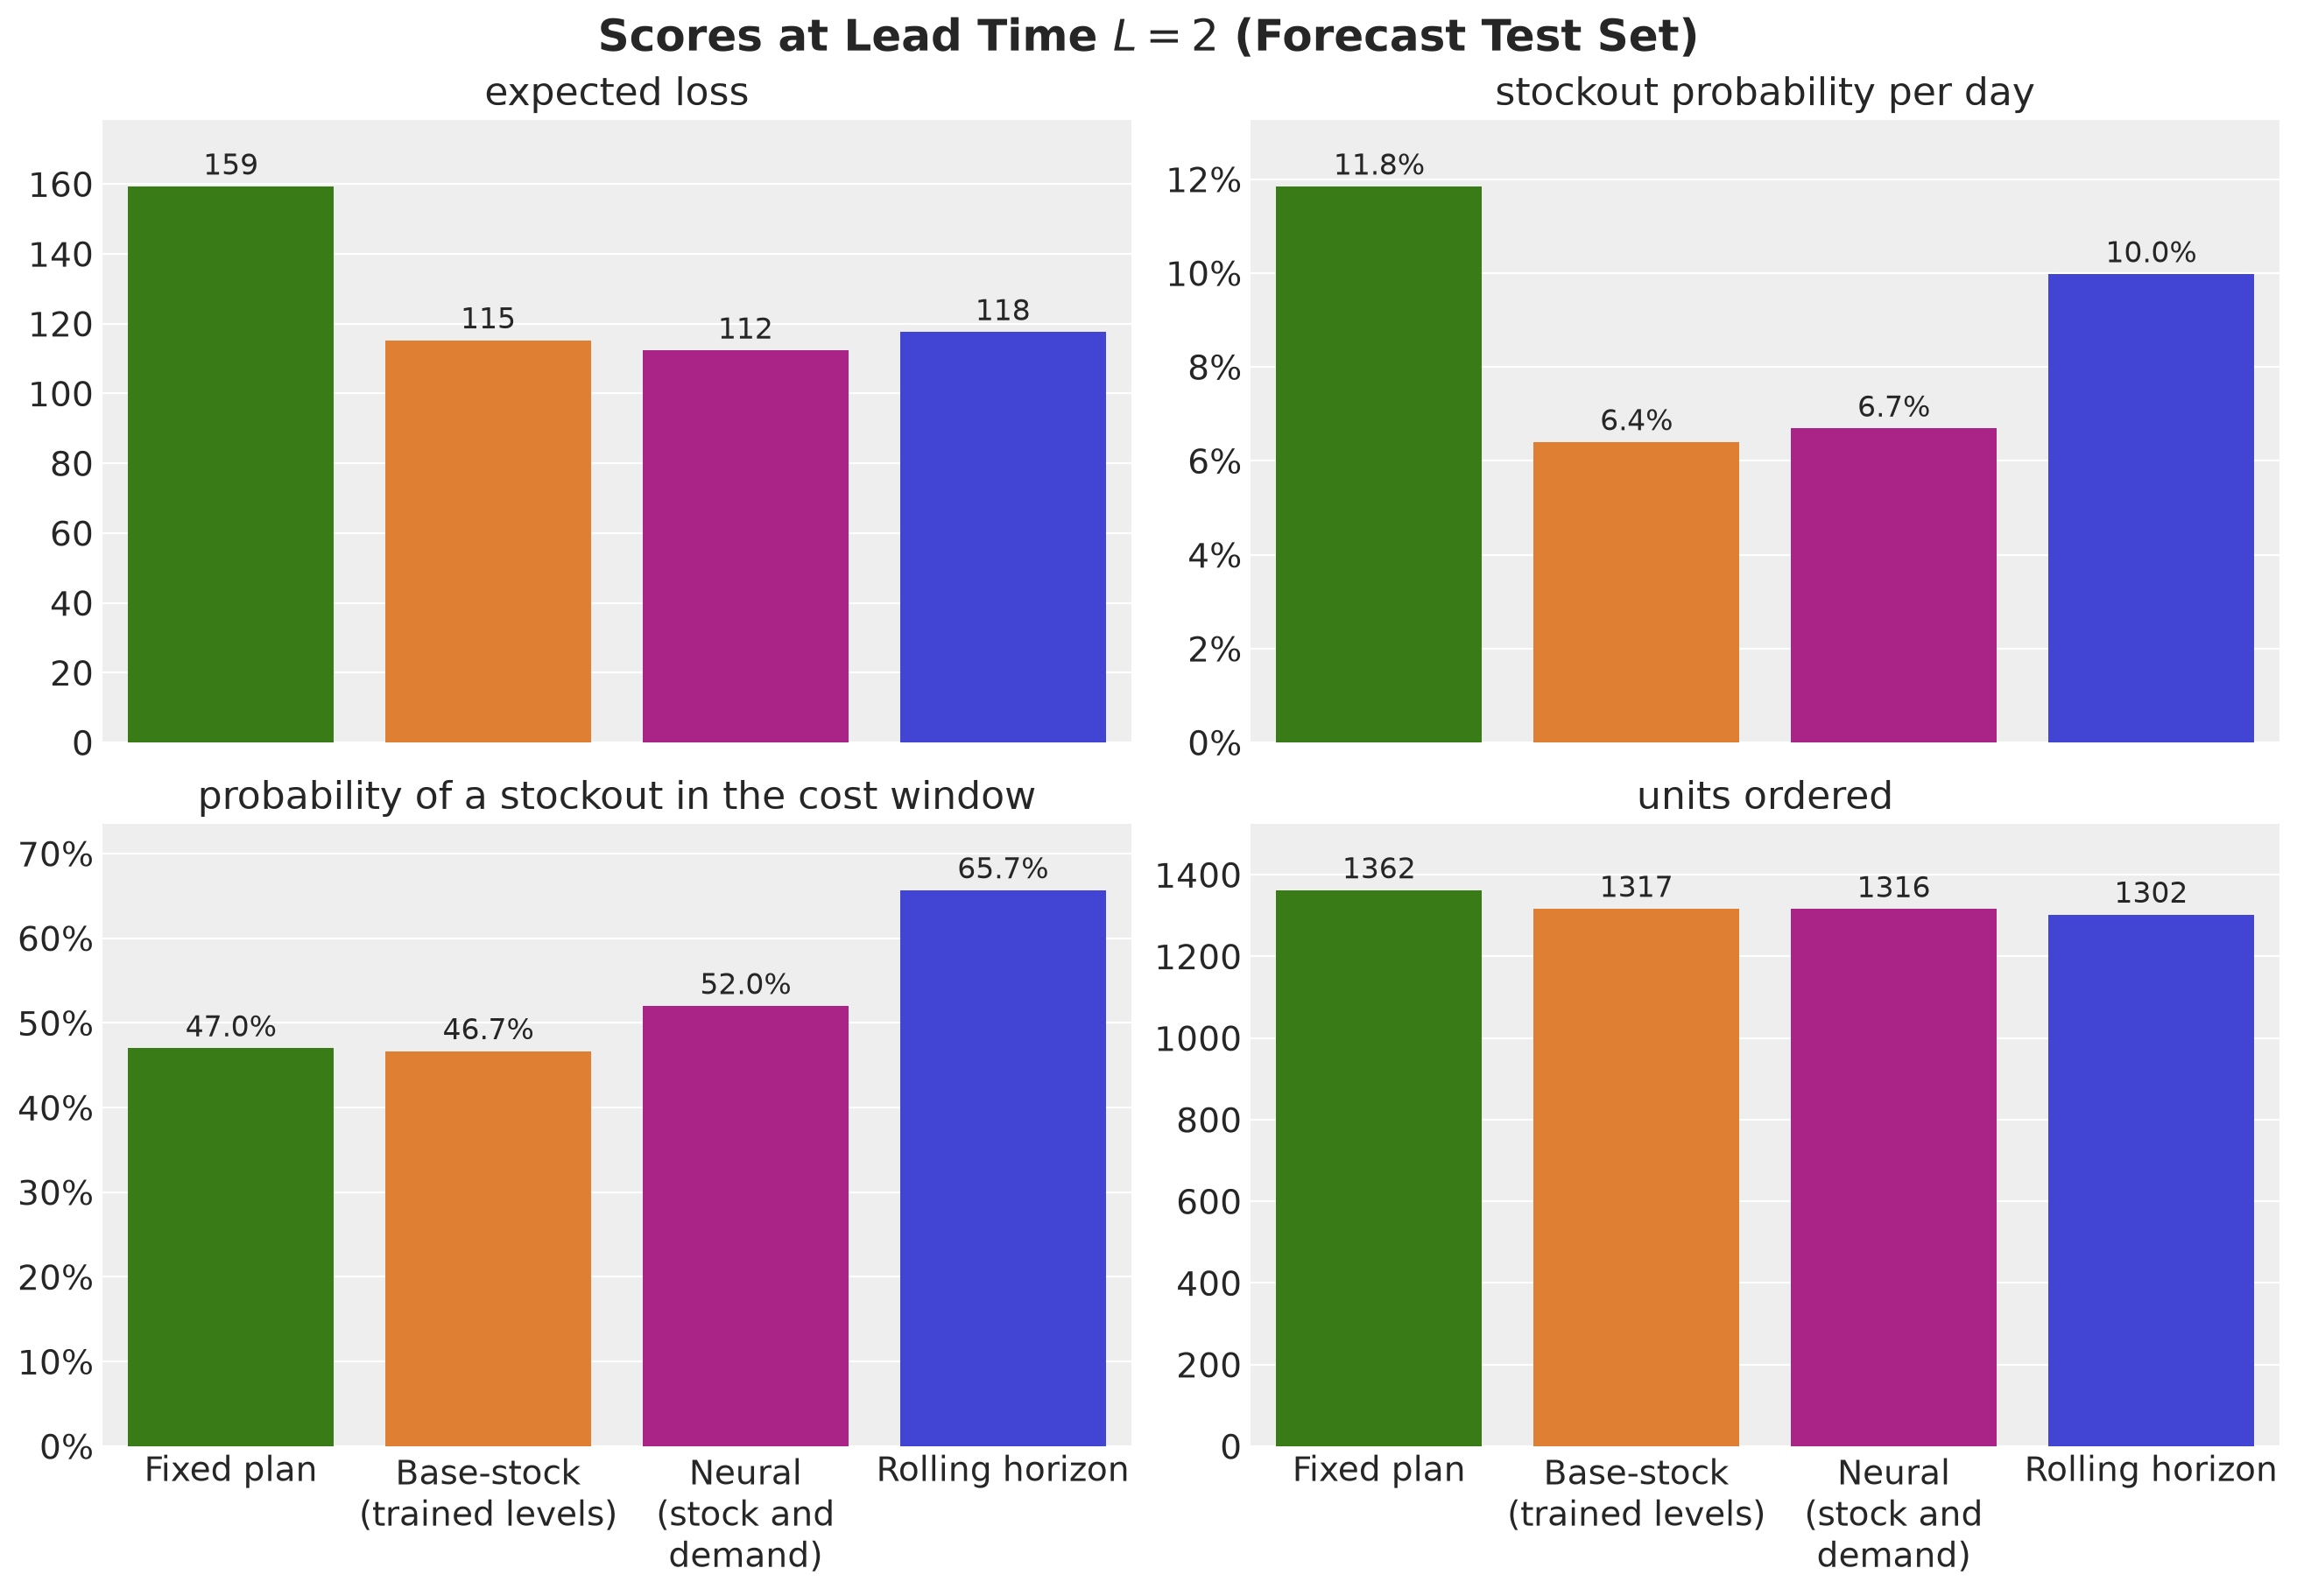

In [35]:
DETAIL_POLICIES = [
    PolicyName.FIXED_PLAN,
    PolicyName.BASE_STOCK,
    PolicyName.NEURAL,
    PolicyName.ROLLING_HORIZON,
]
# the first scenarios of the forecast test set, on which the rolling horizon ran
simulations_detail = {
    name: jax.tree.map(
        lambda leaf: leaf[: rolling_config.num_test],
        simulations[ScenarioSet.FORECAST, LEAD_TIME_DETAIL, name],
    )
    for name in DETAIL_POLICIES
}
results_detail = pl.DataFrame(
    [
        {"policy": str(name), **summarize(simulation, LEAD_TIME_DETAIL)}
        for name, simulation in simulations_detail.items()
    ]
)

fig, axes = plt.subplots(
    nrows=2, ncols=2, figsize=(13, 9), sharex=True, layout="constrained"
)

for ax, metric in zip(
    axes.flat,
    [Metric.EXPECTED_LOSS, Metric.STOCKOUT, Metric.WINDOW, Metric.ORDERED],
    strict=True,
):
    is_probability = metric in {Metric.STOCKOUT, Metric.WINDOW}
    sns.barplot(
        data=results_detail,
        x="policy",
        y=metric,
        hue="policy",
        palette=POLICY_COLORS,
        legend=False,
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt="{:.1%}" if is_probability else "{:.0f}",
            fontsize=12,
            padding=2,
        )

    if is_probability:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))

    ax.margins(y=0.12)
    ax.set(title=metric, xlabel="", ylabel="")

for ax in axes[-1]:
    # the names of the policies on two lines
    ax.set_xticks(
        range(len(DETAIL_POLICIES)),
        [
            name.replace(" (", "\n(").replace(" and ", " and\n")
            for name in DETAIL_POLICIES
        ],
    )

fig.suptitle(
    f"Scores at Lead Time $L = {LEAD_TIME_DETAIL}$ ({ScenarioSet.FORECAST.title()})",
    fontsize=18,
    fontweight="bold",
);

Let's go through the four policies.

- **Fixed plan.** It has the highest expected loss, $159$. It runs out on $11.8\%$ of the days, and it also orders the most, $1{,}362$ units on average.
- **Base-stock (trained levels).** Its expected loss is $115$. It runs out on $6.4\%$ of the days and orders about $45$ units less than the fixed plan.
- **Neural (stock and demand).** Its expected loss is $112$. It runs out on $6.7\%$ of the days, close to the base-stock policy, and it has at least one stockout in $52.0\%$ of the scenarios, against $46.7\%$.
- **Rolling horizon.** Its expected loss is $118$. It runs out on $10.0\%$ of the days, and in $65.7\%$ of the scenarios it has at least one day with a stockout. It orders the least.

The fixed plan orders more than the base-stock policy and still runs out more often. Its orders are the same in every scenario. So in the scenarios with low demand the units stay on the shelf, and in the scenarios with high demand they are missing.

The next figure shows the same four policies day by day: the mean order, the mean stock on hand at the end of the day and the stockout probability. The black lines mark the cost window, and the shaded days are the promotion week.

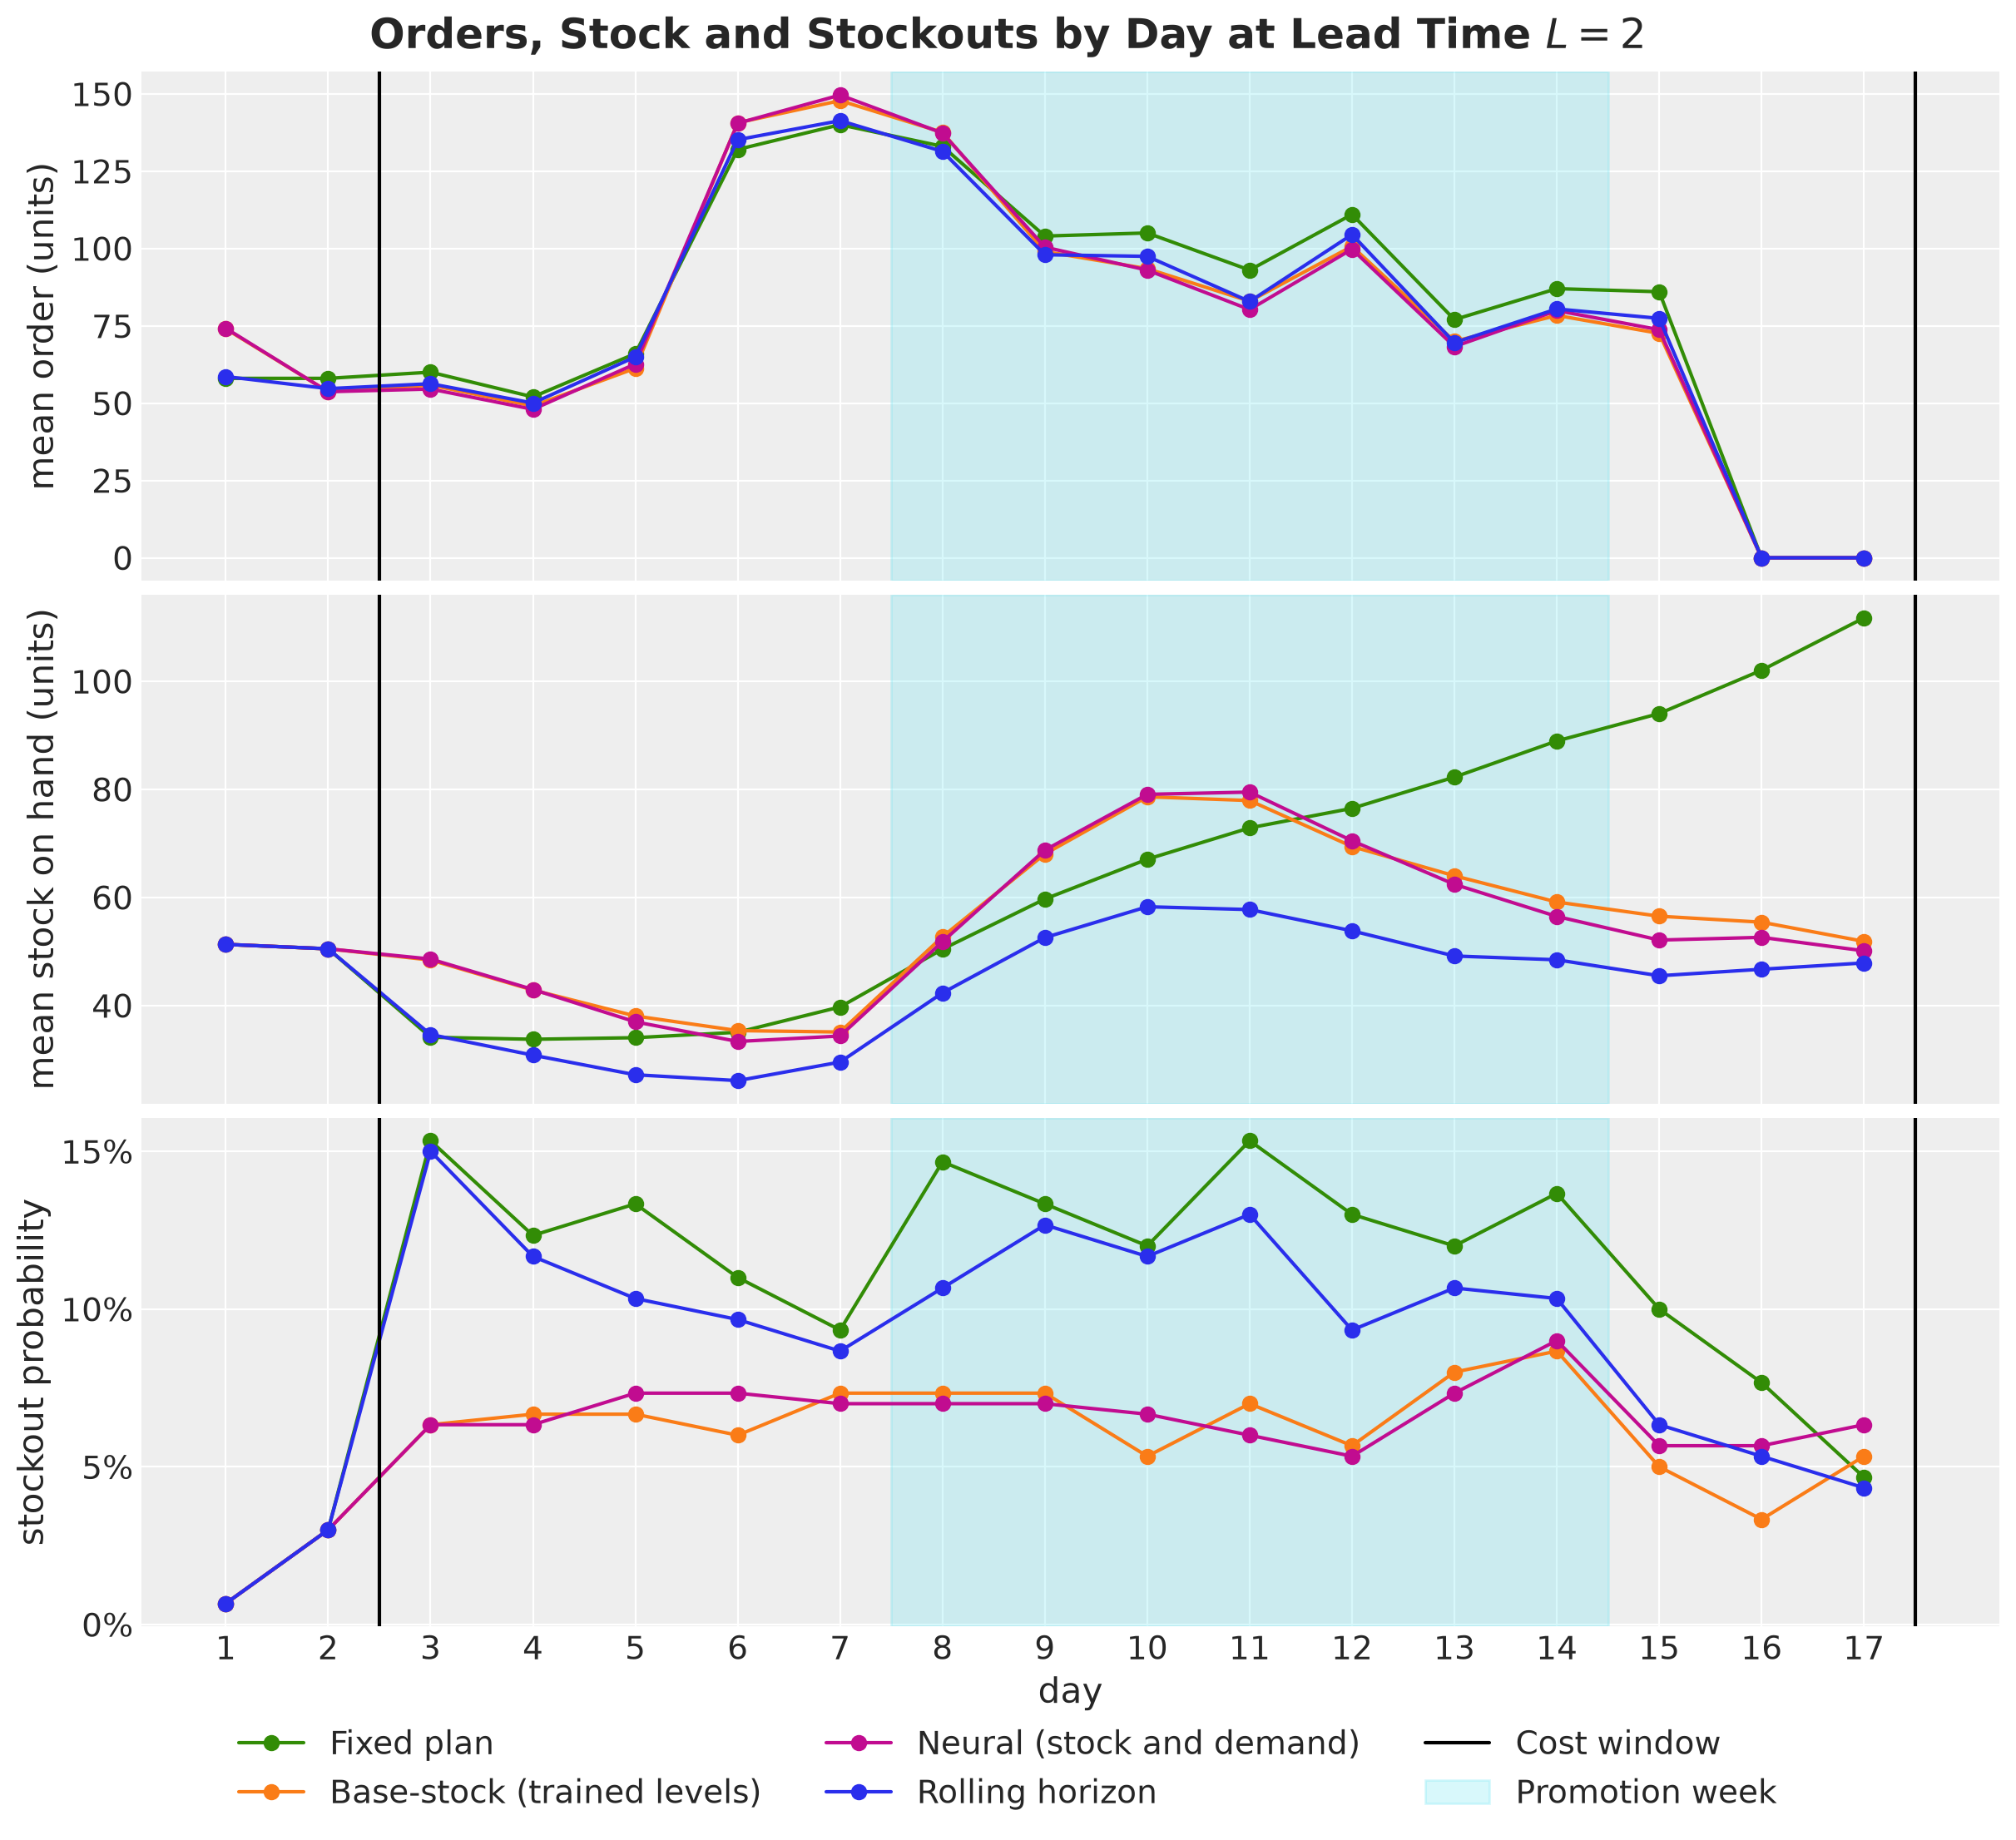

In [36]:
days_detail = np.arange(1, setup.horizon + LEAD_TIME_DETAIL + 1)

fig, axes = plt.subplots(nrows=3, figsize=(12, 11), sharex=True, layout="constrained")

for name, simulation in simulations_detail.items():
    for ax, values in zip(
        axes,
        [
            simulation.orders.mean(axis=0),
            simulation.inventory.mean(axis=0),
            (simulation.lost_sales > STOCKOUT_TOL).mean(axis=0),
        ],
        strict=True,
    ):
        ax.plot(days_detail, values, "o-", color=POLICY_COLORS[name], label=name)

for ax in axes:
    ax.axvline(LEAD_TIME_DETAIL + 0.5, color="black", label="Cost window")
    ax.axvline(days_detail[-1] + 0.5, color="black")
    shade_promotion(ax)

axes[0].set(ylabel="mean order (units)")
axes[1].set(ylabel="mean stock on hand (units)")
axes[2].yaxis.set_major_locator(MultipleLocator(0.05))
axes[2].yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes[2].set(xlabel="day", ylabel="stockout probability", xticks=days_detail)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3)
fig.suptitle(
    f"Orders, Stock and Stockouts by Day at Lead Time $L = {LEAD_TIME_DETAIL}$",
    fontsize=18,
    fontweight="bold",
);

We go policy by policy again.

- **Fixed plan.** The mean stock grows through the whole cost window and ends at $112$ units, more than three times its value on day $3$. The stockout probability stays between $9\%$ and $15\%$ until day $15$. The leftovers of the scenarios with low demand pile up, and the plan cannot lower a later order to use them.
- **Base-stock and neural policy.** Both order $74$ units on day one, $16$ more than the fixed plan. Their mean stock rises with the orders of the promotion week and comes back to about $50$ units. Their stockout probability stays between $3\%$ and $9\%$ on every day of the cost window.
- **Rolling horizon.** On day one it orders $59$ units on average, against $58$ for the fixed plan. On day $3$, when that order arrives, it runs out in $15\%$ of the scenarios, like the fixed plan and against $6\%$ for the two policies. From day $4$ on it holds the lowest mean stock of the four.

Here is an explanation that is consistent with these numbers. Each daily solve of the rolling horizon treats the remaining orders as fixed, although it will solve again on the next day. For a fixed plan a leftover unit is expensive, because it pays the holding cost on every later day until it sells, as we saw in the first post.

A policy orders less tomorrow if stock is left over today. So a leftover unit costs a policy less, and a larger order today is worth it. The order of day one shows this difference before the filter has observed any demand.

### Cost Ratio

Next, we check how much the answer to the first question depends on the costs. The lost margin $p = 2$ is $20$ times the holding cost. We train the fixed plan and the base-stock policy again with a lost margin of $0.5$ and of $8$. The cost ratios are then $p / h = 5$ and $p / h = 80$.

The base-stock levels start from the critical fractile of each ratio. The next figure shows the reduction of the expected loss of the trained base-stock policy relative to the fixed plan on the forecast test set.

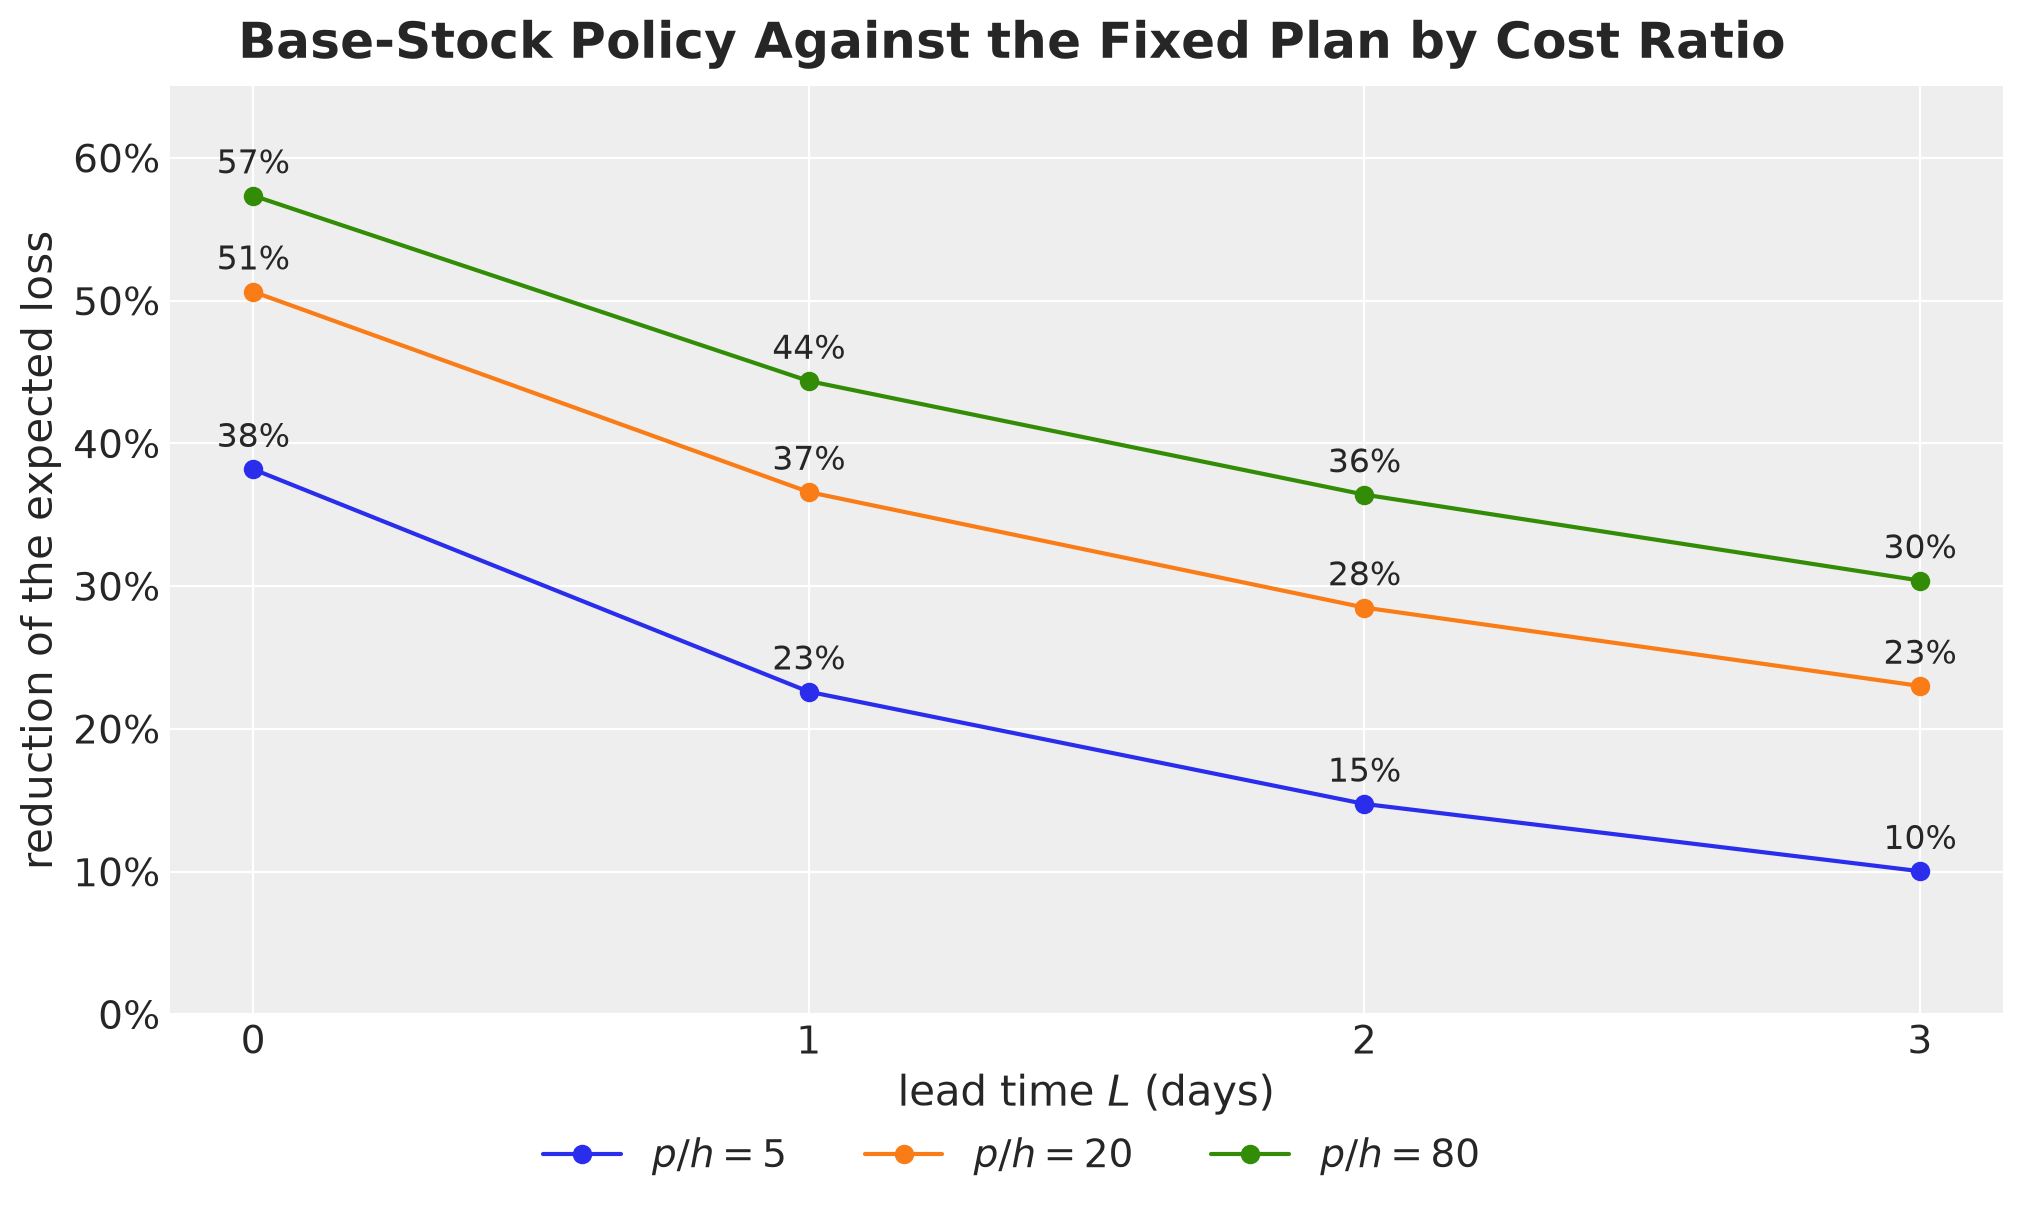

In [37]:
TRAIN_FUNCTIONS: dict[PolicyName, Callable[..., TrainedPolicy]] = {
    PolicyName.FIXED_PLAN: train_fixed_plan,
    PolicyName.BASE_STOCK: train_base_stock,
}
rows = []

for lost_sales_cost in [0.5, 2.0, 8.0]:
    config_sweep = config._replace(lost_sales_cost=lost_sales_cost)

    for lead_time in setup.lead_times:
        expected_loss = {
            name: float(
                simulate_scenarios_jit(
                    *train_policy(lead_time, config_sweep),
                    trim_demand(demand_test[ScenarioSet.FORECAST], lead_time),
                    initial_state(lead_time),
                    config_sweep,
                    lead_time,
                ).loss.mean()
            )
            for name, train_policy in TRAIN_FUNCTIONS.items()
        }
        rows.append(
            {
                "cost ratio": f"$p / h = {lost_sales_cost / config.holding_cost:g}$",
                "lead time": lead_time,
                "reduction": 1
                - expected_loss[PolicyName.BASE_STOCK]
                / expected_loss[PolicyName.FIXED_PLAN],
            }
        )

cost_sweep = pl.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 6))

for (ratio,), frame in cost_sweep.group_by("cost ratio", maintain_order=True):
    ax.plot(frame["lead time"], frame["reduction"], "o-", label=ratio)

    for lead_time, reduction in zip(
        frame["lead time"], frame["reduction"], strict=True
    ):
        ax.annotate(
            f"{reduction:.0%}",
            (lead_time, reduction),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=12,
        )

ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.set(
    xlabel="lead time $L$ (days)",
    ylabel="reduction of the expected loss",
    xticks=setup.lead_times,
    ylim=(0, 0.65),
)
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle(
    "Base-Stock Policy Against the Fixed Plan by Cost Ratio",
    fontsize=18,
    fontweight="bold",
);

The reduction is larger when a lost sale is more expensive: for $L = 0$ it is $38\%$ for the smallest ratio and $57\%$ for the largest. For every ratio it shrinks with the lead time, to between $10\%$ and $30\%$ for $L = 3$.

So the answer to the first question holds for the three ratios, and its size depends on the costs. With a cheap lost sale and a lead time of three days the base-stock policy removes a tenth of the loss of the fixed plan.

### Tail Risk

Finally, we look at the tail of the loss. Recall that the CVaR is the mean of the worst $5\%$ of the scenario losses, here $150$ of $3{,}000$. In the first post the CVaR plan gave up some expected loss for a lower CVaR, and the tail weight $\lambda$ traced a **frontier**: the plans for which we cannot lower one of the two without raising the other.

We can train a policy with the same objective. We train the fixed plan and the base-stock policy for six tail weights at $L = 2$ and score them on the forecast test set.

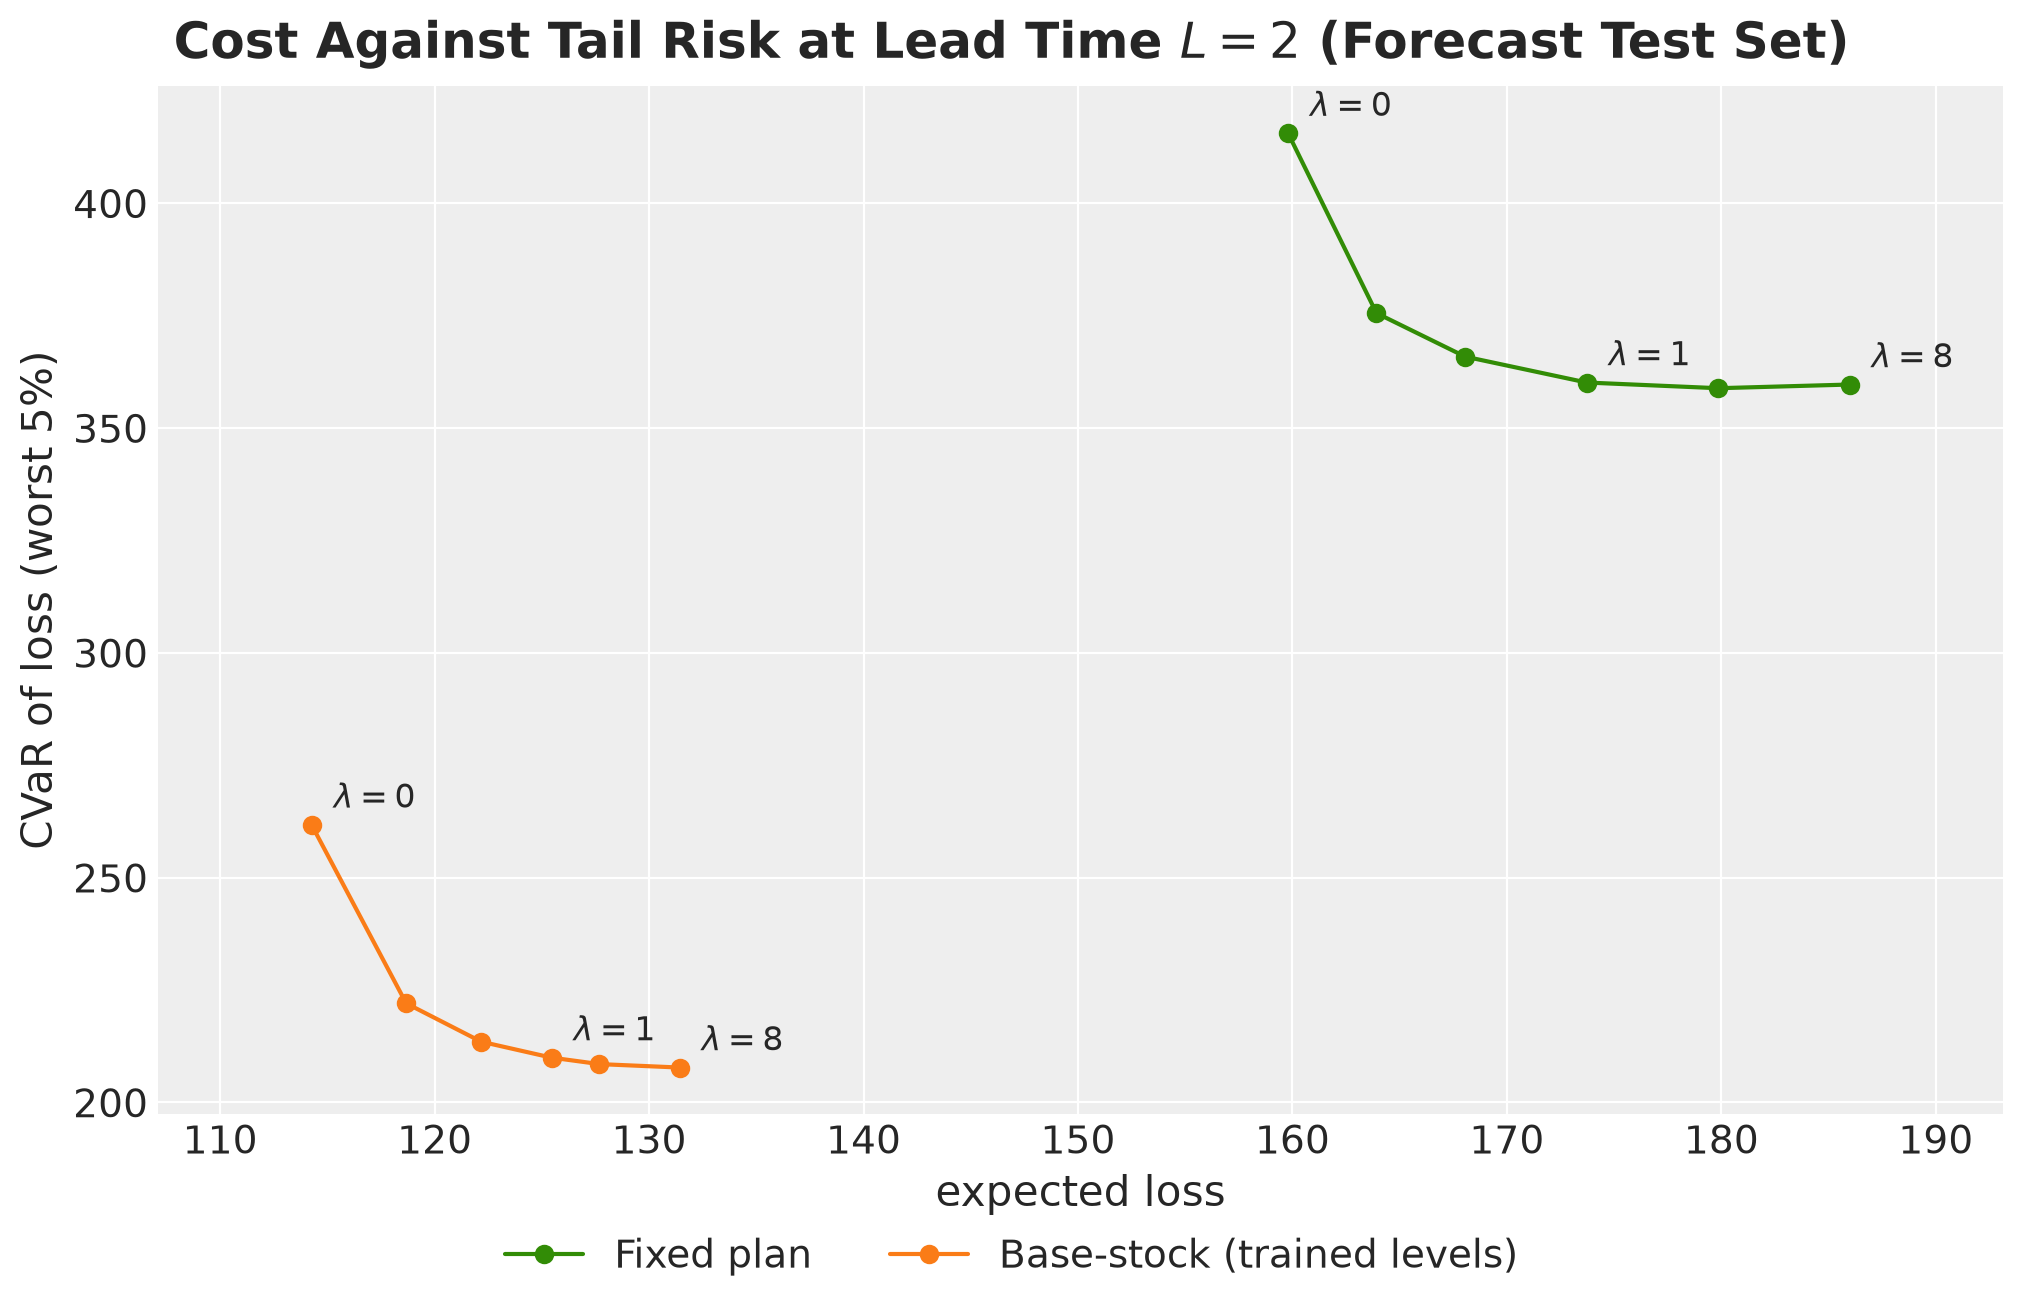

In [38]:
TAIL_WEIGHTS = [0.0, 0.25, 0.5, 1.0, 2.0, 8.0]
rows = []

for name, train_policy in TRAIN_FUNCTIONS.items():
    for tail_weight in TAIL_WEIGHTS:
        simulation = simulate_scenarios_jit(
            *train_policy(LEAD_TIME_DETAIL, config, tail_weight),
            trim_demand(demand_test[ScenarioSet.FORECAST], LEAD_TIME_DETAIL),
            initial_state(LEAD_TIME_DETAIL),
            config,
            LEAD_TIME_DETAIL,
        )
        rows.append(
            {
                "policy": str(name),
                "tail weight": tail_weight,
                **summarize(simulation, LEAD_TIME_DETAIL),
            }
        )

frontier = pl.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 6.5))

for (name,), frame in frontier.group_by("policy", maintain_order=True):
    ax.plot(
        frame[Metric.EXPECTED_LOSS],
        frame[Metric.CVAR],
        "o-",
        color=POLICY_COLORS[name],
        label=name,
    )

    for row in frame.filter(pl.col("tail weight").is_in([0.0, 1.0, 8.0])).iter_rows(
        named=True
    ):
        ax.annotate(
            rf"$\lambda={row['tail weight']:g}$",
            (row[Metric.EXPECTED_LOSS], row[Metric.CVAR]),
            textcoords="offset points",
            xytext=(8, 6),
            fontsize=12,
        )

ax.set(xlabel=Metric.EXPECTED_LOSS, ylabel=Metric.CVAR)
ax.margins(x=0.1)
fig.legend(loc="outside lower center", ncol=2)
fig.suptitle(
    f"Cost Against Tail Risk at Lead Time $L = {LEAD_TIME_DETAIL}$ "
    f"({ScenarioSet.FORECAST.title()})",
    fontsize=18,
    fontweight="bold",
);

Let's compare the two frontiers.

- **Fixed plan.** With $\lambda = 0$ the expected loss is about $160$ and the CVaR about $416$. With $\lambda = 8$ they are about $186$ and $360$. Most of the reduction of the CVaR comes with the first tail weights, as in the first post.
- **Base-stock (trained levels).** The frontier has the same shape. With $\lambda = 0$ the two values are about $114$ and $262$, and with $\lambda = 8$ about $131$ and $208$.

The whole frontier of the base-stock policy lies below and to the left of the frontier of the fixed plan. Trained for the expected loss alone, the base-stock policy has a CVaR of about $262$, and the lowest CVaR of the fixed plan over the six tail weights is about $359$.

This is what we expect. A fixed plan loses the most when the demand moves away from the plan, and the base-stock policy changes its orders when that happens.

## Conclusion

### Key Findings

The first four findings answer the three questions of the introduction.

- **Orders that depend on the stock.** With no lead time a base-stock policy at the newsvendor levels has about half of the expected loss of the fixed plan, $70$ against $141$ on the forecast test set. It needs a quantile of the scenarios and no optimizer. The fixed plan orders more units and still runs out more often, because its orders are the same in every scenario.
- **Lead time.** The gain is smaller for every extra day of lead time, about a quarter of the loss of the fixed plan for $L = 3$ with trained levels. With a lead time the newsvendor levels are too high, and training them through the simulator lowers the expected loss by $1$ to $9$.
- **Demand history.** A network that also sees the demand of the last week lowers the expected loss by about $1$ to $2$ on scenarios from the forecast. The gain is in the scenarios far from the center of the forecast. On scenarios from the true process, which is close to that center, there is none, and for $L \leq 2$ the demand history costs up to about $1$.
- **Rolling horizon.** A daily update of the forecast followed by a new solve of the fixed plan lowers the expected loss of the fixed plan by $37$ to $67$ on the forecast test set, about as much as the trained policies do. It does not beat the trained base-stock policy at any lead time, and it costs more in most of our comparisons. A possible reason is that each daily solve treats the remaining orders as fixed.
- **Tail risk.** For $L = 2$ the base-stock policy trained for the expected loss alone has a lower CVaR than the fixed plan with any of our tail weights.
- **One simulator and one trainer.** We train the fixed plan, the base-stock levels and the network with the same function, with the gradient from `jax.grad` through the `jax.lax.scan` of the simulator.

### Model Limitations

- **Observed demand.** We observe the demand of a day even when the shelf was empty. In practice the history is sales, which are censored on those days, see [Caron (2023)](https://kylejcaron.github.io/posts/censored_demand/2024-02-06-censored-demand.html) and the [censored demand example](https://juanitorduz.github.io/numpyro_forecast/docs/examples/censored_demand.html) of `numpyro_forecast`. The neural policy and the particle filter would learn less from censored sales.
- **One forecast origin.** Every scenario starts from the same history, the same initial stock and the same promotion calendar, so the levels and the network are specific to these $15$ days. A policy for daily use has to be trained over many forecast origins.
- **One data set and one truth.** The results come from one synthetic series. The true process test set uses one set of true parameters, which is close to the center of the posterior. So we cannot extend the missing gain of the demand history on that set to another truth.
- **Well-specified forecast.** The forecasting model has the structure of the generator. With a misspecified forecast the scenarios, the levels and the filter are wrong in the same direction, and we did not study that case.
- **Design of the rolling horizon.** Our rolling horizon solves a fixed plan every day on $1{,}000$ scenarios, and it never refreshes the parameter draws of its particles. We ran it on $300$ scenarios per test set, so its comparisons have wide error bars. A rolling horizon that orders up to a quantile of the updated forecast, or that solves for a policy, is a different method that we did not test.
- **Small samples for small differences.** The validation set has $1{,}000$ scenarios from $200$ posterior draws, and the gains of the network are of the order of its Monte Carlo error. The error bars of the paired differences are for one training run of each network. The CVaR is a mean of $150$ losses.
- **Costs and lead time.** The lead time is known and the same for every order, the costs are linear and the orders are continuous. Order minimums, fixed ordering costs and uncertain lead times change the simulator.

### Recommendations

1. **Start with a base-stock policy.** Order up to the $p / (p + h)$ quantile of the total demand of the next $L + 1$ days, from the stock on hand plus the pipeline. It needs the scenarios and a quantile.
2. **Train the levels when there is a lead time.** Training the levels through the simulator lowered the expected loss by about $4$ and $9$ for $L = 2$ and $L = 3$.
3. **Measure before adding a network or a daily refit.** Compare the candidates on the same held-out scenarios, look at the paired difference with its Monte Carlo error, and check how the gain depends on where the truth can lie inside the forecast.
4. **Do not place the first order of a fixed plan every day.** If you update the forecast daily, combine the update with an order rule for one day, such as a base-stock level, in place of a plan for all the remaining days. We did not test this combination, see the *Next Steps* section.

## Next Steps

1. **Rolling horizon with a base-stock level.** Replace the daily solve of a fixed plan by base-stock levels computed from the updated forecast, and compare the result with the neural policy. That comparison tells us how much of the daily update the network has learned from the scenarios.
2. **Censored demand.** Train the policies on sales, with a censored likelihood in the forecasting model and in the weight step of the filter.
3. **Many forecast origins.** Train one policy on the scenarios of the forecast origins of a rolling backtest, with the forecast of each origin among its features, so that it can be used every day.
4. **Many products.** Share a capacity between the products of a store, and let the policy return the orders of all the products.

## References

- Orduz, J. (2026). [From Forecasts to Decisions: Inventory Planning with Probabilistic Programming](https://juanitorduz.github.io/forecast_to_decision/). Personal blog.
- Alvo, M., Russo, D., Kanoria, Y. and Lee, M. (2023). [Deep Reinforcement Learning for Inventory Networks: Toward Reliable Policy Optimization](https://arxiv.org/abs/2306.11246). arXiv:2306.11246.
- Zipkin, P. (2008). [Old and New Methods for Lost-Sales Inventory Systems](https://doi.org/10.1287/opre.1070.0471). *Operations Research*, 56(5), 1256-1263.
- Bijvank, M. and Vis, I. F. A. (2011). [Lost-sales inventory theory: A review](https://doi.org/10.1016/j.ejor.2011.02.004). *European Journal of Operational Research*, 215(1), 1-13.
- Huh, W. T., Janakiraman, G., Muckstadt, J. A. and Rusmevichientong, P. (2009). [Asymptotic Optimality of Order-Up-To Policies in Lost Sales Inventory Systems](https://doi.org/10.1287/mnsc.1080.0945). *Management Science*, 55(3), 404-420.
- Gijsbrechts, J., Boute, R. N., Van Mieghem, J. A. and Zhang, D. J. (2022). [Can Deep Reinforcement Learning Improve Inventory Management? Performance on Lost Sales, Dual-Sourcing, and Multi-Echelon Problems](https://doi.org/10.1287/msom.2021.1064). *Manufacturing & Service Operations Management*, 24(3), 1349-1368.
- Doucet, A. and Johansen, A. M. (2011). [A Tutorial on Particle Filtering and Smoothing: Fifteen Years Later](https://www.stats.ox.ac.uk/~doucet/doucet_johansen_tutorialPF2011.pdf). In *The Oxford Handbook of Nonlinear Filtering*. Oxford University Press.
- Szabłowski, B. (2026). [One Global Model, Many Behaviors: Stockout-Aware Feature Engineering and Dynamic Scaling for Multi-Horizon Retail Demand Forecasting with a Cost-Aware Ordering Policy (VN2 Winner Report)](https://arxiv.org/abs/2601.18919). arXiv:2601.18919.
- Caron, K. (2023). [Modeling Anything With First Principles: Demand under extreme stockouts](https://kylejcaron.github.io/posts/censored_demand/2024-02-06-censored-demand.html). Personal blog.
- Orduz, J. [NumPyro Forecast documentation](https://juanitorduz.github.io/numpyro_forecast/).
- DeepMind. [Optax documentation](https://optax.readthedocs.io/).